# TP2 — Détection du sarcasme en arabe
## Version de présentation : 40 cellules de code

Parcours simplifié : configuration → données → modèles A–E → robustesse → comparaison finale.

Le code original est regroupé dans son ordre initial, sans changer les expériences.
Les sorties affichées proviennent du notebook exécuté original : cette version regroupée
n’a pas été réexécutée. Les compteurs sont effacés pour éviter toute confusion.
Une exécution complète peut télécharger des ressources et entraîner les modèles.

| Partie | Cellules de code | À présenter |
|---|---:|---|
| 0. Configuration | 3 | Bibliothèques, GPU, seed, paramètres |
| 1. Dataset et prétraitement | 5 | Données, classes, nettoyage, collisions |
| A. Baseline TF-IDF | 3 | TF-IDF, régression logistique, F1 |
| B. Zero-shot | 3 | NLI, sentiment, comparaison |
| C. Deep Learning | 5 | BiLSTM, attention, Transformer, AraVec |
| D. BERT gelé | 4 | CLS, mean pooling, BiLSTM-attention |
| E. Fine-tuning | 6 | AraBERT, MARBERT, E1/E2, lambda |
| F. Robustesse | 7 | Dialectes, ablations, bootstrap, erreurs |
| G. Comparaison finale | 4 | F1, coût, choix final, prédictions |
| **Total** | **40** | **Couverture globale du projet** |


## 0. Configuration

### Bibliothèques et chemins

**1. Explication**

**Objectif :** Préparer les bibliothèques et retrouver les ressources du projet.

**Pourquoi cette méthode ?** Centraliser les chemins permet de travailler en local ou dans Colab.

**2. Code — Implémentation**

La cellule suivante réalise cette étape.

In [ ]:
_TP2_TABLE_TITLES = []

from pathlib import Path

import os, sys, re, json, time, random, hashlib, gc, math, copy, platform, warnings

IN_COLAB = bool(os.environ.get('COLAB_RELEASE_TAG')) or Path('/content').is_dir()

if IN_COLAB:
    print('TP2_COLAB_BOOTSTRAP_V2 — préparation compatible Python 3.13',flush=True)
    from importlib.metadata import version, PackageNotFoundError
    import subprocess
    # Copie autonome des dépendances, synchronisée avec requirements-colab.txt.
    COLAB_REQUIREMENTS = ['transformers==4.48.0', 'huggingface-hub==0.29.1', 'safetensors==0.5.3', 'tokenizers==0.21.0', 'gensim==4.4.0', 'arabert==1.0.1', 'pyarabic==0.6.15', 'emoji==1.4.2', 'sentencepiece==0.2.1', 'nbformat==5.9.2', 'reportlab==5.0.1', 'pymupdf==1.28.2', 'requests==2.32.3', 'pyflakes==3.0.1']
    missing=[]
    for specification in COLAB_REQUIREMENTS:
        package,wanted=specification.split('==',1)
        try: installed=version(package)
        except PackageNotFoundError: installed=None
        if installed!=wanted: missing.append(specification)
    if missing:
        print('Préparation Colab — Python',sys.version.split()[0],':',', '.join(missing),flush=True)
        # Ces extensions doivent avoir une wheel : éviter une compilation C++/Rust.
        command=[sys.executable,'-m','pip','install','--disable-pip-version-check',
                 '--progress-bar','off',
                 '--only-binary=safetensors,tokenizers,gensim,sentencepiece,pymupdf',*missing]
        installation=subprocess.run(command,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,
                                    text=True,errors='replace')
        print(installation.stdout,flush=True)
        if installation.returncode:
            raise RuntimeError(f"Échec de pip (code {installation.returncode}). "
                               "Copier les lignes ERROR affichées ci-dessus pour le diagnostic. "
                               "Ne pas poursuivre les cellules scientifiques.")
        raise RuntimeError('Installation terminée : redémarre le noyau Colab puis relance depuis la première cellule.')

CPU_THREADS=min(2,os.cpu_count() or 1) if IN_COLAB else 6  # 12 testés : gain forward limité, backward non mesuré.
os.environ['OMP_NUM_THREADS']=str(CPU_THREADS)
os.environ['MKL_NUM_THREADS']=str(CPU_THREADS)
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG',':4096:8')
os.environ['USE_TF']='0'
os.environ['USE_FLAX']='0'
from collections import Counter

from datetime import datetime, timezone

import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

from IPython.display import display, Markdown, HTML

import torch

from torch import nn

from torch.utils.data import DataLoader, TensorDataset, WeightedRandomSampler, RandomSampler, BatchSampler

from sklearn.model_selection import train_test_split

from sklearn.metrics import (f1_score, precision_score, recall_score, accuracy_score,
    average_precision_score, confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve)

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.pipeline import FeatureUnion, Pipeline

from sklearn.linear_model import LogisticRegression

import joblib

import emoji

warnings.filterwarnings('ignore',message='This pattern is interpreted as a regular expression, and has match groups')

from transformers import AutoTokenizer, AutoModel, AutoModelForSequenceClassification

from transformers import get_linear_schedule_with_warmup, set_seed

# TP2_LAYOUT
ROOT = Path(os.environ.get('TP2_ROOT',Path.cwd())).resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
if IN_COLAB and not (ROOT/'data/raw/training_data.csv').is_file() and 'TP2_ROOT' not in os.environ:
    candidates=[p for p in ROOT.iterdir() if p.is_dir() and (p/'src/preprocess.py').is_file()]
    ROOT=candidates[0] if len(candidates)==1 else Path('/content/TP2_ArSarcasme')
if IN_COLAB:
    import base64, io, zipfile
    BOOTSTRAP_ARCHIVE = 'UEsDBBQAAAAIAL25UV0AAAAAAgAAAAAAAAAPAAAAc3JjL19faW5pdF9fLnB5AwBQSwMEFAAAAAgAvblRXSsRn7MgAwAAvAYAABEAAABzcmMvcHJlcHJvY2Vzcy5weY1UzW7TQBC+R8o7TOlhbZG4pMegAKEUiKAtauGUBGuxJ8lSe73aXRNKQeKG+Dlw4sAFCYRQDyB4hr5EIl6GsZ3mr5VCJNuT3ZlvZr75WYc7pyfy9ESfnoDiGtSRHSQSqjEYHXjmSAYQokqFgQhBJhafJMkhXIU4CUVPoJ4/9solEatEW9BYgYGNowqkUgRJiCG3fHqLcfJUlEu3Ws0taJCuFySxEhE6mrVHH6ujz+P31fGX8e+/n6p/f3aZWy492r/v728vKw+sVeZ6fWOjc3D55XA47HgksEqm1CKjne3dh6293QsMb7Q7Q797OUNu7jdvtrb8neYDUjJWezE/RKu5NM4xG31jdTb6wSps9H0qfT2Txn+m0luSxu/YKwIMsQf4PMvTDyLk0rH43Lr1cgnol8nkZ44UTyY65pF4gQ7bvb3FCt68VKIJuEKHQioQXNcjWSjHLaDW4ZFEMJhSARQXGsmrpToKTEluHmy1WlQmmV0aMKlSWsR5uQwEwnIrEmlASIuaXFGNIWI8tWTsFfiiR7qT6K/VgMswj56C4NqaobADh11i7uwCZTg7nuQ7l3P2adfq1Vp3MQ+NNtUyq49Jn2Qd0Ek3r1zB/N3L3pu8mn/oqIe9XpcoYvTkgZVLBeFhqiIRcIv+IR4tML4M3zFZhzCgV9Z/+SnBna+Y62lUEQ+oLuPXVGPmenlbROTFmXXNfFmKWBTZcY1+hpJDVbJhwQYLiHHUz4j6Z0juQ50oPxLy0DRu88jgUo+cj2halwwO1hrAVBSz80zP55Ub/mcmC+6LiStgiC7yOosXkMKlQ9J5uHdvexcmfhYAZtO3AuRge/8ClLM0G5Qm7/c1GpPRdj7bfJl4fbR+Lvka+0Sd4555nQedM5s2xPjN8Wbl1cvRr+xz1horbBzP7dQm+tRStdUW7cedYcd0L8Bfh7vcDCzvG6gDtYhFmcKkVWgn0wgL2kuJGiY6NMUfjGMh++DQ2u7ng7wRCh5hYGnYaY8Xlsb1Vk1A0RxL7YuaG/SDFM1Fm2sl27N9tWD333QvR+u0166PvnijD12ifCHwcukfUEsDBBQAAAAIAL25UV35nQvYgQMAAGwJAAAXAAAAc3JjL2FyYXZlY191dGlsaXRpZXMucHnNVklv4zYUvutXvMhAJSGyYqcb0IEnnRYY9NIeirmZqqDItMNGolSSjqdz6q2p0f8QoEUR9B/Z/6aPi7Zs6KVAjfCR4lv5vQWZwOK5nzcxPPiGlg0V8C1VV/VKWnmPVU0tFAjanvi2an6GXAJvvLWoK+CluoaWuRF5JT20+HVJc372XS2qvGQfKLwR+SUr4B19r7wVXUOh+ZlUIlR4FX3hAf4kzUVxBQtY+oc//dg//KXJH5r8jSTDNcV1hivRl78jgeMtmG1/uMdD4Aexf/wFbwJcx9+QEILXhAcxBEQFcfDRT9tavcLDBa7DHZKTIDX+BW3KvKA2gHvtoSPHX7UTt7o/dN76Hl4f92YPQPtEYteFoYc7s52A82nIRNCqvqGgcnl1TWlpLpus/cSABE2KumpYSUMRLMl29tn886nZ3mj6yVfm49PzNIiMskbVqsntZdib0nEZZvTYe1nzTa5YzZ377vuh/zCJyPzUeUL70rjyyZzM/Se9d5ZiK/4oBKegt8RlIQyOt8dbjSDS6AWp/XFvpPYvSR3uD/daCunA7boWwIBxEDnf0HAWQ0l5aMswckX5nEkrtWRp3NYNnoeoKsGqJx+IVc+aMPJczamt4Ibhmc7YUJXd0CLkWVWvMGErViFc9TXlLiBkoiXeJB+oqGWIfOuVycyy3ualpPZqbTWB10o/09lMdjf927Ki3nId26y76iy9E1va3WqwdtqKMZnIpmQqxKYc4OR87p7z9cDn6QLmj3jaMzJ69eUu7SNbt7qvYTa2ayPW9MzJGDZFLHpBh11v27wlHWYCRWwiirwsTCaaWmZGTsbA6aY/uwyBTsHLudHYNRqV3tY4KHzxU4lvenVuQO3cj9WnT6vzQT32z9M33mQC0yl8T7EWKfZ+XpZuehtnuS1Y9HhJ1Y5iBeUgG1qwNQ5x0yxdraJmZjXNKEdYDH/xsYNkPAv08IpJQl6RkERkSVKSkVMyIV+SE3JBDnfkh9QNzcGIsC/WY9lWs47Qnhh3LWWLEfyoq/m2zeBkAb5vU8w3xko6BtU2/3lsAz+dDwpaK2BqlnxjxTcmCe61bRlEo/pZYkskP9aMh3wTjbSkjk0PGGS8nkH675MwAJ93wI9BX5z/f/H+T9Fbs1Lhvy3qigJ9z6Siqzb+MXCmKzrwnKhrpvBBSzso25iQ22LQzT/pHj4edTos7x9QSwMEFAAAAAgAvblRXfsmfnl6BgAAaBEAABYAAABzcmMvY29sYWJfcmVzb3VyY2VzLnB5pVfbbts2GL7PU2i5odTKchtgw+BCF2nXYhfpFrRZLxYYAi1RNheKVEnKTlr0fZbnyIvt50kH21nbzUAbiof/+P0/P56enl7Kh/sWSyIjRlQkiVKikyUM227F6McORrCB8jV7uIdx1UVXl2mkMFdRucFyDQcrEjWievibkez09PSklqKJWqw3jK4i2rRC6ugSPt3CJ9rWlJGw8Cdt38Dnif/cYGWOhc+/lOBh3EkGK5kkxiZ9cnJSkTqq6Bo+YqMtWZxE8NtRvbHq3GQmWsJjJFcoibCKlJYEN26n+UmiO8mD2sxYVniZbmuK1Aaf/fgTSrINufVLSdAudpwJXBVbImlNSRWDkak2UdEpuW1JqUnl7XKzubXMjZMXfjIz8ec6a24qKmP3ofIr2REQQpUuxI39SqwgWodjdlHFyeAO7SPiVfyQBzMWkcRUkegDZh15LaWQcY3e/3oOvkWUl0JK2BYtos/u5BeU7AfJLdhZsFFTzHJviIl5wXFDvNrMjJ8i45f2clpJuY7R1cM94MgBpwE3I1HXtKSERQuUjg6nNevUZuT1NPsZfIJVkpItsTH3BvUR6nHhpv9DGPzREAf/CQa0DJfBUbc2jY+DRgsbIZFFhTWOpRDaZ8kMHQjsJMhTgoETTlItJPxjFRQV5dE1MqfnEu9Q6oatFFCailQwASVHmIIBiOiYNiNQWtFSU8HNV03XHazBSMkS/mdirdByAIu1YO7UJd8IPoiOkJXKTWFmBvoqdmJ6U+cN5rQ2OTJ7kPEQCkSTWx0TiG8FnSRHna5nP6NkcNrJNU57DYOZvnCcGrd6jUxto+V++HzyudChRKgqJGFY0y0ptNgzFSVH0LCnoZd7WOthJ+APLUPVh0nfNZYT9P8iOLddNKDetNyKqlZwurJjbDK3Z+WkFqbochgY48v22E23XkOcawBqsen6Jqw4btVG6CL48g2IlGRLlQHUkZQ77fN+y3dl3Fb5OO1BCNWkmTQ1h9B8onNTo7mR0NcjmgPCZzN0AAR3evDqOCQGsccwYTQNgs0lYWZy1N5pIcuNS0O2ohxZrbDmyvePl69mv11czt+ev3v5+t3V9gxsfHX+llzMLvBqviJSz1ZYkRmWeEXLWQkHmZ2t8ExBHVLTItEyAtNI5GzMFK6JJlwJqVBv0o7Q9Ubnztd5MPAFXHe4acM00u1ZcQBjl7Sh2sQN4fQTkYWRonJActtkVjUY36+6UynCVUUg12bap38ZQpCBcqmVuRti9FZIqj9dYGhIYEjiPLpGW1HiVaZvwcnRbfOxo9DI8mtvd2vx0rqQloJDXwvqB2un8wqaPXRrb1jR4NavPNnzb7l8eu2CNxig5d0CCM4WTBhh3oZyBO0kMY662XARO7c+f+lFkduStDqKf39vgZQOmEqCitFukIcZi1sDUWMdCOw9D1EBFsMrdzSDfgPMxhcOSvI8NJ9+brm/O5CZYW9oVEO9eVNGp1Z3Gu4ROORCZTILAYA/hYJQ7utoDG4LfvxAWFxEkDFNeUf2C/brIZia6nur57HY3H6GpV5evDWcwrYZBGs+IulhjA64Rvgd9Eto+a0oaJX75uUkHAl7ygDYDJik9MWXWtzlbzAAJG3wbbET8oZIlZ+lE5XmBwEQuwLuH00kNxX4PzF/ULUHGvd/o7pMJ/V/WO5paDbLSef1/MulH+jXAdqO0bBLQSsFGOAGG5D2Bm5EYGJG+piOVhLXOneVZ5mn6uA6vY2RtSjTTbu/OdtB9yGubu2eqmtaFX8eMrY4ksNg7GLf+GkAfXUsjtZGOlTD4Yaw9CVJDy7KPQfCNWe9dovTmwsDK9QKING0DO6HcBU/5rgnjwsGjSvu797kUUt8kV1ARj52GF5Gtr5Aop7wF6Kj7cO9uVge7tXklWjJPuFR83DfCKji7N9oDZTxlpTfRJvDG2pKD5wA1D+wHLk9wmdNc7FnTIPxm+WaiVWMnmRNxdD0cWV6k7UCHoexPZc8dehL9jqWm3V3VrbbZmAOcAWV8fYO6ijTAH+OTcwydcefc7K2K0vDPuxrYsS2H2dezs3iexj39TN30WHgLYYBGZqbf43bTpTWHWNFx2lRrqBNPX/2rNBQhdCrMnjao0cIsH2V+7d+PNZtX+V+Ykz5ZE+j/KJ9Flq4JgdXlbk2/IvMssLkcbrn321fJXlBK0RR4lKbxI+ffL4eziX+QMrIbqLa03f/EhjD+x9QSwMEFAAAAAgAvblRXT6TFKL7AQAALwQAABUAAABtb2RlbHMvcmV2aXNpb25zLmpzb26Vk89u2zAMh+8F+g5FzhNC6i+1W9vtlgxDsT0AJVGLATsZHCcbVvTdJ7dFW2xZgF0MSCA/+/eZvL+8uLpa8CEN3bb0nJZJxkkl3ovikefDEbSafnTTJOPi/dX9XN86vvO0acfFsCvS75ebunxlKHUW8u4ZMcqx23e77YyBIjlrCR69DxVYODBH66znwo6NZi8uJXpp3m9YOz+3YpDqY/USkXzWaDUQY7VIQbAgiK8MMSQLKRnDJUGq5Ay6XIIIusVMfHjkLr7e3KpPq8/L9fXdzce7L0d9NvFztVKv5aeyVSEqKZZEObe3ZyvodbDRVQsuW8uuUgTvT2RzxVjODL5EydoYIUvGBqos2ZrcLGXCWFDYVjI1x1hiJvCh5EqJ09ts693YTb9WfBhlXA4fZP5iVkfz9J9+bvtODYd+6vpu++3AvZov9ND14ayDt1Sl/gt7ylVyiEaSIU7eSC0lVE1QKaO1wpTQ1BgoywlXTYXoWBHRRfIFjJaoE9TEDKlIRfCara/eUQIK4Ko2IYMDtEzO4ltXt9drWanVX+vQZZV5kP7xtrDay3bqhvY46+iF9udi/Bt30g2U6g0UbcTxPDRtLTxg8OCMCbVFpuYslxNuhIKJGKUthsyjZlp+DhHbBhSOhVN2obkyDZWrD1jiPGQeBLSBDPnJzeXFw29QSwMEFAAAAAgAvblRXSn88IghAQAA+wEAABsAAABtb2RlbHMvYXJhdmVjX21hbmlmZXN0Lmpzb26NkMtOwzAQRfdI/Yco6yqxHdu1+ysERX6MiSGNI9tpVBD/TkIpmyLEZjZz75XOedw9FMX7doqinONQHouyz3lKx7rW6jV6NYZQwRJxdZ6HHIN+AZNTZcKpVlGdwdRuHoZuHn1ndFg6jFCXF58zxOrNT+X+e3tSud/GT8HCkNr2fy19yZDWmuSEMCwadnukXhHGt0EnKbCDZthYpNcUN1QyRjQgbQlypkFWA5fcHQyjTGAsELWWE04NUxaJclv82P/hIaqleva5n/WcIJowZhjzl4EfQzcXJ5VWhHrOfvDZQ6qmy52BFE3bXvPdr8EbNKGY3PMCkZIpJ5xUSgt7UA2nQBSizohVERAAwwxrkOaiMUpr53BjZSM4WLtSX3l3D0+fUEsDBBQAAAAIAL25UV0k1Rpb/QAAABYCAAAWAAAAZGF0YS9yYXcvbWFuaWZlc3QuanNvbrWQzWrDMBCE74G8g/E5jVd/Kym3PkOPpZSVLMWG2gmSnFJK370WbQ6ltPTSy7LMDDPw3W83TfNaT9O0S3pqD007lHLOh65L9Lw/jmVY3JJD8qe5hLns/WnqRnJLpDRQd5vuKHnK082FdxON81elpFUa5+NjT4X2Pl/a3efWmcpQx6pRl36JupcS8prlwgqG5irngbjC2sF60lwHp1FIZaMU6GVAFhX3SOA8il4JAIomem+tU6gVBYkMewogqa2Nb7t/RhFy+SOJn5JXEMooMOw7B4hAWjsyJAnICg1GIkm+voSCSwmWRxadWE2wyiqnITAd+MrER/QfHLabh3dQSwMEFAAAAAgAvblRXVj1QAVHAQAA6AEAABYAAAByZXF1aXJlbWVudHMtY29sYWIudHh0JZExbsMwDEV3n4JA5gqJkxRJAQ9FOhbdegBZph02suRQVNH2RMk5fLFSDqBB+vz/kZJWcIrj5Of7iEFgiplV8LaFF3AxJORvZEgxgER2Zzh9vr0CCiRM0FLrKcp5vl2zHkMe5ztT2ZtqBR8Ik01AIYn1XiGM10yMpU8y8iPgo7MeOhsSOBTBAk2krTrSTBAsmHcl6whFT8DzHZW1jJqFPCUVkuY4qoKBcdAoL+JkGbyFDjnQfGPUHt5nr1BhbdlHHhXbNDuzO5h1dc7DQGHorcOnc26bZm3qo9lUyfYoGFIs3rXZm20l8YKB/vCh1BtND+qgcYHpybJtkaVptKSI6bcI5Ir72Wz2FY7xi0p1Z+oq6WUwOJwIHS5AjYS2zGcVsTdHNTFOkUW/pQgP5pinri+Q+rAYyruLTlSbrS419N5eUIXtEvgHUEsBAhQAFAAAAAgAvblRXQAAAAACAAAAAAAAAA8AAAAAAAAAAAAAAIABAAAAAHNyYy9fX2luaXRfXy5weVBLAQIUABQAAAAIAL25UV0rEZ+zIAMAALwGAAARAAAAAAAAAAAAAACAAS8AAABzcmMvcHJlcHJvY2Vzcy5weVBLAQIUABQAAAAIAL25UV35nQvYgQMAAGwJAAAXAAAAAAAAAAAAAACAAX4DAABzcmMvYXJhdmVjX3V0aWxpdGllcy5weVBLAQIUABQAAAAIAL25UV37Jn55egYAAGgRAAAWAAAAAAAAAAAAAACAATQHAABzcmMvY29sYWJfcmVzb3VyY2VzLnB5UEsBAhQAFAAAAAgAvblRXT6TFKL7AQAALwQAABUAAAAAAAAAAAAAAIAB4g0AAG1vZGVscy9yZXZpc2lvbnMuanNvblBLAQIUABQAAAAIAL25UV0p/PCIIQEAAPsBAAAbAAAAAAAAAAAAAACAARAQAABtb2RlbHMvYXJhdmVjX21hbmlmZXN0Lmpzb25QSwECFAAUAAAACAC9uVFdJNUaW/0AAAAWAgAAFgAAAAAAAAAAAAAAgAFqEQAAZGF0YS9yYXcvbWFuaWZlc3QuanNvblBLAQIUABQAAAAIAL25UV1Y9UAFRwEAAOgBAAAWAAAAAAAAAAAAAACAAZsSAAByZXF1aXJlbWVudHMtY29sYWIudHh0UEsFBgAAAAAIAAgAGQIAABYUAAAAAA=='
    payload=base64.b64decode(BOOTSTRAP_ARCHIVE)
    assert hashlib.sha256(payload).hexdigest()=='e06f5dd5e5204f08e44fe86fda703ed311dfb836bf553d63173d8207c3acff0c'
    with zipfile.ZipFile(io.BytesIO(payload)) as archive:
        for info in archive.infolist():
            target=(ROOT/info.filename).resolve()
            assert target.is_relative_to(ROOT), 'Chemin de préparation invalide.'
            if not target.exists():
                target.parent.mkdir(parents=True,exist_ok=True); target.write_bytes(archive.read(info))
    if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
    from src.colab_resources import prepare_data, prepare_models, prepare_aravec
    prepare_data(ROOT)
DATA_DIR = ROOT/'data/raw'
assert (DATA_DIR/'training_data.csv').is_file(), 'CSV manquant dans data/raw/. Sur Colab utiliser le notebook T4 depuis la première cellule.'
assert (DATA_DIR/'testing_data.csv').is_file(), 'CSV officiel manquant dans data/raw/.'
print('Dossier du projet :',ROOT)


# Présentation : titres et graphiques, sans changement des expériences.
from IPython.display import display as _tp2_display, Markdown as _TP2Markdown
def _tp2_titled_display(*objects, **kwargs):
    for obj in objects:
        if isinstance(obj, (pd.DataFrame, pd.Series, HTML)):
            title = _TP2_TABLE_TITLES.pop(0) if _TP2_TABLE_TITLES else 'Résultat — tableau ou visualisation'
            _tp2_display(_TP2Markdown('#### ' + title))
        _tp2_display(obj, **kwargs)
display = _tp2_titled_display

def _tp2_plot(frame, title, ylabel, filename, unit_interval=False, kind='bar'):
    fig, ax = plt.subplots(figsize=(9, 4.8))
    frame.plot(kind=kind, ax=ax, color=['#275D88', '#DF8B45', '#3B8D78', '#9366A6', '#B65462'][:len(frame.columns)])
    ax.set(title=title, xlabel='', ylabel=ylabel)
    if unit_interval: ax.set_ylim(0, 1)
    ax.tick_params(axis='x', rotation=20)
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', alpha=.18)
    if kind == 'bar':
        for container in ax.containers:
            ax.bar_label(container, fmt='%.3f' if unit_interval else '%.1f', fontsize=8, padding=3)
    fig.tight_layout()
    fig.savefig(ROOT / 'figures' / (filename + '.png'), dpi=140, bbox_inches='tight')
    _tp2_display(_TP2Markdown('#### ' + title))
    _tp2_display(fig)
    plt.close(fig)


TP2_COLAB_BOOTSTRAP_V2 — préparation compatible Python 3.13


Téléchargement officiel : training_data.csv
Téléchargement officiel : testing_data.csv
Données officielles disponibles dans /content/TP2_ArSarcasme/data/raw
Dossier du projet : /content/TP2_ArSarcasme


### Présenter les résultats — étape 01

**Phrase de présentation**

> Je commence par vérifier que les bibliothèques et les ressources sont accessibles. Les messages affichés décrivent la préparation de la session ; ils ne sont pas des scores de détection.

**3. Résultat — Visualisation**

Les sorties enregistrées ci-dessus proviennent de l’exécution originale : tableaux, métriques, graphiques ou journaux selon cette étape.

**4. Mon interprétation**

Les sorties historiques situent les données dans Colab ; ce chemin ne décrit pas mon installation Windows.

### GPU et paramètres

**1. Explication**

**Objectif :** Choisir le matériel et fixer les paramètres communs.

**Pourquoi cette méthode ?** Des réglages explicites rendent les expériences comparables.

**2. Code — Implémentation**

La cellule suivante réalise cette étape.

In [ ]:
_TP2_TABLE_TITLES = []

assert (DATA_DIR / 'training_data.csv').exists(), 'Conserver les deux CSV dans data/raw/.'

os.environ['USE_TF'] = '0'

os.environ['USE_FLAX'] = '0'

for folder in ['results','predictions','figures','models','data/processed','logs']:
    (ROOT / folder).mkdir(exist_ok=True, parents=True)

os.environ['TOKENIZERS_PARALLELISM'] = 'false'

TOKENIZERS = {}
TOKENIZED = {}  # Cache borné : quatre jeux de tenseurs CPU.
FROZEN_MODELS = {}  # Un seul encodeur gelé ; vidé avant tout autre chargement.

os.environ['HF_HUB_DISABLE_XET'] = '1'

torch.set_num_threads(CPU_THREADS)
if torch.get_num_interop_threads()!=1:
    try: torch.set_num_interop_threads(1)
    except RuntimeError: print('Pour appliquer inter-op=1, redémarrer le noyau avant Run All.')

def select_device(in_colab):
    if in_colab and not torch.cuda.is_available():
        raise RuntimeError('Colab sans CUDA : choisir un serveur GPU T4, puis redémarrer le noyau.')
    return torch.device('cuda' if torch.cuda.is_available() else 'cpu')

DEVICE = select_device(IN_COLAB)
PLM_PRECISION = 'amp_float16' if DEVICE.type=='cuda' else 'float32' 

SEEDS = [42, 43, 44]

MAX_LEN = 64

BATCH = 32 if DEVICE.type=='cuda' else 16

STATIC_EPOCHS, PLM_EPOCHS, PATIENCE = 8, 3, 2

RUN_VERSION = 'tp2-v1'

CACHE_CONTEXT={'max_len':MAX_LEN,'batch_plm':BATCH,'batch_static':64,
    'torch':torch.__version__,'transformers':__import__('transformers').__version__,
    'precision':'float32','protocol':'conservative-tp2-v1'}

if DEVICE.type=='cuda':
    CACHE_CONTEXT.update(device_type='cuda',plm_precision=PLM_PRECISION,cuda=torch.version.cuda,
        gpu=torch.cuda.get_device_name(0),numpy=np.__version__,pandas=pd.__version__,
        sklearn=__import__('sklearn').__version__)

REVISIONS = json.loads((ROOT/'models/revisions.json').read_text()) if (ROOT/'models/revisions.json').exists() else {}

for model_name,entry in REVISIONS.items():
    entry['path']=str(ROOT/'models/hf'/model_name.replace('/','--'))

### Présenter les résultats — étape 02

**Phrase de présentation**

> Je fixe les paramètres avant les expériences afin de conserver un protocole comparable. Cette cellule de configuration ne produit pas de résultat scientifique.

**3. Résultat — Visualisation**

Cette cellule définit des fonctions ou des paramètres. Elle ne produit pas de métrique ni de graphique ; leur utilisation est montrée dans les étapes suivantes.

**4. Mon interprétation**

Cette étape définit la configuration ; elle ne mesure pas encore la qualité des modèles.

### Graines et initialisation

**1. Explication**

**Objectif :** Initialiser les graines et afficher le matériel utilisé.

**Pourquoi cette méthode ?** Les graines limitent les variations et le diagnostic confirme le périphérique réel.

**2. Code — Implémentation**

La cellule suivante réalise cette étape.

In [ ]:
_TP2_TABLE_TITLES = []

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); set_seed(seed); torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)

seed_all(42)

pd.set_option('display.max_colwidth', 220)

pd.set_option('display.max_rows', 65)

plt.rcParams.update({'figure.dpi':120, 'axes.spines.top':False, 'axes.spines.right':False})

print('Python :',sys.executable, '\nVersion :',sys.version, '\nPyTorch :',torch.__version__,
      '\nPériphérique :',DEVICE, '\nCœurs utilisés :',torch.get_num_threads())

assert IN_COLAB or 'anaconda3' in sys.executable.lower(), 'Utiliser Conda local ou le noyau Colab.'
if DEVICE.type=='cuda': print('GPU :',torch.cuda.get_device_name(0),'— PLM :',PLM_PRECISION,'— batch :',BATCH)
(ROOT/'results/runtime_hardware.json').write_text(json.dumps({
    'training_device':str(DEVICE),'gpu':torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else None,
    'plm_precision':PLM_PRECISION,'batch_plm':BATCH,'cpu_threads':CPU_THREADS,
    'torch':torch.__version__,'cuda':torch.version.cuda,'platform':platform.platform(),
    'cpu_model':platform.processor() or 'unknown','logical_cpus':os.cpu_count()},indent=2))

Python : /usr/bin/python3 
Version : 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0] 
PyTorch : 2.11.0+cu130 
Périphérique : cuda 
Cœurs utilisés : 2
GPU : Tesla T4 — PLM : amp_float16 — batch : 32


270

### Présenter les résultats — étape 03

**Phrase de présentation**

> Cette exécution historique a utilisé une Tesla T4 avec précision mixte et batch 32. Je précise ces conditions car elles influencent les temps et la reproductibilité.

**3. Résultat — Visualisation**

Les sorties enregistrées ci-dessus proviennent de l’exécution originale : tableaux, métriques, graphiques ou journaux selon cette étape.

**4. Mon interprétation**

La session enregistrée utilisait une Tesla T4, le batch 32 et la précision mixte. Ces informations concernent cette exécution.

## 1. Dataset et prétraitement

### Nettoyage des tweets arabes

**1. Explication**

**Objectif :** Définir le nettoyage du texte arabe.

**Pourquoi cette méthode ?** Comparer un nettoyage conservateur et agressif permet d’étudier le rôle des indices de sarcasme.

**2. Code — Implémentation**

La cellule suivante réalise cette étape.

In [ ]:
_TP2_TABLE_TITLES = []

import html, unicodedata

DIAC = re.compile(r'[\u0610-\u061a\u064b-\u065f\u0670\u06d6-\u06ed]')

URL_RE = re.compile(r'https?://\S+|www\.\S+', re.I)

MENTION_RE = re.compile(r'@[\w_]+')

ARABIC_MAP = str.maketrans({'أ':'ا','إ':'ا','آ':'ا','ٱ':'ا','ى':'ي'})

def export_clean(text):
    text = unicodedata.normalize('NFC', html.unescape(str(text))).strip()
    # Une seule paire extérieure ASCII ; ne pas supprimer les citations internes de l'auteur.
    if len(text)>1 and text.startswith('"') and text.endswith('"'):
        text = text[1:-1].strip()
    return re.sub(r'[\u200e\u200f\u202a-\u202e\ufeff]', '', text)

def duplicate_key(text):
    return re.sub(r'\s+', ' ', DIAC.sub('',export_clean(text)).replace('ـ','').translate(ARABIC_MAP)).strip()

def prepare_text(text, mode='conservative', drop_links=False):
    text = export_clean(text)
    if mode != 'plm':
        text = DIAC.sub('',text).replace('ـ','').translate(ARABIC_MAP)
    text = URL_RE.sub(' ' if drop_links else ' URLTOKEN ',text)
    text = MENTION_RE.sub(' ' if drop_links else ' USERTOKEN ',text)
    if mode == 'aggressive':
        text = emoji.get_emoji_regexp().sub(' ',text)
        text = re.sub(r'ه{2,}|خ{2,}', ' ', text)
        text = re.sub(r'(.)\1{2,}', r'\1', text)
        text = re.sub(r'[^\w\s]', ' ', text)
    # Hashtags : contenu conservé ; ni stopwords ni stemming (négation/dialecte préservés).
    return re.sub(r'\s+', ' ',text).strip()

def erase_cues(text):
    text = emoji.get_emoji_regexp().sub(' ',str(text))
    text = re.sub(r'ه{2,}|خ{2,}', ' ', text)
    return re.sub(r'([!?؟.،])\1+', ' ',text)

### Présenter les résultats — étape 04

**Phrase de présentation**

> Je définis les règles de nettoyage sans encore mesurer de performance. Leur intérêt sera évalué sur les exemples et les variantes de modèles.

**3. Résultat — Visualisation**

Cette cellule définit des fonctions ou des paramètres. Elle ne produit pas de métrique ni de graphique ; leur utilisation est montrée dans les étapes suivantes.

**4. Mon interprétation**

Les fonctions sont définies ici ; leurs effets seront vérifiés sur des exemples dans l’audit.

### Chargement, classes et collisions

**1. Explication**

**Objectif :** Charger les données et retirer les collisions du train.

**Pourquoi cette méthode ?** Éviter les doublons entre partitions limite la fuite de données.

**2. Code — Implémentation**

La cellule suivante réalise cette étape.

In [ ]:
_TP2_TABLE_TITLES = ['Audit des partitions', '30 tweets bruts du train', '30 tweets bruts du test']

full = pd.read_csv(DATA_DIR/'training_data.csv')

full['id'] = np.arange(len(full))

full['y'] = full.sarcasm.astype(int)

assert len(full)==12548 and full[['tweet','sarcasm','sentiment','dialect']].notna().all().all()

sealed_text = pd.read_csv(DATA_DIR/'testing_data.csv', usecols=['tweet'])

assert len(sealed_text)==3000

train_original, val = train_test_split(full, test_size=.10, random_state=42, stratify=full.sarcasm)

train_original, val = train_original.copy(), val.copy()

for frame in [train_original, val, sealed_text]: frame['key'] = frame.tweet.map(duplicate_key)

train = train_original.copy()

conflict_keys = set(train.groupby('key').y.nunique().loc[lambda x:x>1].index)

conflicts = train.loc[train.key.isin(conflict_keys)].copy()

overlap_test = train.key.isin(set(sealed_text.key))

overlap_val = train.key.isin(set(val.key))

audit_split = {'train_initial':len(train), 'val':len(val), 'test':len(sealed_text),
    'train_test_exact':int(train.tweet.isin(set(sealed_text.tweet)).sum()),
    'train_test_normalized':int(overlap_test.sum()), 'train_val_normalized':int(overlap_val.sum()),
    'train_duplicate_rows':int(train.duplicated('key').sum()),
    'contradictory_groups_train':len(conflict_keys), 'contradictory_rows_train':len(conflicts)}

train = train.loc[~overlap_test & ~overlap_val & ~train.key.isin(conflict_keys)]

train = train.loc[train.key.ne('')].drop_duplicates('key').reset_index(drop=True)

val = val.reset_index(drop=True)

audit_split['train_final'] = len(train)

assert set(train.key).isdisjoint(val.key) and set(train.key).isdisjoint(sealed_text.key)

assert not train.key.duplicated().any()

for name, frame in [('train',train),('val',val)]:
    frame.to_csv(ROOT/f'data/processed/{name}.csv',index=False,encoding='utf-8-sig')

conflicts.to_csv(ROOT/'results/contradictions_train.csv',index=False,encoding='utf-8-sig')

(ROOT/'results/split_audit.json').write_text(json.dumps(audit_split,indent=2),encoding='utf-8')

display(pd.Series(audit_split,name='Effectif').to_frame())

display(Markdown('**30 tweets bruts de train avant toute normalisation**'))

display(train_original[['id','tweet','sarcasm','sentiment','dialect']].head(30))

display(Markdown('**30 textes bruts du test pour audit uniquement**'))

display(sealed_text[['tweet']].head(30))

#### Audit des partitions

,Effectif
train_initial,11293
val,1255
test,3000
train_test_exact,2
train_test_normalized,2
train_val_normalized,72
train_duplicate_rows,331
contradictory_groups_train,47
contradictory_rows_train,96
train_final,10842


**30 tweets bruts de train avant toute normalisation**

#### 30 tweets bruts du train

,id,tweet,sarcasm,sentiment,dialect
2474,2474,"""#لافروف: #موسكو تأمل بإجراء حوار بناء بشأن الأزمة في #سورية خلال لقائي مع وزيري خارجية #إيران و #تركيا غداً https://t.co/m2ejSZD6WP""",False,NEU,msa
12107,12107,"""RT @jalalyw: @EHSANFAKEEH تفصيل الخبر لمن يريدالإستزادة والإطلاع 10دورسينما ف مصرستعرض فيلماعن بطولات قاسم سليماني ف العراق وسوريامن إنتا…""",False,NEU,msa
2135,2135,تحدثنا عن هذا الكتاب الجميل عن خروج المصريين على السلاطين في وقت كان الحديث فيه عن خنوع المصريين موضةهذا الجزء الأول,False,NEU,msa
640,640,"""RT @Jokes__99: بوكيمون ولحقتوه عيل المسيح الدجال عمياني بتتبعونه 😔😔😔😔""",True,NEG,msa
6766,6766,"""أوباما يلاحق محمد بن سلمان !!: https://t.co/xDtS3uKFal via @YouTube""",False,NEU,msa
5267,5267,"""تبرعات الهلال الاحمر الكويتي لن تسلم للهلال الأحمر السوري وإنما لبعض المنظمات الدولية الداعمة للمسلحين وللهلال الأحمر القطري أي(جبهة النصرة)""",False,NEU,msa
1318,1318,"""@riyadhalasaad عندما نشاهد مايجري في سوريا من قتل للإطفال والنساء من قوات الأسد وطيران المجرم بوتن تقطر قلوبنا دمانحن نشارككم الألم والعذاب""",False,NEG,msa
10003,10003,"""يوسف سونة : دونالد ترامب و هيلاري كلينتون من يحضن من ما بعد الانتخابات ؟ https://t.co/NLRsRt7NHG""",False,NEU,msa
4557,4557,بموت ضحك عطو فرصه لغيركم يحزن,False,NEG,msa
49,49,في قلبي رجل M❤️ يلغي كل رجال https://t.co/AQpIJN01g8,False,POS,msa


**30 textes bruts du test pour audit uniquement**

#### 30 tweets bruts du test

,tweet
0,"اخوي حانق يالغلا وشفيك معصب؟ عادي تراهم بشر يفطرون الصبح قلابة وتميس, تيك ات ايزي مان, RELAX"
1,اف مو متعوده عليهم سته https://t.co/8igFPx1i26
2,اللهم اشفِ مرضانا ومرضى المسلمين . . ♥️
3,ابشركم طلقت السات 😘.
4,مؤشر خطير: ٩٠٪ من الشخصيات البرلمانية في الكويت تعرض الى اما شتم او استهزاء من قبل الشارع الكويتي سواء بطريقة مباشرة او غير مباشرة. . عزيزي المواطن هذا لايدل على حرية الفكر والرأي انما يدل على ان هناك شعب فاسد ينتخب ...
5,مكتوب للغايب يوم هيعود❤❤اللهم لك الحمد حاسه روحي رجعتلي والله ❤❤❤
6,اختطاف الأطفال في #الجزائر..العثور على جثة مشوهة يشتبه أنها لطفل متغيب منذ 4 أيام في ولاية تيزي وزوالتفاصيل مع مراسلنا حسان جزايري https://t.co/ZDDsVzHsYw
7,سقف الطموحات المستقبليه بتبقى عاليه ف وقت دراستنا كل مابتقرب من الواقع كل ماتقل ف المسافه لحد ما السقف يقع ع دماغك
8,خرجك ، من قال لك تقول رأيك يحرية ؟ شو ما سمعت خطاب الدكتورة الفخرية ؟ في حدود للحرية ..... #FreedomOfSpeech #defacto
9,نحن في هذه الحياةإماأن نكونقدوةأوعبرة فقيمتنالانكتسبهابرأيالآخرين بناولابممتلكاتناولابمظهرنافقدخلقناالله مكرمين..حياتنا مبادئنا قيمتنا أخلاقنا مسؤولياتنا وحدنامن نحددها..نحملهاحتى لوكان الحمل ثقيل علينانعزم ونتوكل ون...


### Présenter les résultats — étape 05

**Support 1 — Audit des partitions**

> « Ce tableau vérifie la séparation des données. Après les exclusions, je conserve 10 842 tweets pour apprendre, 1 255 pour valider et 3 000 pour tester. Les collisions sont mesurées avant l’entraînement ; les différentes catégories de doublons peuvent se recouper, donc je ne les additionne pas directement. »

**Support 2 — 30 tweets bruts du train**

> « Je montre ces exemples avant normalisation pour identifier les caractéristiques réelles du corpus : arabe dialectal, liens, emojis et guillemets d’export. L’objectif est de comprendre les données avant de les transformer. »

**Support 3 — 30 tweets bruts du test**

> « Ces exemples servent à auditer le format du texte test. À ce stade, je n’utilise pas ses labels pour régler les modèles. La comparaison avec le train révèle des différences de présentation des tweets. »

**3. Résultat — Visualisation**

Les sorties enregistrées ci-dessus proviennent de l’exécution originale : tableaux, métriques, graphiques ou journaux selon cette étape.

**4. Mon interprétation**

Le train final contient 10 842 tweets et la validation 1 255. Le nettoyage des partitions précède tout entraînement.

### Audit et exemples de prétraitement

**1. Explication**

**Objectif :** Observer les classes, dialectes et indices textuels.

**Pourquoi cette méthode ?** Un audit révèle le déséquilibre et les différences entre distributions.

**2. Code — Implémentation**

La cellule suivante réalise cette étape.

#### Fréquence des indices textuels

,train_brut,test_texte
Indice présent (%),,
url,38.09,14.67
mention,23.36,0.77
hashtag,47.22,32.90
rires,1.80,4.43
ponctuation_repetee,17.23,26.27
diacritiques,11.90,19.57
tatweel,4.55,7.30
lettres_repetees,5.15,12.90
latin,55.37,23.93


#### Corrélation entre indices et sarcasme

,indice,present,n,taux_sarcasme
0,url,False,6711,0.239011
1,url,True,4131,0.062939
2,mention,False,8456,0.174669
3,mention,True,2386,0.162196
4,artefact_guillemets,False,4260,0.253286
5,artefact_guillemets,True,6582,0.119265


#### Exemples avant et après nettoyage

...

#### Validation : répartition par dialecte

,size,sum,mean
dialect,,,
egypt,260,94,0.361538
gulf,68,14,0.205882
levant,55,16,0.290909
magreb,5,0,0.000000
msa,867,93,0.107266


#### Validation : répartition par sentiment

,size,sum,mean
sentiment,,,
NEG,465,195,0.419355
NEU,584,17,0.029110
POS,206,5,0.024272


#### Graphique du taux de sarcasme par dialecte

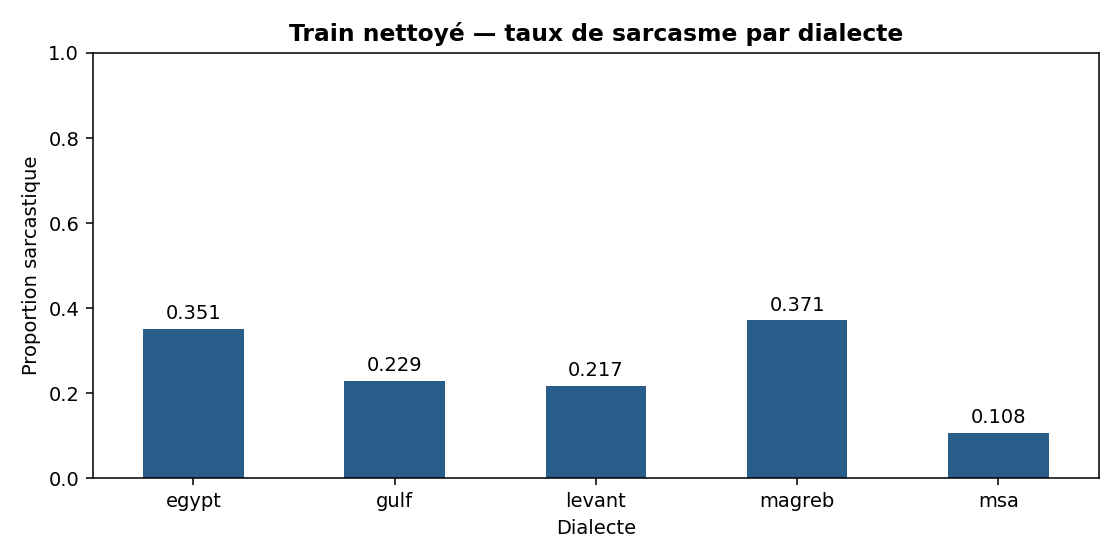

#### Indices textuels — train brut et test

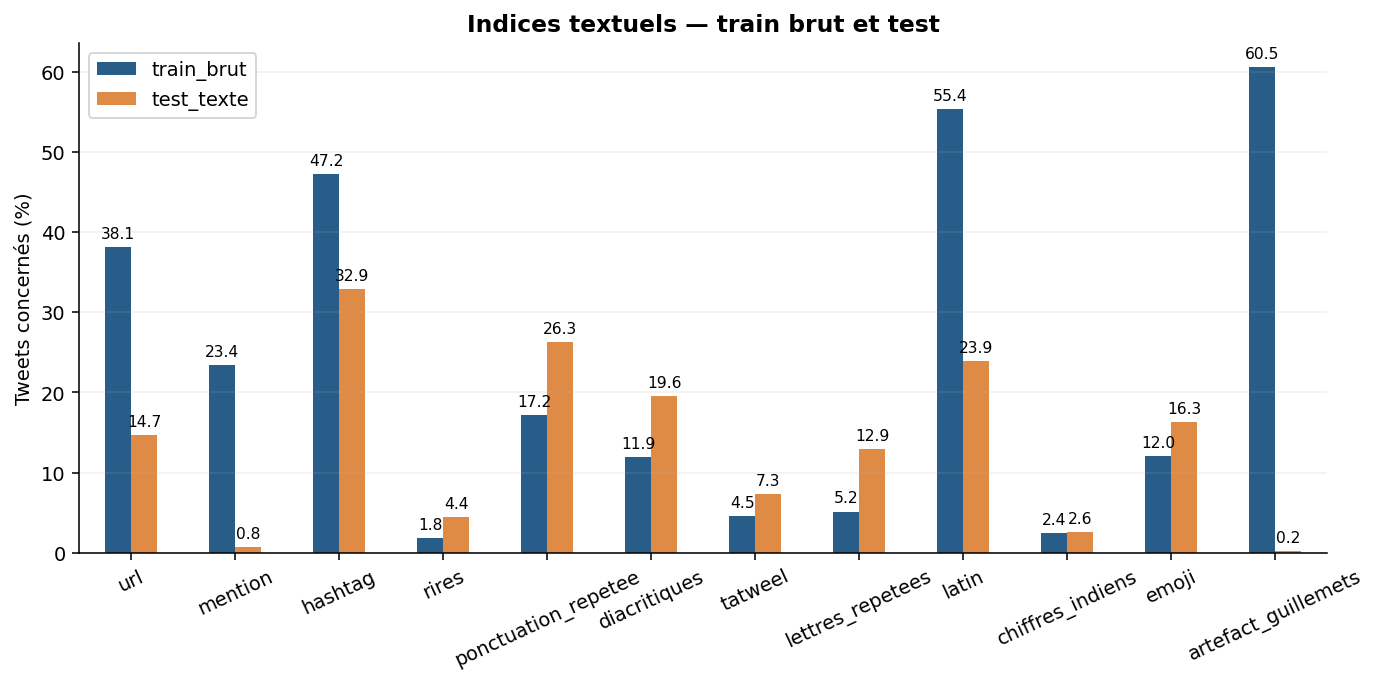

**À présenter :** Les différences de fréquence révèlent un changement de distribution. Les guillemets d’export, notamment, sont beaucoup plus fréquents dans le train.

#### Validation — taux de sarcasme par dialecte

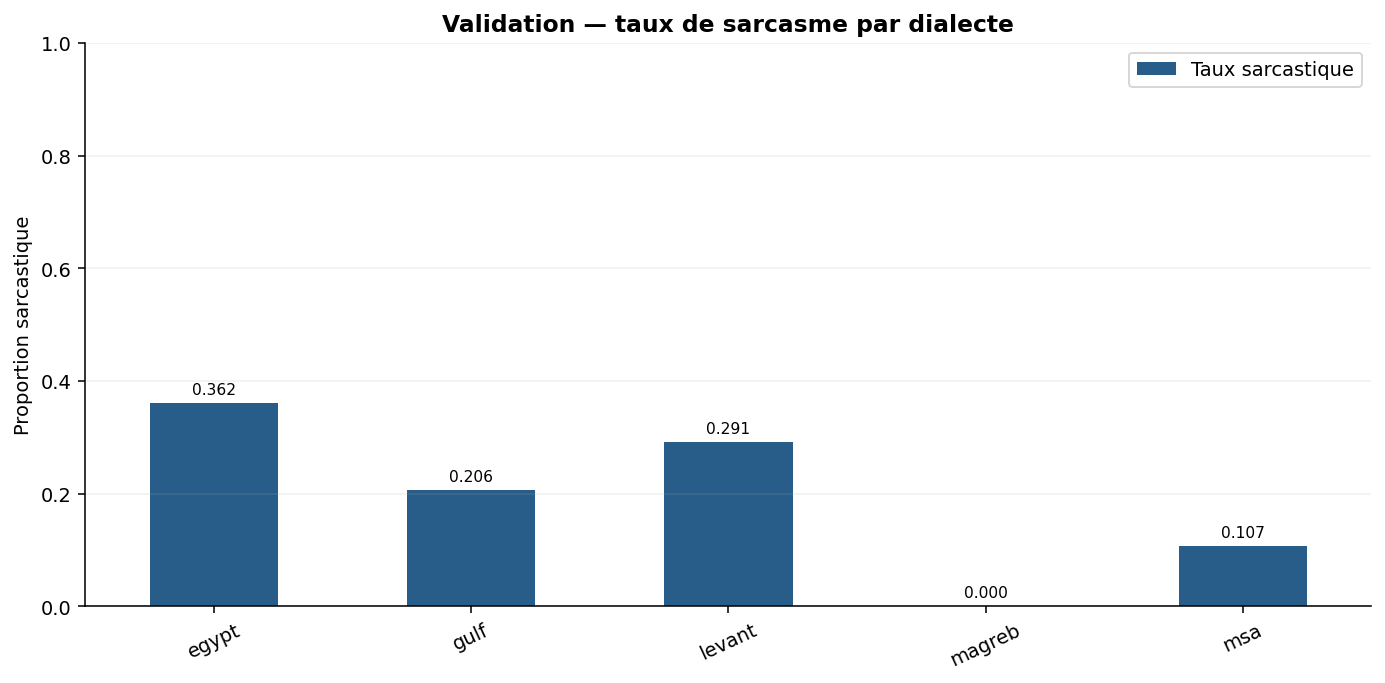

**À présenter :** Je compare les proportions avec les effectifs : cinq tweets maghrébins ne permettent pas de conclure à une absence de sarcasme dans ce dialecte.

#### Validation — sarcasme selon le sentiment

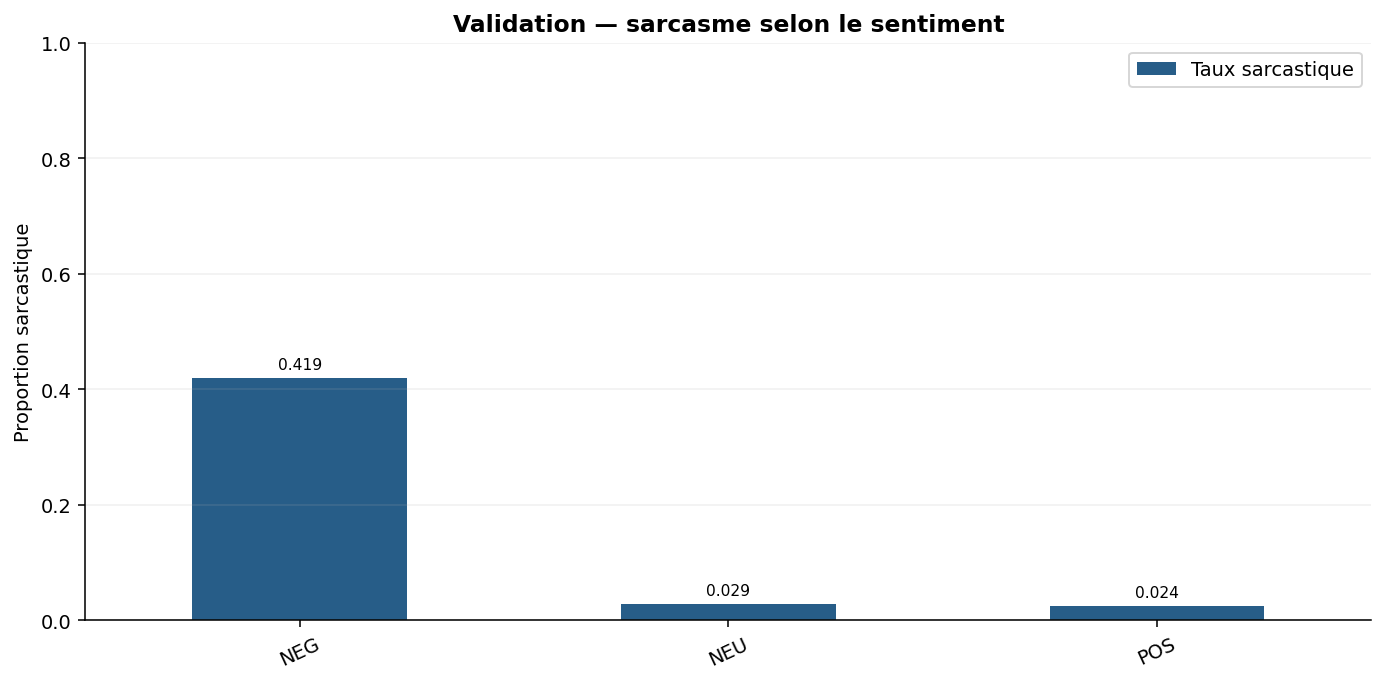

**À présenter :** Les tweets négatifs sont plus souvent sarcastiques, mais la majorité ne l’est pas. Le sentiment est un indice, pas une définition du sarcasme.

In [ ]:
_TP2_TABLE_TITLES = ['Fréquence des indices textuels', 'Corrélation entre indices et sarcasme', 'Exemples avant et après nettoyage', 'Train : répartition par dialecte', 'Train : répartition par sentiment', 'Validation : répartition par dialecte', 'Validation : répartition par sentiment']

PATTERNS = {'url':r'https?://|www\.', 'mention':r'@\w+', 'hashtag':r'#\w+',
    'rires':r'ه{2,}|خ{2,}', 'ponctuation_repetee':r'([!?؟.،])\1+',
    'diacritiques':DIAC.pattern, 'tatweel':'ـ', 'lettres_repetees':r'([^\W\d_])\1{2,}',
    'latin':r'[A-Za-z]', 'chiffres_indiens':r'[٠-٩]'}

def text_features(series):
    result = pd.DataFrame({k:series.str.contains(p,regex=True) for k,p in PATTERNS.items()})
    result['emoji'] = series.map(lambda s: bool(emoji.get_emoji_regexp().search(s)))
    result['artefact_guillemets'] = series.str.strip().str.startswith('"') & series.str.strip().str.endswith('"')
    return result

raw_audit = pd.concat({name:text_features(frame.tweet).mean().mul(100)
    for name,frame in [('train_brut',train_original),('test_texte',sealed_text)]},axis=1)

display(raw_audit.round(2).rename_axis('Indice présent (%)'))

raw_audit.to_csv(ROOT/'results/text_audit.csv')

shortcut_rates = []

features_train = text_features(train.tweet)

for feature in ['url','mention','artefact_guillemets']:
    for flag in [False,True]:
        selected = train.loc[features_train[feature].eq(flag)]
        shortcut_rates.append({'indice':feature,'present':flag,'n':len(selected),'taux_sarcasme':selected.y.mean()})

display(pd.DataFrame(shortcut_rates))

examples = ['"يا سلاااام 😂 ههههه !!! #جميل https://t.co/abc @ami"', 'لَا أحب هـذا أبداً؟!','ما شاء الله، خدمة ممتازة... بعد ساعتين انتظار!']

display(pd.DataFrame({'brut':examples, 'conservateur':[prepare_text(s) for s in examples],
                      'agressif':[prepare_text(s,'aggressive') for s in examples]}))

assert all(c in prepare_text(examples[0]) for c in ['😂','ههههه','!!!','سلاااام','#جميل'])

assert 'لا' in prepare_text('لَا أحب هذا')

assert prepare_text('مرحبا   بالعالم') == prepare_text(prepare_text('مرحبا   بالعالم'))

assert 'http' not in prepare_text(examples[0]) and '@ami' not in prepare_text(examples[0])

print('Contrôles du prétraitement et de séparation : OK.')

for name,frame in [('train',train),('val',val)]:
    print(name, 'n =',len(frame),'sarcasme =',round(frame.y.mean(),4))
    display(frame.groupby('dialect').y.agg(['size','sum','mean']))
    display(frame.groupby('sentiment').y.agg(['size','sum','mean']))

fig,ax=plt.subplots(figsize=(7,3))

train.groupby('dialect').y.mean().plot.bar(ax=ax,color='#275D88')

ax.set(ylabel='Proportion sarcastique',title='Train nettoyé par dialecte',xlabel='Dialecte')

plt.tight_layout()

fig.savefig(ROOT/'figures/prior_train.png')

_tp2_display(_TP2Markdown('#### Train nettoyé — taux de sarcasme par dialecte'))
_tp2_display(fig)
plt.close(fig)

# Graphique complémentaire : valeurs de la session courante.
_tp2_plot(raw_audit, 'Indices textuels — train brut et test', 'Tweets concernés (%)', 'presentation_01', unit_interval=False)

# Graphique complémentaire : valeurs de la session courante.
_tp2_plot(val.groupby('dialect').y.mean().to_frame('Taux sarcastique'), 'Validation — taux de sarcasme par dialecte', 'Proportion sarcastique', 'presentation_02', unit_interval=True)

# Graphique complémentaire : valeurs de la session courante.
_tp2_plot(val.groupby('sentiment').y.mean().to_frame('Taux sarcastique'), 'Validation — sarcasme selon le sentiment', 'Proportion sarcastique', 'presentation_03', unit_interval=True)

### Présenter les résultats — étape 06

**Support 1 — Fréquence des indices textuels**

> « Les URL apparaissent dans 38,09 % du train brut contre 14,67 % du test. Les guillemets d’export passent de 60,54 % à 0,20 %. Ces différences montrent qu’un modèle peut apprendre des indices liés au corpus plutôt qu’au sarcasme. »

**Support 2 — Corrélation entre indices et sarcasme**

> « Dans le train nettoyé des collisions, le taux de sarcasme est de 23,90 % sans URL contre 6,29 % avec URL. Cette corrélation peut devenir un raccourci ; elle ne signifie pas qu’un lien empêche un tweet d’être sarcastique. »

**Support 3 — Exemples avant et après nettoyage**

> « Le nettoyage conservateur garde les emojis, les rires et la ponctuation, alors que le nettoyage agressif en supprime une partie. Je conserve ces indices quand ils peuvent porter l’ironie, puis je vérifie leur intérêt par les scores. »

**Support 4 — Train : répartition par dialecte**

> « Le train contient surtout de l’arabe standard, avec 7 427 tweets, contre seulement 35 tweets maghrébins. Cette différence limite ce que je peux conclure sur les dialectes peu représentés. »

**Support 5 — Train : répartition par sentiment**

> « Dans le train, environ 41,89 % des tweets négatifs sont sarcastiques, contre 2,69 % des neutres et 2,41 % des positifs. Le sentiment est donc lié au sarcasme, mais ces deux notions ne sont pas équivalentes. »

**Support 6 — Validation : répartition par dialecte**

> « La validation ne contient que cinq tweets maghrébins. Un score sur un groupe aussi petit serait trop instable pour juger un usage sur des tweets marocains. »

**Support 7 — Validation : répartition par sentiment**

> « Le lien entre sentiment négatif et sarcasme se retrouve dans la validation : environ 41,94 % des tweets négatifs sont sarcastiques. Cette observation motive la tâche auxiliaire de sentiment. »

**Support 8 — Graphique du taux de sarcasme par dialecte**

> « L’axe horizontal représente les dialectes et la hauteur des barres leur proportion de sarcasme dans le train. Je lis ces proportions avec les effectifs du tableau : une barre élevée sur 35 tweets est beaucoup moins représentative qu’une barre calculée sur plusieurs milliers. »

**3. Résultat — Visualisation**

Les sorties enregistrées ci-dessus proviennent de l’exécution originale : tableaux, métriques, graphiques ou journaux selon cette étape.

**4. Mon interprétation**

La validation contient environ 17,3 % de sarcasme. Les URL sont plus fréquentes dans le train que dans le test : elles peuvent devenir un raccourci fragile.

### Mesures, seuil et registre

**1. Explication**

**Objectif :** Définir les métriques et choisir les seuils sur validation.

**Pourquoi cette méthode ?** Le F1 de la classe sarcastique prend en compte précision et rappel.

**2. Code — Implémentation**

La cellule suivante réalise cette étape.

In [ ]:
_TP2_TABLE_TITLES = []

def scores(y,p,threshold):
    y=np.asarray(y,dtype=int); p=np.asarray(p); pred=(p>=threshold).astype(int)
    return {'f1_sarcastique':float(f1_score(y,pred,zero_division=0)),
        'precision':float(precision_score(y,pred,zero_division=0)),
        'recall':float(recall_score(y,pred,zero_division=0)),
        'macro_f1':float(f1_score(y,pred,average='macro',zero_division=0)),
        'pr_auc_ap':float(average_precision_score(y,p)) if y.sum() else float('nan')}

def best_threshold(y,p):
    prec,rec,thresholds=precision_recall_curve(y,p)
    fs=2*prec[:-1]*rec[:-1]/np.maximum(prec[:-1]+rec[:-1],1e-12)
    i=np.flatnonzero(np.isclose(fs,fs.max(),atol=1e-12))[-1]
    return float(thresholds[i])

RESULTS=[]

REGISTRY={}

HISTORY=[]

DATA_SIG=hashlib.sha256(pd.util.hash_pandas_object(train[['id','tweet','y']],index=False).values.tobytes()).hexdigest()
protocol_frames=pd.concat([train.assign(partition='train'),val.assign(partition='val')],ignore_index=True)
CACHE_CONTEXT.update(train_val_sha256=hashlib.sha256(pd.util.hash_pandas_object(
    protocol_frames[['partition','id','tweet','y','sentiment','dialect']],index=False).values.tobytes()).hexdigest(),
    model_revisions={name:r['revision'] for name,r in REVISIONS.items()})

def register(name,seed,pval,seconds,params,preprocessing,kind,path,config,threshold=None,extra=None):
    t=best_threshold(val.y,pval) if threshold is None else threshold
    key=f'{name}_seed{seed}'
    row={'model':name,'seed':seed,'preprocessing':preprocessing,'threshold':t,
         'train_seconds':seconds,'trainable_parameters':int(params),'n_train':len(train),
         'data_sha256':DATA_SIG,'kind':kind,**{'val_'+k:v for k,v in scores(val.y,pval,t).items()}}
    if extra: row.update(extra)
    RESULTS[:]=[r for r in RESULTS if (r['model'],r['seed'])!=(name,seed)]
    RESULTS.append(row)
    REGISTRY[key]={'key':key,'name':name,'seed':seed,'kind':kind,'path':Path(path).relative_to(ROOT).as_posix(),'config':config,'threshold':t}
    np.save(ROOT/f'predictions/{key}_val.npy',np.asarray(pval))
    pd.DataFrame(RESULTS).to_csv(ROOT/'results/results.csv',index=False)
    (ROOT/'results/registry.json').write_text(json.dumps(REGISTRY,ensure_ascii=False,indent=2),encoding='utf-8')
    print(key,'F1 val =',round(row['val_f1_sarcastique'],4),'seuil =',round(t,4),'temps =',round(seconds,1),'s',flush=True)
    return key

### Présenter les résultats — étape 07

**Phrase de présentation**

> Je choisis le F1 de la classe sarcastique comme métrique principale, puis je complète avec la précision, le rappel, le macro-F1 et l’average precision, utilisée ici comme mesure PR-AUC. Ces mesures ne doivent pas être confondues avec l’accuracy.

**3. Résultat — Visualisation**

Cette cellule définit des fonctions ou des paramètres. Elle ne produit pas de métrique ni de graphique ; leur utilisation est montrée dans les étapes suivantes.

**4. Mon interprétation**

Ce sont des outils d’évaluation ; aucun score de modèle n’est encore produit par cette étape.

### Caches et référence naïve

**1. Explication**

**Objectif :** Préparer les caches et mesurer une référence naïve.

**Pourquoi cette méthode ?** La référence permet de vérifier si une bonne accuracy masque un échec sur la classe minoritaire.

**2. Code — Implémentation**

La cellule suivante réalise cette étape.

In [ ]:
_TP2_TABLE_TITLES = []

def cache_signature(config):
    return hashlib.sha256(json.dumps([RUN_VERSION,DATA_SIG,config],sort_keys=True).encode()).hexdigest()

def compatible_metadata(meta):
    if not meta.exists(): return False
    saved=json.loads(meta.read_text())
    if saved.get('runtime_context')!=CACHE_CONTEXT: return False
    expected=saved.get('checkpoint_stat')
    checkpoint=meta.with_suffix('.pt')
    return expected is None or (checkpoint.exists() and expected==checkpoint_stat(checkpoint))

def checkpoint_stat(path):
    stat=path.stat()
    return {'bytes':stat.st_size,'mtime_ns':stat.st_mtime_ns}


def savefig(fig,name):
    fig.tight_layout(); fig.savefig(ROOT/f'figures/{name}.png',bbox_inches='tight'); _tp2_display(_TP2Markdown('#### ' + ' — '.join(ax.get_title() for ax in fig.axes if ax.get_title()))); _tp2_display(fig); plt.close(fig)

trivial=np.zeros(len(val))

print('Jamais sarcastique : accuracy =',accuracy_score(val.y,trivial),'F1 =',f1_score(val.y,trivial))

print('Sarcastiques val :',int(val.y.sum()),'sur',len(val))

Jamais sarcastique : accuracy = 0.8270916334661355 F1 = 0.0
Sarcastiques val : 217 sur 1255


### Présenter les résultats — étape 08

**Phrase de présentation**

> Le modèle qui prédit toujours « non sarcastique » atteint 82,71 % d’accuracy, mais son F1 sarcastique est nul. Ce résultat montre pourquoi une accuracy élevée peut être trompeuse sur des classes déséquilibrées.

**3. Résultat — Visualisation**

Les sorties enregistrées ci-dessus proviennent de l’exécution originale : tableaux, métriques, graphiques ou journaux selon cette étape.

**4. Mon interprétation**

Prédire toujours « non sarcastique » donne 82,7 % d’accuracy mais un F1 sarcastique nul. L’accuracy seule ne suffit donc pas.

## A. Baseline TF-IDF

### TF-IDF et régression logistique

**1. Explication**

**Objectif :** Construire une représentation TF-IDF de mots et caractères.

**Pourquoi cette méthode ?** Cette méthode fournit une baseline rapide et interprétable.

**2. Code — Implémentation**

La cellule suivante réalise cette étape.

In [ ]:
_TP2_TABLE_TITLES = []

def make_tfidf(mode='conservative',balanced=True,seed=42):
    # top-level prepare_text est enregistré avec le modèle ; aucun label auxiliaire en entrée.
    return Pipeline([('features',FeatureUnion([
        ('word',TfidfVectorizer(ngram_range=(1,2),min_df=2,max_features=60000,token_pattern=r'(?u)\b\w+\b',sublinear_tf=True)),
        ('char',TfidfVectorizer(analyzer='char',ngram_range=(2,5),min_df=2,max_features=100000,sublinear_tf=True))])),
        ('clf',LogisticRegression(C=1,max_iter=1200,class_weight='balanced' if balanced else None,random_state=seed,solver='liblinear'))])

### Présenter les résultats — étape 09

**Phrase de présentation**

> Je prépare une baseline TF-IDF de mots et de caractères avec régression logistique. Aucun score n’est produit tant que cette chaîne n’est pas entraînée et évaluée.

**3. Résultat — Visualisation**

Cette cellule définit des fonctions ou des paramètres. Elle ne produit pas de métrique ni de graphique ; leur utilisation est montrée dans les étapes suivantes.

**4. Mon interprétation**

La chaîne de traitement est définie ; son efficacité sera mesurée dans la comparaison des variantes.

### Entraînement et évaluation

**1. Explication**

**Objectif :** Définir l’entraînement de la régression logistique.

**Pourquoi cette méthode ?** Un protocole commun facilite la comparaison du nettoyage et de l’équilibrage.

**2. Code — Implémentation**

La cellule suivante réalise cette étape.

In [ ]:
_TP2_TABLE_TITLES = []

def run_tfidf(name,mode='conservative',imbalance='weighted',seed=42,drop_links=False,train_frame=None):
    frame=train if train_frame is None else train_frame
    x=[prepare_text(s,mode,drop_links) for s in frame.tweet]; y=frame.y.to_numpy()
    if imbalance=='oversample':
        rng=np.random.default_rng(seed); idx=np.concatenate([np.flatnonzero(y==0),rng.choice(np.flatnonzero(y==1),sum(y==0),replace=True)])
        x=[x[i] for i in idx]; y=y[idx]
    config={'mode':mode,'imbalance':imbalance,'drop_links':drop_links,'seed':seed,'ids':frame.id.tolist()}
    path=ROOT/f'models/{name}_seed{seed}.joblib'; meta=path.with_suffix('.json'); sig=cache_signature(config)
    if path.exists() and compatible_metadata(meta) and json.loads(meta.read_text())['signature']==sig:
        model=joblib.load(path); seconds=json.loads(meta.read_text())['seconds']
    else:
        model=make_tfidf(mode,imbalance=='weighted',seed); start=time.perf_counter(); model.fit(x,y); seconds=time.perf_counter()-start
        joblib.dump(model,path); meta.write_text(json.dumps({'signature':sig,'seconds':seconds,'runtime_context':CACHE_CONTEXT}))
    p=model.predict_proba([prepare_text(s,mode,drop_links) for s in val.tweet])[:,1]
    params=model.named_steps['clf'].coef_.size+1
    return register(name,seed,p,seconds,params,mode,'tfidf',path,config)

### Présenter les résultats — étape 10

**Phrase de présentation**

> Cette fonction applique le même protocole à toutes les variantes TF-IDF. Le résultat à commenter se trouve dans le tableau de comparaison suivant.

**3. Résultat — Visualisation**

Cette cellule définit des fonctions ou des paramètres. Elle ne produit pas de métrique ni de graphique ; leur utilisation est montrée dans les étapes suivantes.

**4. Mon interprétation**

Cette fonction prépare les essais ; la cellule suivante affiche les performances obtenues.

### Comparaison des variantes et F1

**1. Explication**

**Objectif :** Comparer les variantes TF-IDF sur validation.

**Pourquoi cette méthode ?** La baseline établit le niveau à dépasser avec les modèles plus complexes.

**2. Code — Implémentation**

La cellule suivante réalise cette étape.

A_tfidf_conservateur_seed42 F1 val = 0.5206 seuil = 0.5161 temps = 5.7 s
A_tfidf_agressif_seed42 F1 val = 0.4959 seuil = 0.4877 temps = 5.4 s
A_tfidf_standard_seed42 F1 val = 0.5195 seuil = 0.2504 temps = 5.7 s
A_tfidf_sur_echantillonne_seed42 F1 val = 0.4743 seuil = 0.3508 temps = 8.9 s


#### Comparaison des variantes TF-IDF

,model,val_f1_sarcastique,val_pr_auc_ap,threshold,train_seconds
0,A_tfidf_conservateur,0.520607,0.514514,0.516072,5.743542
1,A_tfidf_agressif,0.495935,0.490162,0.487735,5.353780
2,A_tfidf_standard,0.519481,0.517236,0.250351,5.661903
3,A_tfidf_sur_echantillonne,0.474308,0.476991,0.350759,8.879105


#### Classifieurs à une seule règle

,indice,orientation,f1_sarcastique,precision,recall,macro_f1,pr_auc_ap
0,url,0,0.361768,0.232804,0.811060,0.478867,0.221488
1,mention,0,0.266439,0.163522,0.718894,0.312458,0.166161
2,artefact_guillemets,0,0.300578,0.218947,0.479263,0.517176,0.194973


#### TF-IDF — comparaison des variantes sur validation

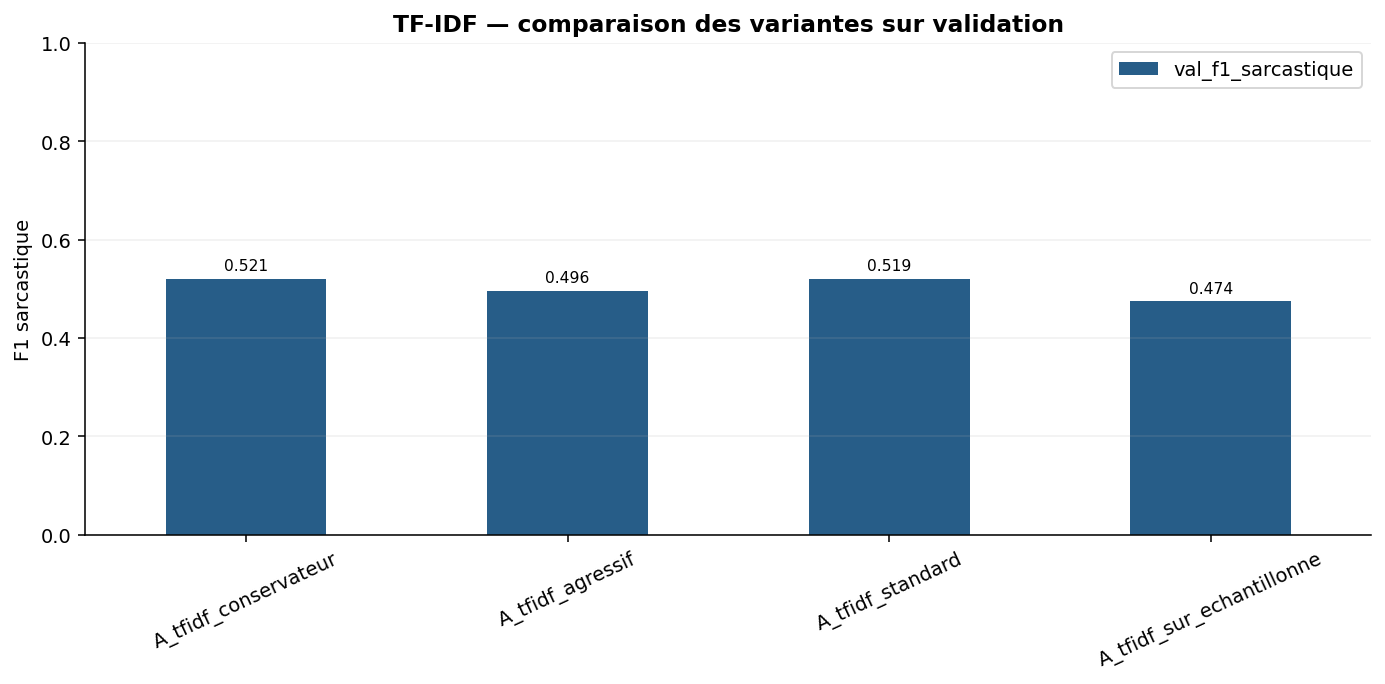

**À présenter :** La variante conservatrice obtient le meilleur F1 de cette comparaison. Le nettoyage agressif retire des informations utiles dans cet essai.

In [ ]:
_TP2_TABLE_TITLES = ['Comparaison des variantes TF-IDF', 'Classifieurs à une seule règle']

baseline_keys=[run_tfidf('A_tfidf_conservateur'),run_tfidf('A_tfidf_agressif',mode='aggressive'),
               run_tfidf('A_tfidf_standard',imbalance='standard'),run_tfidf('A_tfidf_sur_echantillonne',imbalance='oversample')]

display(pd.DataFrame(RESULTS)[['model','val_f1_sarcastique','val_pr_auc_ap','threshold','train_seconds']])

rule_rows=[]

features_val=text_features(val.tweet)

for feature in ['url','mention','artefact_guillemets']:
    flag_train=features_train[feature].to_numpy(); flag_val=features_val[feature].to_numpy()
    # Deux orientations ; orientation choisie sur train pour ne pas ajouter de sélection test.
    direction=1 if train.y[flag_train].mean()>=train.y[~flag_train].mean() else 0
    p=(flag_val==bool(direction)).astype(float)
    rule_rows.append({'indice':feature,'orientation':direction,**scores(val.y,p,.5)})

rules=pd.DataFrame(rule_rows)

rules.to_csv(ROOT/'results/shortcut_rules_val.csv',index=False)

display(rules)

# Graphique complémentaire : valeurs de la session courante.
_tp2_plot(pd.DataFrame(RESULTS).query("model.str.startswith('A_')", engine='python').set_index('model')[['val_f1_sarcastique']], 'TF-IDF — comparaison des variantes sur validation', 'F1 sarcastique', 'presentation_04', unit_interval=True)

### Présenter les résultats — étape 11

**Support 1 — Comparaison des variantes TF-IDF**

> « Le nettoyage conservateur donne le meilleur F1 validation de cette comparaison : 0,5206. Le nettoyage agressif descend à 0,4959 et le sur-échantillonnage à 0,4743. La solution la plus complexe ne gagne donc pas automatiquement. »

**Support 2 — Classifieurs à une seule règle**

> « Une règle fondée sur les URL atteint déjà un F1 de 0,3618 ; celles fondées sur les mentions et les guillemets atteignent 0,2664 et 0,3006. Ces scores révèlent des raccourcis dans les données, sans démontrer une compréhension de l’ironie. »

**3. Résultat — Visualisation**

Les sorties enregistrées ci-dessus proviennent de l’exécution originale : tableaux, métriques, graphiques ou journaux selon cette étape.

**4. Mon interprétation**

Le nettoyage conservateur atteint un F1 validation de 0,5206 contre 0,4959 pour le nettoyage agressif. Conserver certains indices est utile dans cet essai.

## B. Zero-shot

### Modèles et inférence NLI

**1. Explication**

**Objectif :** Préparer les modèles préentraînés et l’inférence NLI.

**Pourquoi cette méthode ?** Le zero-shot teste le transfert sans apprentissage sur les labels de sarcasme.

**2. Code — Implémentation**

La cellule suivante réalise cette étape.

In [ ]:
_TP2_TABLE_TITLES = []

if IN_COLAB: prepare_models(ROOT)

NLI_NAME='MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7'

assert (ROOT/'models/assets_complete.json').exists(), 'Poids locaux manquants dans models/hf.'

REVISIONS.update(json.loads((ROOT/'models/revisions.json').read_text()))

SA_NAME='CAMeL-Lab/bert-base-arabic-camelbert-da-sentiment'

ARA_NAME='aubmindlab/bert-base-arabertv02-twitter'

MAR_NAME='UBC-NLP/MARBERTv2'

PROMPTS={'ar':('هذه التغريدة ساخرة.','هذه التغريدة جادة.'),
         'fr':('Ce tweet est sarcastique.','Ce tweet est sérieux.'),
         'en':('This tweet is sarcastic.','This tweet is serious.')}
for model_name,entry in REVISIONS.items():
    entry['path']=str(ROOT/'models/hf'/model_name.replace('/','--'))

def load_hf(name,classification=False):
    FROZEN_MODELS.clear()  # Libérer l'extracteur avant un nouveau PLM, sous 16 Go.
    if name not in REVISIONS: REVISIONS.update(json.loads((ROOT/'models/revisions.json').read_text()))
    folder=ROOT/'models/hf'/name.replace('/','--')
    config=json.loads((folder/'config.json').read_text())
    options={'attn_implementation':'sdpa'} if config['model_type']=='bert' else {}
    cls=AutoModelForSequenceClassification if classification else AutoModel
    return cls.from_pretrained(str(folder),local_files_only=True,**options).to(DEVICE)

def frozen_encoder():
    key=(ARA_NAME,str(DEVICE))
    if key not in FROZEN_MODELS:
        encoder=load_hf(ARA_NAME).eval().requires_grad_(False)
        FROZEN_MODELS[key]=encoder
    return FROZEN_MODELS[key]

def inference_signature(texts,tag):
    payload={'texts':list(texts),'tag':tag,'max_len':MAX_LEN,'run_version':RUN_VERSION,'torch':torch.__version__,
             'revisions':{k:v['revision'] for k,v in REVISIONS.items()},
             'preprocess_sha256':hashlib.sha256((ROOT/'src/preprocess.py').read_bytes()).hexdigest()}
    if CACHE_CONTEXT.get('device_type')=='cuda': payload['gpu_context']=CACHE_CONTEXT
    return hashlib.sha256(json.dumps(payload,sort_keys=True,ensure_ascii=False).encode()).hexdigest()

def valid_cache(path,texts,tag):
    sidecar=path.with_name(path.name+'.cache.json')
    signature=inference_signature(texts,tag)
    if path.exists() and sidecar.exists():
        meta=json.loads(sidecar.read_text())
        return meta['signature']==signature and meta['bytes']==path.stat().st_size
    return False

def mark_cache(path,texts,tag):
    path.with_name(path.name+'.cache.json').write_text(json.dumps({
        'signature':inference_signature(texts,tag),'bytes':path.stat().st_size},indent=2))

def validation_scores(model,inputs,path,signature,candidate=None,plm=False):
    target=ROOT/f'predictions/{path.stem}_val.npy'
    meta=target.with_suffix('.validation.json')
    expected={'signature':signature,'checkpoint_stat':checkpoint_stat(path),'context':CACHE_CONTEXT}
    if candidate is None and target.exists() and meta.exists():
        try:
            saved=json.loads(meta.read_text())
            digest=hashlib.sha256(target.read_bytes()).hexdigest()
            if all(saved.get(k)==v for k,v in expected.items()) and saved['probability_sha256']==digest:
                p=np.load(target,allow_pickle=False)
                if p.shape==(len(inputs[0]),) and np.isfinite(p).all() and ((p>=0)&(p<=1)).all(): return p
        except (OSError,ValueError,KeyError): pass  # Cache invalide : vraie inférence ci-dessous.
    p=candidate if candidate is not None else neural_predict(model,inputs,batch=BATCH if plm else 64)
    np.save(target,p)
    expected['probability_sha256']=hashlib.sha256(target.read_bytes()).hexdigest()
    expected['producer']='checkpoint_validation'
    meta.write_text(json.dumps(expected,indent=2))
    return p


def cached_nli(texts,language,split):
    path=ROOT/f'predictions/B1_{language}_{split}_raw.npy'
    if valid_cache(path,texts,['nli',language,PROMPTS[language]]): return np.load(path),0.0
    tokenizer=AutoTokenizer.from_pretrained(REVISIONS[NLI_NAME]['path'],local_files_only=True)
    model=load_hf(NLI_NAME,True).eval()
    print('NLI labels :',model.config.id2label,flush=True)
    entail=[i for i,label in model.config.id2label.items() if 'entail' in label.lower()]
    assert len(entail)==1
    probs=[]; start=time.perf_counter()
    with torch.inference_mode():
        for j in range(0,len(texts),BATCH):
            batch=[export_clean(s) for s in texts[j:j+BATCH]]
            # Tronquer la prémisse seule garde les deux hypothèses complètes.
            batch=tokenizer.batch_decode(tokenizer(batch,truncation=True,max_length=MAX_LEN,add_special_tokens=False)['input_ids'],skip_special_tokens=True)
            premises=[s for s in batch for _ in range(2)]; hypotheses=[h for _ in batch for h in PROMPTS[language]]
            enc=tokenizer(premises,hypotheses,padding=True,truncation='only_first',max_length=MAX_LEN+24,return_tensors='pt').to(DEVICE)
            logits=model(**enc).logits[:,entail[0]].reshape(-1,2)
            probs.extend(logits.softmax(1)[:,0].cpu().numpy())
            if (j//BATCH+1)%20==0: print('B1',language,split,j+len(batch),'/',len(texts),flush=True)
    elapsed=time.perf_counter()-start
    np.save(path,np.asarray(probs)); mark_cache(path,texts,['nli',language,PROMPTS[language]]); del model; gc.collect()
    return np.asarray(probs),elapsed

Préparation du PLM : aubmindlab/bert-base-arabertv02-twitter révision 0decc2e761667f0aea7aa94546ada5a32a6e5bb8


Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/541M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/667 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/86.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

Les quatre PLM sont disponibles et vérifiés, sans chargement en mémoire.


### Présenter les résultats — étape 12

**Phrase de présentation**

> Les modèles sont téléchargés et leurs fichiers vérifiés. Les barres de progression sont des journaux de préparation, pas des mesures de performance.

**3. Résultat — Visualisation**

Les sorties enregistrées ci-dessus proviennent de l’exécution originale : tableaux, métriques, graphiques ou journaux selon cette étape.

**4. Mon interprétation**

Les journaux attestent la préparation des quatre modèles ; les téléchargements ne constituent pas une évaluation.

### Comparaison des prompts NLI

**1. Explication**

**Objectif :** Comparer les formulations NLI arabe, française et anglaise.

**Pourquoi cette méthode ?** La formulation de l’hypothèse peut modifier la détection zero-shot.

**2. Code — Implémentation**

La cellule suivante réalise cette étape.

In [ ]:
_TP2_TABLE_TITLES = []

nli_keys=[]

for language in PROMPTS:
    p,elapsed=cached_nli(val.tweet.tolist(),language,'val')
    key=register(f'B1_NLI_{language}',42,p,0,0,'export_only','nli',REVISIONS[NLI_NAME]['path'],
        {'language':language,'model_name':NLI_NAME},extra={'val_inference_seconds':elapsed})
    nli_keys.append(key)

NLI labels : {0: 'entailment', 1: 'neutral', 2: 'contradiction'}
B1 ar val 640 / 1255
B1 ar val 1255 / 1255
B1_NLI_ar_seed42 F1 val = 0.4069 seuil = 0.8023 temps = 0 s
NLI labels : {0: 'entailment', 1: 'neutral', 2: 'contradiction'}
B1 fr val 640 / 1255
B1 fr val 1255 / 1255
B1_NLI_fr_seed42 F1 val = 0.4189 seuil = 0.7628 temps = 0 s
NLI labels : {0: 'entailment', 1: 'neutral', 2: 'contradiction'}
B1 en val 640 / 1255
B1 en val 1255 / 1255
B1_NLI_en_seed42 F1 val = 0.4224 seuil = 0.8249 temps = 0 s


### Présenter les résultats — étape 13

**Phrase de présentation**

> Le prompt arabe atteint un F1 validation de 0,4069, le français 0,4189 et l’anglais 0,4224. Le choix de formulation influence donc le score, même sans entraînement sur le sarcasme. Je retiens l’anglais sur validation.

**3. Résultat — Visualisation**

Les sorties enregistrées ci-dessus proviennent de l’exécution originale : tableaux, métriques, graphiques ou journaux selon cette étape.

**4. Mon interprétation**

Le prompt anglais atteint 0,4224 de F1 validation, devant le français et l’arabe. Il reste sous la baseline TF-IDF sur cette validation.

### Sentiment et comparaison

**1. Explication**

**Objectif :** Tester la règle « sentiment négatif → sarcasme ».

**Pourquoi cette méthode ?** Cette heuristique vérifie dans quelle mesure sentiment et sarcasme se recouvrent.

**2. Code — Implémentation**

La cellule suivante réalise cette étape.

In [ ]:
_TP2_TABLE_TITLES = ['Comparaison zero-shot et sentiment']

def sentiment_predict(texts,split):
    path=ROOT/f'predictions/B2_{split}_raw.npz'
    if valid_cache(path,texts,'sentiment'):
        a=np.load(path); return a['p'],a['rule'],0.0
    tokenizer=AutoTokenizer.from_pretrained(REVISIONS[SA_NAME]['path'],local_files_only=True)
    model=load_hf(SA_NAME,True).eval(); print('CAMeLBERT labels :',model.config.id2label,flush=True)
    neg=[i for i,label in model.config.id2label.items() if 'neg' in label.lower()]
    assert len(neg)==1
    probs=[]; rule=[]; start=time.perf_counter()
    with torch.inference_mode():
        for j in range(0,len(texts),BATCH):
            enc=tokenizer([export_clean(s) for s in texts[j:j+BATCH]],truncation=True,max_length=MAX_LEN,padding=True,return_tensors='pt').to(DEVICE)
            pred=model(**enc).logits.softmax(-1)
            probs.extend(pred[:,neg[0]].cpu().numpy()); rule.extend((pred.argmax(-1)==neg[0]).cpu().numpy())
    elapsed=time.perf_counter()-start; np.savez(path,p=probs,rule=rule)
    mark_cache(path,texts,'sentiment')
    del model; gc.collect(); return np.asarray(probs),np.asarray(rule),elapsed

p_sent,rule_sent,elapsed=sentiment_predict(val.tweet.tolist(),'val')

b2_key=register('B2_negatif_sarcastique',42,rule_sent.astype(float),0,0,'export_only','sentiment',
    REVISIONS[SA_NAME]['path'],{'model_name':SA_NAME},threshold=.5,extra={'val_inference_seconds':elapsed,'val_pr_auc_ap':float(average_precision_score(val.y,p_sent))})

display(pd.DataFrame(RESULTS).loc[lambda d:d.model.str.startswith('B')])

CAMeLBERT labels : {0: 'positive', 1: 'negative', 2: 'neutral'}
B2_negatif_sarcastique_seed42 F1 val = 0.4695 seuil = 0.5 temps = 0 s


#### Comparaison zero-shot et sentiment

,model,seed,preprocessing,threshold,train_seconds,trainable_parameters,n_train,data_sha256,kind,val_f1_sarcastique,val_precision,val_recall,val_macro_f1,val_pr_auc_ap,val_inference_seconds
4,B1_NLI_ar,42,export_only,0.802276,0.0,0,10842,6ea3f69eb1c2b4017207106f018029bae636c7c67189eb11467ba66ab62c602f,nli,0.406940,0.309353,0.594470,0.603257,0.346567,14.699337
5,B1_NLI_fr,42,export_only,0.762835,0.0,0,10842,6ea3f69eb1c2b4017207106f018029bae636c7c67189eb11467ba66ab62c602f,nli,0.418879,0.308026,0.654378,0.601907,0.349859,13.281176
6,B1_NLI_en,42,export_only,0.824869,0.0,0,10842,6ea3f69eb1c2b4017207106f018029bae636c7c67189eb11467ba66ab62c602f,nli,0.422442,0.329049,0.589862,0.619309,0.348801,13.252760
7,B2_negatif_sarcastique,42,export_only,0.500000,0.0,0,10842,6ea3f69eb1c2b4017207106f018029bae636c7c67189eb11467ba66ab62c602f,sentiment,0.469471,0.332692,0.797235,0.624470,0.474604,4.904597


### Présenter les résultats — étape 14

**Support 1 — Comparaison zero-shot et sentiment**

> « Le meilleur prompt NLI, en anglais, atteint 0,4224 de F1 validation. La règle « négatif implique sarcastique » atteint 0,4695, avec une précision de 0,3327 et un rappel de 0,7972 : elle détecte beaucoup de sarcasmes, mais produit aussi de nombreuses fausses alertes. Le modèle B2 peut avoir déjà vu des tweets issus de corpus réutilisés dans ArSarcasm-v2 ; son score n’est donc pas garanti exempt de contamination. Zéro seconde d’entraînement ne signifie pas zéro coût d’inférence. »

**3. Résultat — Visualisation**

Les sorties enregistrées ci-dessus proviennent de l’exécution originale : tableaux, métriques, graphiques ou journaux selon cette étape.

**4. Mon interprétation**

Le F1 validation est 0,4695. Le sentiment négatif fournit un indice, mais ne suffit pas à identifier le sarcasme.

## C. Deep Learning

Dans cette partie, je cherche à savoir si les réseaux de neurones peuvent mieux détecter le sarcasme que les modèles classiques. Je compare trois architectures : BiLSTM, BiLSTM avec attention et Transformer. Je teste également des embeddings AraVec pour déterminer si des représentations pré-entraînées améliorent les performances.

### Cellule 1. Préparation des tokens et des embeddings

Je découpe les tweets en tokens et je construis le vocabulaire sur les données d’entraînement. Je prépare les entrées des réseaux ; les embeddings aléatoires seront créés avec les architectures, et AraVec sera chargé à l’étape 4.

**Code — Implémentation**

In [ ]:
_TP2_TABLE_TITLES = ['Tokens inconnus et troncature']

TOKEN_RE=re.compile(r'\w+|[^\w\s]',re.UNICODE)

def word_tokens(text): return TOKEN_RE.findall(prepare_text(text))

counts=Counter(t for s in train.tweet for t in word_tokens(s))

VOCAB={'<PAD>':0,'<UNK>':1,**{t:i+2 for i,t in enumerate(sorted(t for t,n in counts.items() if n>=2))}}

(ROOT/'models/vocab.json').write_text(json.dumps(VOCAB,ensure_ascii=False),encoding='utf-8')

def word_encode(texts):
    result=np.zeros((len(texts),MAX_LEN),dtype=np.int64)
    for i,s in enumerate(texts):
        ids=[VOCAB.get(t,1) for t in word_tokens(s)[:MAX_LEN]] or [1]
        result[i,:len(ids)]=ids
    return torch.tensor(result)

def token_stats(texts):
    seqs=[word_tokens(s) for s in texts]; n=sum(map(len,seqs))
    return {'tokens':n,'oov':sum(t not in VOCAB for seq in seqs for t in seq)/max(n,1),
        'truncated':sum(len(seq)>MAX_LEN for seq in seqs)/len(seqs)}

display(pd.DataFrame({name:token_stats(frame.tweet) for name,frame in [('train',train),('val',val)]}).T)

XW_TRAIN=word_encode(train.tweet.tolist())

XW_VAL=word_encode(val.tweet.tolist())

YTRAIN=torch.tensor(train.y.to_numpy(),dtype=torch.long)

YVAL=torch.tensor(val.y.to_numpy(),dtype=torch.long)

SENT_MAP={'NEG':0,'NEU':1,'POS':2}

STRAIN=torch.tensor(train.sentiment.map(SENT_MAP).to_numpy(),dtype=torch.long)

SVAL=torch.tensor(val.sentiment.map(SENT_MAP).to_numpy(),dtype=torch.long)

CLASS_WEIGHTS=torch.tensor(len(train)/(2*np.bincount(train.y)),dtype=torch.float32)

233697

#### Tokens inconnus et troncature

,tokens,oov,truncated
train,197164.0,0.151899,0.000369
val,22892.0,0.211646,0.000000


### Présenter les résultats — étape 15

**Support 1 — Tokens inconnus et troncature**

> « En validation, environ 21,16 % des tokens sont hors vocabulaire, contre 15,19 % dans le train. Le vocabulaire exclut les mots trop rares même dans le train. Cette limite explique l’intérêt de représentations préentraînées et de modèles à sous-mots. »

**Résultat — Lecture simple**

Le tableau affiche les tokens inconnus et les séquences tronquées. Il permet de vérifier les limites du vocabulaire avant l’entraînement.

### Cellule 2. Définition des architectures C1, C2 et C3

Je définis C1 (BiLSTM), C2 (BiLSTM avec attention) et C3 (Transformer). Je cherche à comparer trois façons de prendre en compte les mots et leur contexte.

**Code — Implémentation**

In [ ]:
_TP2_TABLE_TITLES = []

class AttentionPool(nn.Module):
    def __init__(self,dim):
        super().__init__(); self.w=nn.Linear(dim,64); self.v=nn.Linear(64,1,bias=False)
    def forward(self,h,mask):
        logits=self.v(torch.tanh(self.w(h))).squeeze(-1).masked_fill(~mask,-1e4)
        alpha=logits.softmax(-1); return (h*alpha.unsqueeze(-1)).sum(1),alpha

class StaticNet(nn.Module):
    def __init__(self,arch='attention',embedding=None,position=True,freeze=False):
        super().__init__(); self.arch=arch
        self.embedding=nn.Embedding(len(VOCAB),100,padding_idx=0)
        if embedding is not None: self.embedding.weight.data.copy_(torch.tensor(embedding))
        self.embedding.weight.requires_grad_(not freeze)
        self.dropout=nn.Dropout(.25)
        if arch=='transformer':
            self.proj=nn.Linear(100,128)
            layer=nn.TransformerEncoderLayer(128,4,256,dropout=.2,batch_first=True)
            self.encoder=nn.TransformerEncoder(layer,2,enable_nested_tensor=False)
            pos=torch.arange(MAX_LEN).unsqueeze(1); div=torch.exp(torch.arange(0,128,2)*(-math.log(10000)/128))
            pe=torch.zeros(MAX_LEN,128); pe[:,0::2]=torch.sin(pos*div); pe[:,1::2]=torch.cos(pos*div)
            self.register_buffer('pe',pe if position else torch.zeros_like(pe))
        else:
            self.encoder=nn.LSTM(100,64,batch_first=True,bidirectional=True)
            self.attention=AttentionPool(128)
        self.head=nn.Linear(128,2)
    def forward(self,x,return_attention=False):
        mask=x.ne(0); h=self.dropout(self.embedding(x)); alpha=None
        if self.arch=='transformer':
            h=self.encoder(self.proj(h)+self.pe[:x.shape[1]],src_key_padding_mask=~mask)
            pooled=(h*mask.unsqueeze(-1)).sum(1)/mask.sum(1,keepdim=True).clamp(min=1)
        else:
            # pack empêche la direction arrière de traiter du padding avant le vrai texte.
            packed=nn.utils.rnn.pack_padded_sequence(h,mask.sum(1).cpu(),batch_first=True,enforce_sorted=False)
            packed,_=self.encoder(packed)
            h,_=nn.utils.rnn.pad_packed_sequence(packed,batch_first=True,total_length=x.shape[1])
            if self.arch=='attention': pooled,alpha=self.attention(h,mask)
            else: pooled=h.masked_fill(~mask.unsqueeze(-1),-1e4).max(1).values
        logits=self.head(self.dropout(pooled))
        return (logits,alpha) if return_attention else logits

### Présenter les résultats — étape 16

**Phrase de présentation**

> Je définis trois architectures : C1 BiLSTM, C2 BiLSTM avec attention et C3 Transformer. Cette étape prépare les modèles ; seule leur évaluation permettra de les départager.

**Résultat — Lecture simple**

Cette cellule définit les architectures ; elle ne produit pas encore de score.

### Cellule 3. Entraînement et comparaison

Je prépare une procédure commune d’entraînement, puis je compare les architectures avec des embeddings aléatoires. Le F1 sur validation permet de comparer leurs performances.

**Code — Implémentation**

In [ ]:
_TP2_TABLE_TITLES = ['Architectures avec embeddings aléatoires']

def neural_predict(model,inputs,batch=64,attention=False):
    model.eval(); n=len(inputs[0]); probs=np.empty(n,dtype=np.float32); att=[]
    grouped=hasattr(model,'enc') and len(inputs)==2 and not attention
    order=np.argsort(-inputs[1].sum(1).cpu().numpy(),kind='stable') if grouped else np.arange(n)
    with torch.inference_mode():
        for start in range(0,n,batch):
            index=order[start:start+batch]
            selection=index if grouped else slice(start,start+batch)
            args=[x[selection].to(DEVICE,non_blocking=DEVICE.type=='cuda') for x in inputs]
            with torch.autocast(device_type=DEVICE.type,dtype=torch.float16,enabled=grouped and DEVICE.type=='cuda'):
                out=model(*args,return_attention=True) if attention else model(*args)
            if attention: out,a=out; att.extend(a.cpu().numpy())
            if isinstance(out,tuple): out=out[0]
            probs[index]=out.float().softmax(-1)[:,1].cpu().numpy()
    return (probs,np.asarray(att)) if attention else probs

def optimizer_step(model,loss,opt,scaler,scheduler):
    if scaler is None:
        loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),1.0); opt.step()
        if scheduler: scheduler.step()
    else:
        scaler.scale(loss).backward(); scaler.unscale_(opt)
        nn.utils.clip_grad_norm_(model.parameters(),1.0)
        previous_scale=scaler.get_scale(); scaler.step(opt); scaler.update()
        if scheduler and scaler.get_scale()>=previous_scale: scheduler.step()

def train_epoch(model,loader,opt,loss_fn,sent_loss,lam,scheduler,plm,name,seed,epoch,scaler=None):
    model.train(); total_loss=0.; steps=0
    for step,batch in enumerate(loader):
        *xx,yy,ss=[t.to(DEVICE,non_blocking=DEVICE.type=='cuda') for t in batch]
        opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type,dtype=torch.float16,enabled=scaler is not None):
            out=model(*xx); logits=out[0] if isinstance(out,tuple) else out
            loss=loss_fn(logits,yy)
            if lam: loss=loss+lam*sent_loss(out[1],ss)
        optimizer_step(model,loss,opt,scaler,scheduler)
        total_loss+=loss.item(); steps+=1
        if plm and steps%50==0:
            print(name,seed,'époque',epoch+1,'batch',steps,'/',len(loader),'perte',round(total_loss/steps,4),flush=True)
    return total_loss/max(steps,1)


def make_training_loader(xtrain,y,sy,seed,imbalance,plm):
    dataset=TensorDataset(*xtrain,y,sy)
    generator=torch.Generator().manual_seed(seed)
    if imbalance=='oversample':
        weights=(1/np.bincount(y.numpy()))[y.numpy()]
        sampler=WeightedRandomSampler(weights,len(y),replacement=True,generator=generator)
    elif plm:
        from transformers.trainer_pt_utils import LengthGroupedSampler
        sampler=LengthGroupedSampler(batch_size=BATCH,lengths=xtrain[1].sum(1).tolist(),generator=generator)
    else: sampler=RandomSampler(dataset,generator=generator)
    # TensorDataset accepte une liste d'indices : une extraction par tenseur, sans boucle Python par tweet.
    batches=BatchSampler(sampler,BATCH if plm else 64,drop_last=False)
    return DataLoader(dataset,batch_size=None,sampler=batches,generator=generator,num_workers=0,pin_memory=DEVICE.type=='cuda')


def train_neural(model,xtrain,xval,name,seed=42,config=None,epochs=STATIC_EPOCHS,
                 lr=1e-3,imbalance='weighted',labels=None,sentiments=None,lam=0,freeze_epochs=0,plm=False,val_mask=None):
    config=dict(config or {},seed=seed,epochs=epochs,lr=lr,imbalance=imbalance,lam=lam,
                train_ids=(config or {}).get('train_ids',train.id.tolist()))
    if plm: config.update(dynamic_padding=True,length_grouped=True)
    path=ROOT/f'models/{name}_seed{seed}.pt'; meta=path.with_suffix('.json'); sig=cache_signature(config)
    model=model.to(DEVICE)
    if plm and DEVICE.type!='cpu':
        config.update(device_type=DEVICE.type,precision=PLM_PRECISION,batch=BATCH)
    p=None; best_path=path.with_suffix('.pending.pt')
    trained_params=sum(p.numel() for p in model.parameters() if p.requires_grad)
    if freeze_epochs: trained_params+=model.embedding.weight.numel()
    selection_mask=np.ones(len(val),dtype=bool) if val_mask is None else np.asarray(val_mask)
    config['selection_val_ids']=val.id[selection_mask].tolist()
    sig=cache_signature(config)
    if path.exists() and compatible_metadata(meta) and json.loads(meta.read_text())['signature']==sig:
        payload=torch.load(path,map_location=DEVICE,weights_only=True); model.load_state_dict(payload); del payload
        saved=json.loads(meta.read_text()); seconds=saved['seconds']; history=saved['history']
    else:
        seed_all(seed); y=YTRAIN if labels is None else labels; sy=STRAIN if sentiments is None else sentiments
        loader=make_training_loader(xtrain,y,sy,seed,imbalance,plm)
        opt=torch.optim.AdamW(model.parameters(),lr=lr,weight_decay=.01)
        scaler=torch.amp.GradScaler('cuda') if plm and DEVICE.type=='cuda' else None
        total=epochs*len(loader); scheduler=get_linear_schedule_with_warmup(opt,int(.1*total),total) if plm else None
        weights=torch.tensor(len(y)/(2*np.bincount(y.numpy())),dtype=torch.float32,device=DEVICE) if imbalance=='weighted' else None
        loss_fn=nn.CrossEntropyLoss(weight=weights); sent_loss=nn.CrossEntropyLoss()
        start=time.perf_counter(); best=-1; stale=0; history=[]; best_p=None
        for epoch in range(epochs):
            if freeze_epochs and epoch==freeze_epochs:
                model.embedding.weight.requires_grad_(True)
            mean_loss=train_epoch(model,loader,opt,loss_fn,sent_loss,lam,scheduler,plm,name,seed,epoch,scaler)
            p=neural_predict(model,xval,batch=BATCH if plm else 64)
            t=best_threshold(val.y[selection_mask],p[selection_mask]); f=float(f1_score(val.y[selection_mask],p[selection_mask]>=t,zero_division=0))
            history.append({'epoch':epoch+1,'loss':mean_loss,'val_f1':f,'threshold':t})
            print(name,seed,'époque',epoch+1,'perte',round(mean_loss,4),'F1 val',round(f,4),flush=True)
            if f>best+1e-6:
                best=f; stale=0; best_p=p.copy(); torch.save(model.state_dict(),best_path)
            else: stale+=1
            if stale>=PATIENCE and epoch>=freeze_epochs: break
        seconds=time.perf_counter()-start; best_path.replace(path); p=best_p
        draft=meta.with_suffix('.json.tmp')
        draft.write_text(json.dumps({'signature':sig,'seconds':seconds,'history':history,'config':config,'runtime_context':CACHE_CONTEXT,'checkpoint_stat':checkpoint_stat(path),
            'performance':{'threads':torch.get_num_threads(),'inter_op':torch.get_num_interop_threads(),'loader':'vectorized_batches_v1','precision':PLM_PRECISION if plm else 'float32','device':str(DEVICE)}},indent=2))
        draft.replace(meta)
        model.load_state_dict(torch.load(path,map_location=DEVICE,weights_only=True))
    p=validation_scores(model,xval,path,sig,candidate=p,plm=plm)
    HISTORY.extend([dict(model=name,seed=seed,**h) for h in history])
    pd.DataFrame(HISTORY).to_csv(ROOT/'results/learning_curves.csv',index=False)
    key=register(name,seed,p,seconds,trained_params,config.get('preprocessing','conservative'),
                 'plm' if plm else config.get('kind','static'),path,config,
                 extra={'epochs_completed':len(history),'n_train':len(xtrain[0])})
    return key,model

static_keys=[]

for arch,label in [('bilstm','C1_BiLSTM'),('attention','C2_attention'),('transformer','C3_Transformer')]:
    seed_all(42)
    key,model=train_neural(StaticNet(arch),[XW_TRAIN],[XW_VAL],label,config={'arch':arch,'embedding':'random','position':True})
    static_keys.append(key); del model; gc.collect()

seed_all(42)

key,model=train_neural(StaticNet('transformer',position=False),[XW_TRAIN],[XW_VAL],'C3_sans_position',
                      config={'arch':'transformer','embedding':'random','position':False})

static_keys.append(key)

del model

gc.collect()

display(pd.DataFrame(RESULTS).loc[lambda d:d.model.str.startswith('C')])

C1_BiLSTM 42 époque 1 perte 0.6379 F1 val 0.4101
C1_BiLSTM 42 époque 2 perte 0.5811 F1 val 0.4557
C1_BiLSTM 42 époque 3 perte 0.5359 F1 val 0.4774
C1_BiLSTM 42 époque 4 perte 0.4771 F1 val 0.4563
C1_BiLSTM 42 époque 5 perte 0.415 F1 val 0.4619
C1_BiLSTM_seed42 F1 val = 0.4774 seuil = 0.6178 temps = 16.7 s
C2_attention 42 époque 1 perte 0.6304 F1 val 0.4217
C2_attention 42 époque 2 perte 0.563 F1 val 0.4402
C2_attention 42 époque 3 perte 0.5056 F1 val 0.4646
C2_attention 42 époque 4 perte 0.4375 F1 val 0.4587
C2_attention 42 époque 5 perte 0.3721 F1 val 0.4683
C2_attention 42 époque 6 perte 0.3106 F1 val 0.4386
C2_attention 42 époque 7 perte 0.2556 F1 val 0.4646
C2_attention_seed42 F1 val = 0.4683 seuil = 0.6676 temps = 22.1 s


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at /pytorch/aten/src/ATen/native/transformers/cuda/attention_backward.cu:900.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


C3_Transformer 42 époque 1 perte 0.6483 F1 val 0.4211
C3_Transformer 42 époque 2 perte 0.587 F1 val 0.4389
C3_Transformer 42 époque 3 perte 0.5492 F1 val 0.4493
C3_Transformer 42 époque 4 perte 0.5123 F1 val 0.4555
C3_Transformer 42 époque 5 perte 0.4576 F1 val 0.4627
C3_Transformer 42 époque 6 perte 0.4235 F1 val 0.4488
C3_Transformer 42 époque 7 perte 0.383 F1 val 0.4598
C3_Transformer_seed42 F1 val = 0.4627 seuil = 0.6555 temps = 17.1 s
C3_sans_position 42 époque 1 perte 0.6462 F1 val 0.4163
C3_sans_position 42 époque 2 perte 0.5869 F1 val 0.4291
C3_sans_position 42 époque 3 perte 0.5489 F1 val 0.4619
C3_sans_position 42 époque 4 perte 0.5142 F1 val 0.4571
C3_sans_position 42 époque 5 perte 0.4717 F1 val 0.4423
C3_sans_position_seed42 F1 val = 0.4619 seuil = 0.6205 temps = 12.0 s


#### Architectures avec embeddings aléatoires

,model,seed,preprocessing,threshold,train_seconds,trainable_parameters,n_train,data_sha256,kind,val_f1_sarcastique,val_precision,val_recall,val_macro_f1,val_pr_auc_ap,val_inference_seconds,epochs_completed
8,C1_BiLSTM,42,conservative,0.617758,16.727756,1589370,10842,6ea3f69eb1c2b4017207106f018029bae636c7c67189eb11467ba66ab62c602f,static,0.477444,0.403175,0.585253,0.668449,0.423603,NaN,5.0
9,C2_attention,42,conservative,0.667551,22.142889,1589370,10842,6ea3f69eb1c2b4017207106f018029bae636c7c67189eb11467ba66ab62c602f,static,0.468271,0.445833,0.493088,0.674954,0.453416,NaN,7.0
10,C3_Transformer,42,conservative,0.655531,17.107171,1773946,10842,6ea3f69eb1c2b4017207106f018029bae636c7c67189eb11467ba66ab62c602f,static,0.462687,0.388715,0.571429,0.658395,0.410097,NaN,7.0
11,C3_sans_position,42,conservative,0.620511,12.015907,1773946,10842,6ea3f69eb1c2b4017207106f018029bae636c7c67189eb11467ba66ab62c602f,static,0.461864,0.427451,0.502304,0.668616,0.400517,NaN,5.0


### Présenter les résultats — étape 17

**Support 1 — Architectures avec embeddings aléatoires**

> « C1 atteint 0,4774, C2 0,4683 et C3 0,4627 de F1 validation. Sans positions, C3 atteint 0,4619 : l’écart est très faible pour cet essai. Je ne peux donc pas attribuer ici un gain solide à l’encodage positionnel ou à l’attention seule. »

**Pour lire les journaux :** la perte décrit l’apprentissage, mais le checkpoint est choisi avec le F1 validation. À l’oral, je présente le score retenu et la comparaison ; je ne lis pas chaque batch. Les avertissements techniques ne sont pas des métriques.

**Résultat — Lecture simple**

Avec les embeddings aléatoires, les F1 validation sont de 0,4774 pour C1, 0,4683 pour C2 et 0,4627 pour C3.

### Cellule 4. Comparaison AraVec et embeddings aléatoires

Je remplace les embeddings aléatoires par des vecteurs AraVec pré-entraînés, puis je réentraîne les trois architectures. Je compare ces scores à ceux de l’étape précédente.

**Code — Implémentation**

Téléchargement officiel : full_uni_cbow_100_twitter.zip
AraVec extrait dans /content/TP2_ArSarcasme/models/aravec


#### Couverture AraVec

,Couverture AraVec
vocab_types,14956.000000
types_found,14078.000000
type_coverage,0.941294
train_token_coverage,0.719416


C1_AraVec 42 époque 1 perte 0.5962 F1 val 0.4981
C1_AraVec 42 époque 2 perte 0.5274 F1 val 0.5249
C1_AraVec 42 époque 3 perte 0.4937 F1 val 0.529
C1_AraVec 42 époque 4 perte 0.4612 F1 val 0.5214
C1_AraVec 42 époque 5 perte 0.4286 F1 val 0.5209
C1_AraVec_seed42 F1 val = 0.529 seuil = 0.6362 temps = 14.4 s
C2_AraVec 42 époque 1 perte 0.5667 F1 val 0.5121
C2_AraVec 42 époque 2 perte 0.4985 F1 val 0.5362
C2_AraVec 42 époque 3 perte 0.465 F1 val 0.5177
C2_AraVec 42 époque 4 perte 0.4309 F1 val 0.5176
C2_AraVec_seed42 F1 val = 0.5362 seuil = 0.7032 temps = 11.7 s
C3_AraVec 42 époque 1 perte 0.5809 F1 val 0.5427
C3_AraVec 42 époque 2 perte 0.5296 F1 val 0.516
C3_AraVec 42 époque 3 perte 0.5213 F1 val 0.5295
C3_AraVec_seed42 F1 val = 0.5427 seuil = 0.6152 temps = 7.0 s


#### C1–C3 — embeddings aléatoires contre AraVec

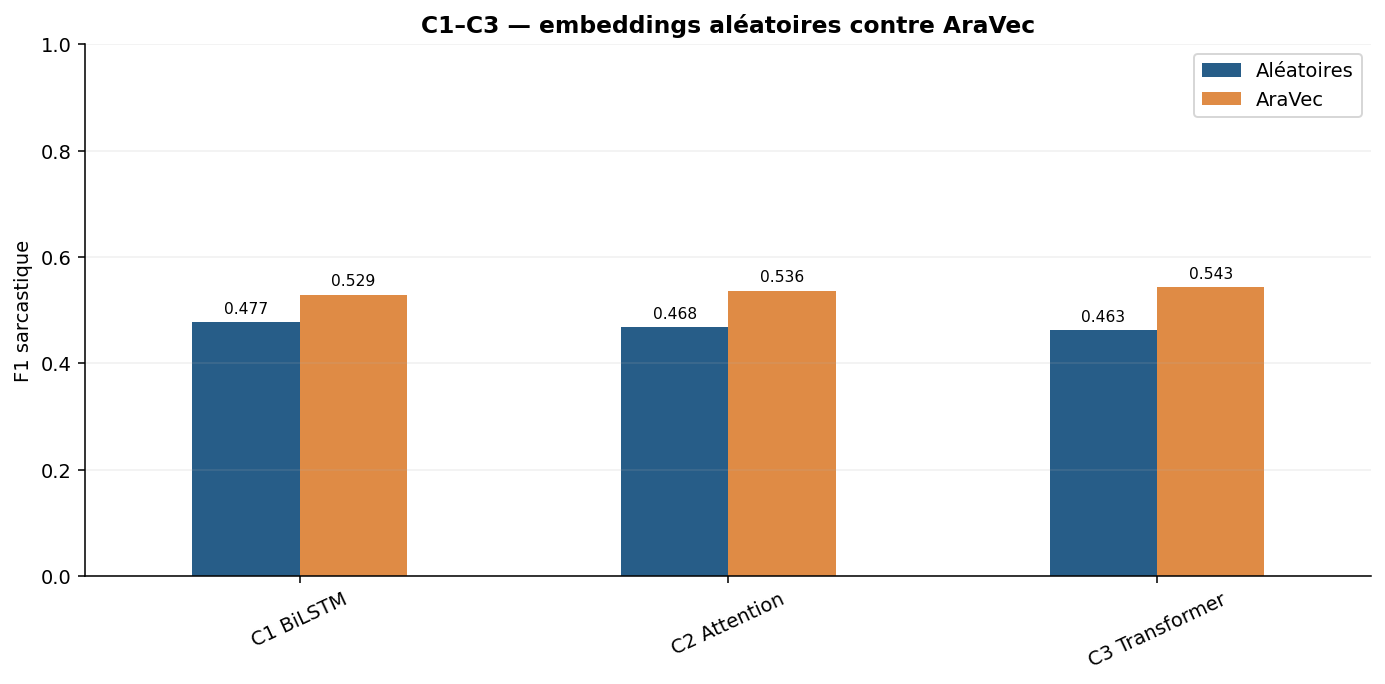

**À présenter :** AraVec améliore les trois architectures dans ces essais à la graine 42. C3 AraVec atteint le meilleur F1 validation de cette famille, 0,5427.

In [ ]:
_TP2_TABLE_TITLES = ['Couverture AraVec']

def clean_str(text):
    search = ["أ","إ","آ","ة","_","-","/",".","،"," و "," يا ",'"',"ـ","'","ى","\\",'\n', '\t','&quot;','?','؟','!']
    replace = ["ا","ا","ا","ه"," "," ","","",""," و"," يا","","","","ي","",' ', ' ',' ',' ? ',' ؟ ',' ! ']
    
    #remove tashkeel
    p_tashkeel = re.compile(r'[\u0617-\u061A\u064B-\u0652]')
    text = re.sub(p_tashkeel,"", text)
    
    #remove longation
    p_longation = re.compile(r'(.)\1+')
    subst = r"\1\1"
    text = re.sub(p_longation, subst, text)
    
    text = text.replace('وو', 'و')
    text = text.replace('يي', 'ي')
    text = text.replace('اا', 'ا')
    
    for i in range(0, len(search)):
        text = text.replace(search[i], replace[i])
    
    #trim    
    text = text.strip()

    return text

matrix_path=ROOT/'models/aravec_train_matrix.npy'

vocab_signature=hashlib.sha256(json.dumps(VOCAB,sort_keys=True,ensure_ascii=False).encode()).hexdigest()

matrix_meta=matrix_path.with_suffix('.cache.json')

if matrix_path.exists() and matrix_meta.exists() and json.loads(matrix_meta.read_text())['vocab_signature']==vocab_signature:
    ARAVEC=np.load(matrix_path); coverage=json.loads((ROOT/'models/aravec_coverage.json').read_text())
else:
    import scipy.linalg
    # Compatibilité gensim 4.3 avec scipy récent, sans modifier le paquet installé.
    if not hasattr(scipy.linalg,'triu'): scipy.linalg.triu=np.triu
    from gensim.models import Word2Vec
    if IN_COLAB: prepare_aravec(ROOT)
    candidates=list((ROOT/'models/aravec').rglob('*.mdl'))
    assert candidates,'AraVec manquant dans models/aravec.'
    vectors=Word2Vec.load(str(candidates[0])).wv
    rng=np.random.default_rng(42); ARAVEC=rng.normal(0,.05,(len(VOCAB),100)).astype('float32'); ARAVEC[0]=0
    found=[]
    for token,i in VOCAB.items():
        normalized=clean_str(token)
        if i>1 and normalized in vectors: ARAVEC[i]=vectors[normalized]; found.append(token)
    coverage={'vocab_types':len(VOCAB)-2,'types_found':len(found),
        'type_coverage':len(found)/max(len(VOCAB)-2,1),
        'train_token_coverage':sum(counts[t] for t in found)/sum(counts.values())}
    np.save(matrix_path,ARAVEC); matrix_meta.write_text(json.dumps({'vocab_signature':vocab_signature})); (ROOT/'models/aravec_coverage.json').write_text(json.dumps(coverage,indent=2))
    del vectors; gc.collect()

display(pd.Series(coverage).to_frame('Couverture AraVec'))

for arch,label in [('bilstm','C1_AraVec'),('attention','C2_AraVec'),('transformer','C3_AraVec')]:
    seed_all(42)
    key,model=train_neural(StaticNet(arch,ARAVEC,freeze=True),[XW_TRAIN],[XW_VAL],label,
        config={'arch':arch,'embedding':'aravec','position':True,'freeze_epochs':2},freeze_epochs=2)
    static_keys.append(key); del model; gc.collect()

# Graphique complémentaire : valeurs de la session courante.
_tp2_plot(pd.DataFrame({'Aléatoires': [next(r['val_f1_sarcastique'] for r in RESULTS if r['model']==m and r['seed']==42) for m in ['C1_BiLSTM','C2_attention','C3_Transformer']], 'AraVec': [next(r['val_f1_sarcastique'] for r in RESULTS if r['model']==m and r['seed']==42) for m in ['C1_AraVec','C2_AraVec','C3_AraVec']]}, index=['C1 BiLSTM','C2 Attention','C3 Transformer']), 'C1–C3 — embeddings aléatoires contre AraVec', 'F1 sarcastique', 'presentation_05', unit_interval=True)

### Présenter les résultats — étape 18

**Phrase de présentation**

> Avec AraVec, C1 atteint 0,5290, C2 0,5362 et C3 0,5427 de F1 validation. Les trois architectures progressent par rapport à leurs embeddings aléatoires. C3 AraVec est le meilleur de cette famille pour la graine 42.

**Support 1 — Couverture AraVec**

> « AraVec retrouve 14 078 des 14 956 types du vocabulaire, soit environ 94,13 %. La couverture des occurrences du train est de 71,94 %, ce qui est une mesure différente. Un mot du vocabulaire couvert et une occurrence couverte ne doivent pas être confondus. »

**Résultat — Lecture simple**

Avec AraVec, les F1 validation sont de 0,5290 pour C1, 0,5362 pour C2 et 0,5427 pour C3. Chaque architecture progresse par rapport à ses embeddings aléatoires dans ces essais.

### Cellule 5. Résultats et ablation du déséquilibre

Je compare les stratégies de traitement du déséquilibre des classes pour le modèle sélectionné sur validation : pondération, sur-échantillonnage et entraînement standard. Je vérifie si elles améliorent le F1.

**Code — Implémentation**

C_meilleur_oversample 42 époque 1 perte 0.5499 F1 val 0.5269
C_meilleur_oversample 42 époque 2 perte 0.4955 F1 val 0.531
C_meilleur_oversample 42 époque 3 perte 0.4609 F1 val 0.5343
C_meilleur_oversample 42 époque 4 perte 0.455 F1 val 0.541
C_meilleur_oversample 42 époque 5 perte 0.4212 F1 val 0.5099
C_meilleur_oversample 42 époque 6 perte 0.4116 F1 val 0.5313
C_meilleur_oversample_seed42 F1 val = 0.541 seuil = 0.8125 temps = 14.1 s
C_meilleur_standard 42 époque 1 perte 0.3963 F1 val 0.5347
C_meilleur_standard 42 époque 2 perte 0.3662 F1 val 0.5294
C_meilleur_standard 42 époque 3 perte 0.3592 F1 val 0.531
C_meilleur_standard_seed42 F1 val = 0.5347 seuil = 0.2939 temps = 7.3 s


#### Déséquilibre et optimisation du seuil

,model,F1_seuil_05,F1_seuil_val,seuil
0,C3_AraVec_seed42,0.503165,0.542694,0.615209
1,C_meilleur_oversample_seed42,0.498516,0.541020,0.812528
2,C_meilleur_standard_seed42,0.439628,0.534653,0.293901


#### Déséquilibre — seuil 0,5 contre seuil validation

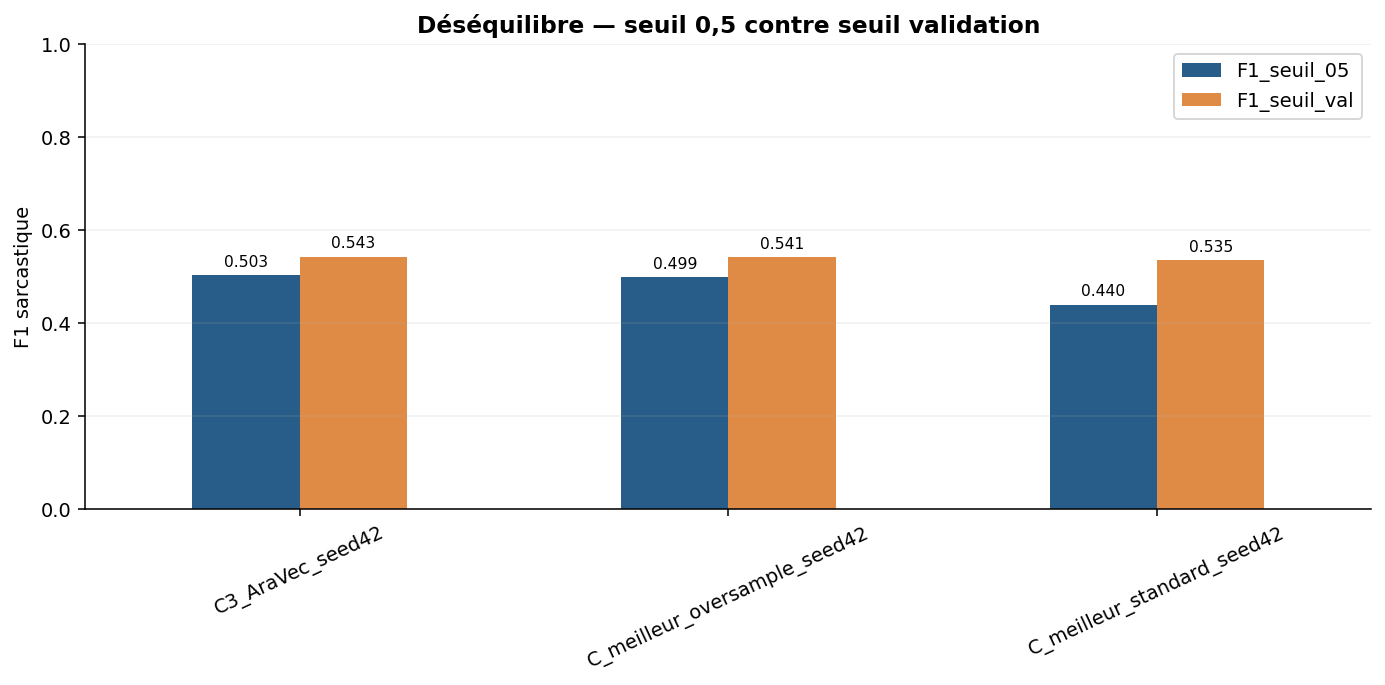

**À présenter :** Choisir le seuil sur validation améliore les trois stratégies. Le sur-échantillonnage ne dépasse pas la perte pondérée dans cet essai.

In [ ]:
_TP2_TABLE_TITLES = ['Déséquilibre et optimisation du seuil']

eligible=pd.DataFrame(RESULTS).loc[lambda d:d.model.str.match(r'C[123]_') & ~d.model.str.contains('sans_position')]

best_c_row=eligible.sort_values('val_f1_sarcastique',ascending=False).iloc[0]

best_c_key=f'{best_c_row.model}_seed42'

BEST_C_CFG=REGISTRY[best_c_key]['config'].copy()

imbalance_keys=[best_c_key]

for imbalance in ['oversample','standard']:
    seed_all(42); cfg=dict(BEST_C_CFG,imbalance=imbalance)
    emb=ARAVEC if cfg['embedding']=='aravec' else None
    key,model=train_neural(StaticNet(cfg['arch'],emb,position=cfg.get('position',True),freeze=emb is not None),
        [XW_TRAIN],[XW_VAL],f'C_meilleur_{imbalance}',config=cfg,imbalance=imbalance,freeze_epochs=cfg.get('freeze_epochs',0))
    imbalance_keys.append(key); static_keys.append(key); del model; gc.collect()

imbalance_table=[]

for key in imbalance_keys:
    p=np.load(ROOT/f'predictions/{key}_val.npy'); rec=REGISTRY[key]
    imbalance_table.append({'model':key,'F1_seuil_05':scores(val.y,p,.5)['f1_sarcastique'],
        'F1_seuil_val':scores(val.y,p,rec['threshold'])['f1_sarcastique'],'seuil':rec['threshold']})

display(pd.DataFrame(imbalance_table))

pd.DataFrame(imbalance_table).to_csv(ROOT/'results/imbalance.csv',index=False)

# Graphique complémentaire : valeurs de la session courante.
_tp2_plot(pd.DataFrame(imbalance_table).set_index('model')[['F1_seuil_05','F1_seuil_val']], 'Déséquilibre — seuil 0,5 contre seuil validation', 'F1 sarcastique', 'presentation_06', unit_interval=True)

### Présenter les résultats — étape 19

**Support 1 — Déséquilibre et optimisation du seuil**

> « Avec un seuil choisi sur validation, la perte pondérée atteint 0,5427 de F1, le sur-échantillonnage 0,5410 et la perte standard 0,5347. Le réglage du seuil améliore les trois résultats par rapport à 0,5. Dans cette expérience, le sur-échantillonnage ne dépasse pas la pondération. »

**Résultat — Lecture simple**

Les sorties ci-dessus comparent les stratégies de déséquilibre. Le choix est effectué sur validation, sans utiliser les scores test.

### Mon interprétation

Les embeddings AraVec améliorent les performances des architectures testées. Dans l’exécution T4, le meilleur modèle de cette famille est C3 avec AraVec, qui obtient un F1 validation de 0,5427. Cela montre l’intérêt du pré-entraînement des représentations lexicales dans cette expérience.

Les résultats affichés proviennent de l’exécution T4 originale ; cette version de présentation n’a pas été réexécutée.

## D. BERT gelé

### Prétraitement AraBERT et extraction gelée

**1. Explication**

**Objectif :** Encoder les tweets avec AraBERT gelé.

**Pourquoi cette méthode ?** Réutiliser les représentations contextuelles limite le nombre de paramètres à entraîner.

**2. Code — Implémentation**

La cellule suivante réalise cette étape.

In [ ]:
_TP2_TABLE_TITLES = []

from arabert.preprocess import ArabertPreprocessor

ARA_PREP=ArabertPreprocessor(model_name=ARA_NAME,remove_non_digit_repetition=False)

assert 'ههههه' in ARA_PREP.preprocess('يا سلاااام 😂 ههههه !!!')

assert 'سلاااام' in ARA_PREP.preprocess('يا سلاااام 😂 ههههه !!!')

print('AraBERT : préprocesseur officiel, conservation explicite des répétitions.')

def plm_texts(texts,name,drop_links=False):
    if name==ARA_NAME:
        # Le préprocesseur officiel gère URL/mentions et conserve les emojis Twitter.
        cleaned=[export_clean(s) for s in texts]
        if drop_links: cleaned=[MENTION_RE.sub(' ',URL_RE.sub(' ',s)) for s in cleaned]
        return [ARA_PREP.preprocess(s) for s in cleaned]
    return [prepare_text(s,'plm',drop_links) for s in texts]

def tokenizer_for(name):
    if name not in TOKENIZERS:
        TOKENIZERS[name]=AutoTokenizer.from_pretrained(REVISIONS[name]['path'],local_files_only=True)
    return TOKENIZERS[name]

def plm_encode(texts,name,drop_links=False):
    tag=['tokenized_v1',name,drop_links,__import__('tokenizers').__version__]
    signature=inference_signature(texts,tag)
    if signature in TOKENIZED: return TOKENIZED[signature]
    folder=ROOT/'models/tokenized'; folder.mkdir(exist_ok=True)
    path=folder/f'{signature}.pt'
    if path.exists():
        payload=torch.load(path,map_location='cpu',weights_only=True)
        inputs=[payload['input_ids'],payload['attention_mask']]
        assert all(x.shape==(len(texts),MAX_LEN) and x.dtype==torch.long for x in inputs)
    else:
        tokenizer=tokenizer_for(name)
        enc=tokenizer(plm_texts(texts,name,drop_links),truncation=True,max_length=MAX_LEN,padding='max_length',return_tensors='pt')
        inputs=[enc['input_ids'],enc['attention_mask']]
        draft=path.with_suffix('.pt.tmp')
        torch.save(dict(zip(['input_ids','attention_mask'],inputs)),draft); draft.replace(path)
    if len(TOKENIZED)>=4: TOKENIZED.pop(next(iter(TOKENIZED)))
    TOKENIZED[signature]=inputs
    return inputs

def frozen_features(texts,split):
    path=ROOT/f'models/frozen_{split}.npy'; maskpath=ROOT/f'models/frozen_{split}_mask.npy'
    if maskpath.exists() and valid_cache(path,texts,'frozen_arabert'): return np.load(path,mmap_mode='r'),np.load(maskpath)
    inputs=plm_encode(texts,ARA_NAME); model=frozen_encoder()
    temp=path.with_name(path.stem+'_partial.npy')
    array=np.lib.format.open_memmap(temp,mode='w+',dtype='float16',shape=(len(texts),MAX_LEN,model.config.hidden_size))
    lengths=inputs[1].sum(1).numpy(); order=np.argsort(-lengths,kind='stable')
    start=time.perf_counter()
    with torch.inference_mode():
        for j in range(0,len(texts),BATCH):
            index=order[j:j+BATCH]; length=int(lengths[index].max())
            ids,mask=[t[index,:length].to(DEVICE) for t in inputs]
            states=model(input_ids=ids,attention_mask=mask).last_hidden_state.cpu().numpy().astype('float16')
            array[index]=0  # Seul le padding absent du calcul est nul ; les tokens valides restent intacts.
            array[index,:length]=states
            if (j//BATCH+1)%50==0: print('Extraction AraBERT',split,min(j+BATCH,len(texts)),'/',len(texts),flush=True)
    array.flush(); del array; temp.replace(path); np.save(maskpath,inputs[1].numpy())
    mark_cache(path,texts,'frozen_arabert')
    (ROOT/f'results/frozen_{split}_time.json').write_text(json.dumps({'seconds':time.perf_counter()-start}))
    return np.load(path,mmap_mode='r'),inputs[1].numpy()

AraBERT : préprocesseur officiel, conservation explicite des répétitions.


### Présenter les résultats — étape 20

**Phrase de présentation**

> AraBERT utilise son prétraitement officiel en conservant explicitement les répétitions. L’objectif est de respecter les attentes de l’encodeur sans effacer inutilement les indices expressifs.

**3. Résultat — Visualisation**

Les sorties enregistrées ci-dessus proviennent de l’exécution originale : tableaux, métriques, graphiques ou journaux selon cette étape.

**4. Mon interprétation**

Cette étape extrait les représentations ; le coût d’extraction doit être distingué du coût d’apprentissage de la tête.

### CLS et mean pooling

**1. Explication**

**Objectif :** Comparer CLS et moyenne des tokens avec une régression logistique.

**Pourquoi cette méthode ?** Le pooling transforme une séquence de vecteurs en représentation de tweet.

**2. Code — Implémentation**

La cellule suivante réalise cette étape.

In [ ]:
_TP2_TABLE_TITLES = []

FT,MT=frozen_features(train.tweet.tolist(),'train')

FV,MV=frozen_features(val.tweet.tolist(),'val')

def pooled_features(h,m,mode):
    if mode=='cls': return np.asarray(h[:,0],dtype=np.float32)
    result=np.empty((len(h),h.shape[-1]),dtype=np.float32)
    for start in range(0,len(h),64):
        stop=start+64
        block=np.asarray(h[start:stop],dtype=np.float32)
        mask=m[start:stop,:,None]
        result[start:stop]=(block*mask).sum(1)/m[start:stop].sum(1,keepdims=True)
    return result

d_keys=[]

for pooling in ['cls','mean']:
    path=ROOT/f'models/D1_{pooling}_seed42.joblib'; start=time.perf_counter()
    clf=LogisticRegression(C=1,class_weight='balanced',max_iter=1500,random_state=42)
    clf.fit(pooled_features(FT,MT,pooling),train.y); elapsed=time.perf_counter()-start; joblib.dump(clf,path)
    p=clf.predict_proba(pooled_features(FV,MV,pooling))[:,1]
    d_keys.append(register(f'D1_{pooling}',42,p,elapsed,clf.coef_.size+1,'arabert_official','frozen_lr',path,{'pooling':pooling}))

Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Extraction AraBERT train 1600 / 10842
Extraction AraBERT train 3200 / 10842
Extraction AraBERT train 4800 / 10842
Extraction AraBERT train 6400 / 10842
Extraction AraBERT train 8000 / 10842
Extraction AraBERT train 9600 / 10842


D1_cls_seed42 F1 val = 0.6054 seuil = 0.6799 temps = 4.7 s
D1_mean_seed42 F1 val = 0.6316 seuil = 0.7294 temps = 7.3 s


### Présenter les résultats — étape 21

**Phrase de présentation**

> Avec AraBERT gelé, la moyenne masquée atteint 0,6316 de F1 validation contre 0,6054 pour CLS. La moyenne est meilleure dans cette comparaison ; les temps d’ajustement de la régression ne comprennent pas toute l’extraction des représentations.

**3. Résultat — Visualisation**

Les sorties enregistrées ci-dessus proviennent de l’exécution originale : tableaux, métriques, graphiques ou journaux selon cette étape.

**4. Mon interprétation**

Le tableau permet de choisir le pooling sur validation ; ce choix doit rester indépendant du test.

### BiLSTM avec attention

**1. Explication**

**Objectif :** Ajouter une tête BiLSTM avec attention sur les états gelés.

**Pourquoi cette méthode ?** La tête apprend à combiner les représentations sans ajuster l’encodeur.

**2. Code — Implémentation**

La cellule suivante réalise cette étape.

In [ ]:
_TP2_TABLE_TITLES = []

class FrozenHead(nn.Module):
    def __init__(self,dim=768):
        super().__init__(); self.encoder=nn.LSTM(dim,64,batch_first=True,bidirectional=True)
        self.attention=AttentionPool(128); self.drop=nn.Dropout(.25); self.head=nn.Linear(128,2)
    def forward(self,h,mask,return_attention=False):
        h=h.float(); mask=mask.bool()
        packed=nn.utils.rnn.pack_padded_sequence(h,mask.sum(1).cpu(),batch_first=True,enforce_sorted=False)
        packed,_=self.encoder(packed); h,_=nn.utils.rnn.pad_packed_sequence(packed,batch_first=True,total_length=mask.shape[1])
        c,a=self.attention(h,mask); out=self.head(self.drop(c))
        return (out,a) if return_attention else out

seed_all(42)

DXT=[torch.from_numpy(np.array(FT)),torch.tensor(MT)]

DXV=[torch.from_numpy(np.array(FV)),torch.tensor(MV)]

d2_key,d2_model=train_neural(FrozenHead(),DXT,DXV,'D2_BiLSTM_attention',
    config={'kind':'frozen_head','preprocessing':'arabert_official'})

d_keys.append(d2_key)

p_att,att=neural_predict(d2_model,DXV,attention=True)

chosen=np.flatnonzero(val.y.to_numpy()==1)[:5]

tokenizer_ara=AutoTokenizer.from_pretrained(REVISIONS[ARA_NAME]['path'],local_files_only=True)

val_ids=plm_encode(val.tweet.tolist(),ARA_NAME)[0]

attention_rows=[]

D2_BiLSTM_attention 42 époque 1 perte 0.4462 F1 val 0.6625
D2_BiLSTM_attention 42 époque 2 perte 0.3422 F1 val 0.6557
D2_BiLSTM_attention 42 époque 3 perte 0.2585 F1 val 0.6555
D2_BiLSTM_attention_seed42 F1 val = 0.6625 seuil = 0.6983 temps = 12.7 s


### Présenter les résultats — étape 22

**Phrase de présentation**

> La tête BiLSTM avec attention sur AraBERT gelé atteint 0,6625 de F1 validation pour la graine 42. Elle dépasse ici les deux têtes linéaires, au prix d’une tête plus complexe.

**3. Résultat — Visualisation**

Les sorties enregistrées ci-dessus proviennent de l’exécution originale : tableaux, métriques, graphiques ou journaux selon cette étape.

**4. Mon interprétation**

Il faut comparer son F1 et son coût aux têtes simples pour juger l’intérêt de cette complexité supplémentaire.

### Visualisation de l’attention

**1. Explication**

**Objectif :** Afficher les poids d’attention sur des exemples.

**Pourquoi cette méthode ?** La visualisation aide à examiner les tokens mis en avant.

**2. Code — Implémentation**

La cellule suivante réalise cette étape.

#### Attention : tweet 1

#### Attention : tweet 2

#### Attention : tweet 3

#### Attention : tweet 4

#### Attention : tweet 5

#### Comparaison des cinq profils d’attention

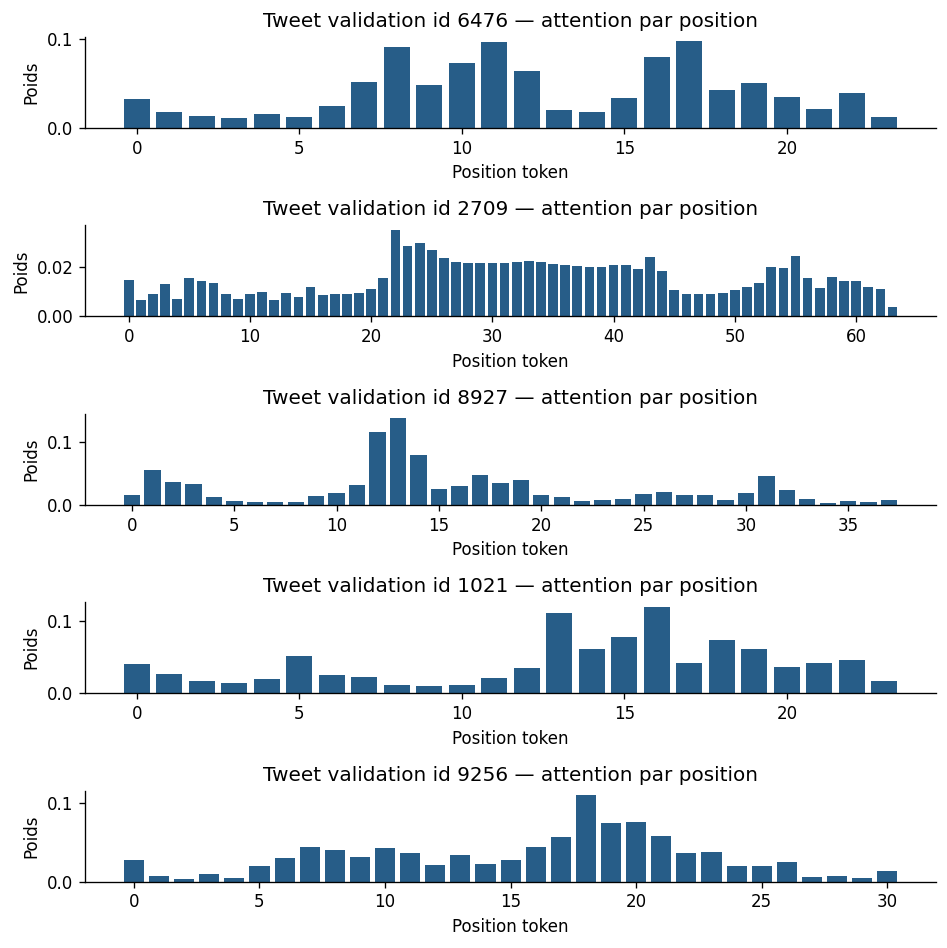

3244

In [ ]:
_TP2_TABLE_TITLES = ['Attention : tweet 1', 'Attention : tweet 2', 'Attention : tweet 3', 'Attention : tweet 4', 'Attention : tweet 5']

for i in chosen:
    length=int(MV[i].sum()); tokens=tokenizer_ara.convert_ids_to_tokens(val_ids[i,:length])
    weights=att[i,:length]
    cells=' '.join(f'<span title="{w:.4f}" style="background:rgba(35,110,180,{float(w/weights.max()):.3f});padding:4px;display:inline-block">{html.escape(t)}</span>' for t,w in zip(tokens,weights))
    display(HTML(f'<div dir="rtl" style="line-height:2.5">{cells}</div>'))
    attention_rows.extend({'val_id':int(val.iloc[i].id),'token':t,'attention':float(w)} for t,w in zip(tokens,weights))

pd.DataFrame(attention_rows).to_csv(ROOT/'results/attention_five_tweets.csv',index=False,encoding='utf-8-sig')

fig,axes=plt.subplots(5,1,figsize=(8,8))

for ax,i in zip(axes,chosen):
    length=int(MV[i].sum()); ax.bar(np.arange(length),att[i,:length],color='#275D88')
    ax.set(title=f'Tweet validation id {int(val.iloc[i].id)} — attention par position',ylabel='Poids',xlabel='Position token')

savefig(fig,'attention_five_tweets')

del d2_model,DXT,DXV

FROZEN_MODELS.clear()  # Ne pas conserver l’encodeur gelé pendant E.
gc.collect()

### Présenter les résultats — étape 23

**Support 1 — Attention : tweet 1**

> « Ce 1e exemple montre comment la tête d’attention répartit son poids entre les tokens. Je repère les mots les plus mis en évidence, puis je les relis dans la phrase arabe. Un poids élevé indique une importance dans ce calcul ; il ne prouve pas que le modèle comprend le sarcasme. »

**Support 2 — Attention : tweet 2**

> « Ce 2e exemple montre comment la tête d’attention répartit son poids entre les tokens. Je repère les mots les plus mis en évidence, puis je les relis dans la phrase arabe. Un poids élevé indique une importance dans ce calcul ; il ne prouve pas que le modèle comprend le sarcasme. »

**Support 3 — Attention : tweet 3**

> « Ce 3e exemple montre comment la tête d’attention répartit son poids entre les tokens. Je repère les mots les plus mis en évidence, puis je les relis dans la phrase arabe. Un poids élevé indique une importance dans ce calcul ; il ne prouve pas que le modèle comprend le sarcasme. »

**Support 4 — Attention : tweet 4**

> « Ce 4e exemple montre comment la tête d’attention répartit son poids entre les tokens. Je repère les mots les plus mis en évidence, puis je les relis dans la phrase arabe. Un poids élevé indique une importance dans ce calcul ; il ne prouve pas que le modèle comprend le sarcasme. »

**Support 5 — Attention : tweet 5**

> « Ce 5e exemple montre comment la tête d’attention répartit son poids entre les tokens. Je repère les mots les plus mis en évidence, puis je les relis dans la phrase arabe. Un poids élevé indique une importance dans ce calcul ; il ne prouve pas que le modèle comprend le sarcasme. »

**Support 6 — Comparaison des cinq profils d’attention**

> « Les cinq panneaux présentent les profils d’attention des tweets précédents. Je compare la concentration des poids : certains tokens peuvent dominer, mais leur rôle doit être interprété avec le sens de chaque tweet. Cette visualisation complète les métriques sans constituer une explication causale. »

**À l’oral :** je lis chaque tweet arabe avant de commenter ses tokens. Je n’attribue pas une signification linguistique aux couleurs sans vérifier le contexte.

**3. Résultat — Visualisation**

Les sorties enregistrées ci-dessus proviennent de l’exécution originale : tableaux, métriques, graphiques ou journaux selon cette étape.

**4. Mon interprétation**

L’attention fournit un indice de lecture, mais ne démontre pas à elle seule la cause d’une prédiction.

## E. Fine-tuning

### Architecture mono-tâche et multi-tâche

**1. Explication**

**Objectif :** Définir les versions mono-tâche et multi-tâche.

**Pourquoi cette méthode ?** La tâche auxiliaire de sentiment peut aider la représentation du sarcasme.

**2. Code — Implémentation**

La cellule suivante réalise cette étape.

In [ ]:
_TP2_TABLE_TITLES = []

class FineTuneNet(nn.Module):
    def __init__(self,name,multitask=False,encoder=None):
        super().__init__(); self.enc=load_hf(name) if encoder is None else encoder; h=self.enc.config.hidden_size
        # La tête utilise le CLS brut, pas le pooler ; ses poids ne reçoivent aucun gradient.
        if getattr(self.enc,'pooler',None) is not None: self.enc.pooler.requires_grad_(False)
        self.drop=nn.Dropout(.1); self.sarc=nn.Linear(h,2)
        self.sent=nn.Linear(h,3) if multitask else None
    def forward(self,input_ids,attention_mask):
        length=int(attention_mask.sum(1).max())
        input_ids=input_ids[:,:length]; attention_mask=attention_mask[:,:length]
        cls=self.drop(self.enc(input_ids=input_ids,attention_mask=attention_mask).last_hidden_state[:,0])
        logits=self.sarc(cls)
        return (logits,self.sent(cls)) if self.sent is not None else logits

e_keys=[]

E_BEST_LAMBDA={}

### Présenter les résultats — étape 24

**Phrase de présentation**

> E1 apprend seulement le sarcasme ; E2 partage un encodeur entre sarcasme et sentiment. La définition de l’architecture ne suffit pas à prouver que la tâche auxiliaire aide.

**3. Résultat — Visualisation**

Cette cellule définit des fonctions ou des paramètres. Elle ne produit pas de métrique ni de graphique ; leur utilisation est montrée dans les étapes suivantes.

**4. Mon interprétation**

Le bénéfice du multi-tâche est une hypothèse à tester, pas une conséquence automatique de l’architecture.

### Grille lambda et répétitions

**1. Explication**

**Objectif :** Définir la grille de lambda et les répétitions.

**Pourquoi cette méthode ?** Lambda règle le poids de la tâche auxiliaire ; plusieurs graines mesurent la variabilité.

**2. Code — Implémentation**

La cellule suivante réalise cette étape.

In [ ]:
_TP2_TABLE_TITLES = []

def run_plm_grid(name,short):
    xt=plm_encode(train.tweet.tolist(),name); xv=plm_encode(val.tweet.tolist(),name)
    tok=tokenizer_for(name)
    lengths=[len(ids) for ids in tok(plm_texts(train.tweet.tolist(),name),add_special_tokens=True)['input_ids']]
    print(short,'train tronqué à 64 :',sum(n>MAX_LEN for n in lengths),'/',len(lengths),flush=True)
    for lam in [0,.3,.5,1.]:
        seed_all(42); label=f'E1_{short}_mono' if lam==0 else f'E2_{short}_lambda{str(lam).replace(".","p")}'
        cfg={'model_name':name,'multitask':lam>0,'preprocessing':'arabert_official' if name==ARA_NAME else 'plm_minimal'}
        key,model=train_neural(FineTuneNet(name,lam>0),xt,xv,label,seed=42,config=cfg,
            epochs=PLM_EPOCHS,lr=2e-5,lam=lam,plm=True)
        e_keys.append(key); del model; gc.collect()
    del xt,xv; gc.collect()

def repeat_plm_finals(name,short):
    xt=plm_encode(train.tweet.tolist(),name); xv=plm_encode(val.tweet.tolist(),name)
    multi=[k for k in e_keys if REGISTRY[k]['name'].startswith(f'E2_{short}')]
    chosen_key=max(multi,key=lambda k:next(r['val_f1_sarcastique'] for r in RESULTS if r['model']==REGISTRY[k]['name'] and r['seed']==42))
    chosen_lam=REGISTRY[chosen_key]['config']['lam']; E_BEST_LAMBDA[short]=chosen_lam
    for lam in [0,chosen_lam]:
        label=f'E1_{short}_mono' if lam==0 else REGISTRY[chosen_key]['name']
        for seed in [43,44]:
            seed_all(seed); cfg={'model_name':name,'multitask':lam>0,'preprocessing':'arabert_official' if name==ARA_NAME else 'plm_minimal'}
            key,model=train_neural(FineTuneNet(name,lam>0),xt,xv,label,seed=seed,config=cfg,
                epochs=PLM_EPOCHS,lr=2e-5,lam=lam,plm=True)
            e_keys.append(key); del model; gc.collect()
    del xt,xv; gc.collect()

### Présenter les résultats — étape 25

**Phrase de présentation**

> Je teste lambda 0,3, 0,5 et 1 sur validation. Lambda règle le poids du sentiment ; je ne choisis jamais sa valeur à partir du test.

**3. Résultat — Visualisation**

Cette cellule définit des fonctions ou des paramètres. Elle ne produit pas de métrique ni de graphique ; leur utilisation est montrée dans les étapes suivantes.

**4. Mon interprétation**

Le meilleur lambda est choisi sur validation et les répétitions permettent d’éviter une conclusion fondée sur une seule graine.

### AraBERT : E1 et E2

**1. Explication**

**Objectif :** Entraîner et évaluer E1/E2 avec AraBERT.

**Pourquoi cette méthode ?** La comparaison isole l’apport de la tâche auxiliaire pour le même encodeur.

**2. Code — Implémentation**

La cellule suivante réalise cette étape.

In [ ]:
_TP2_TABLE_TITLES = []

run_plm_grid(ARA_NAME,"AraBERT")

repeat_plm_finals(ARA_NAME,"AraBERT")

AraBERT train tronqué à 64 : 76 / 10842


Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at /pytorch/aten/src/ATen/native/transformers/cuda/attention_backward.cu:900.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


E1_AraBERT_mono 42 époque 1 batch 50 / 339 perte 0.6804
E1_AraBERT_mono 42 époque 1 batch 100 / 339 perte 0.6119
E1_AraBERT_mono 42 époque 1 batch 150 / 339 perte 0.5591
E1_AraBERT_mono 42 époque 1 batch 200 / 339 perte 0.5257
E1_AraBERT_mono 42 époque 1 batch 250 / 339 perte 0.4998
E1_AraBERT_mono 42 époque 1 batch 300 / 339 perte 0.4942
E1_AraBERT_mono 42 époque 1 perte 0.4842 F1 val 0.6653
E1_AraBERT_mono 42 époque 2 batch 50 / 339 perte 0.3111
E1_AraBERT_mono 42 époque 2 batch 100 / 339 perte 0.318
E1_AraBERT_mono 42 époque 2 batch 150 / 339 perte 0.315
E1_AraBERT_mono 42 époque 2 batch 200 / 339 perte 0.3195
E1_AraBERT_mono 42 époque 2 batch 250 / 339 perte 0.315
E1_AraBERT_mono 42 époque 2 batch 300 / 339 perte 0.3131
E1_AraBERT_mono 42 époque 2 perte 0.3115 F1 val 0.6582
E1_AraBERT_mono 42 époque 3 batch 50 / 339 perte 0.2096
E1_AraBERT_mono 42 époque 3 batch 100 / 339 perte 0.2171
E1_AraBERT_mono 42 époque 3 batch 150 / 339 perte 0.2119
E1_AraBERT_mono 42 époque 3 batch 200 / 3

Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


E2_AraBERT_lambda0p3 42 époque 1 batch 50 / 339 perte 1.0028
E2_AraBERT_lambda0p3 42 époque 1 batch 100 / 339 perte 0.9117
E2_AraBERT_lambda0p3 42 époque 1 batch 150 / 339 perte 0.8319
E2_AraBERT_lambda0p3 42 époque 1 batch 200 / 339 perte 0.7828
E2_AraBERT_lambda0p3 42 époque 1 batch 250 / 339 perte 0.7451
E2_AraBERT_lambda0p3 42 époque 1 batch 300 / 339 perte 0.7286
E2_AraBERT_lambda0p3 42 époque 1 perte 0.7128 F1 val 0.6638
E2_AraBERT_lambda0p3 42 époque 2 batch 50 / 339 perte 0.4882
E2_AraBERT_lambda0p3 42 époque 2 batch 100 / 339 perte 0.4905
E2_AraBERT_lambda0p3 42 époque 2 batch 150 / 339 perte 0.4898
E2_AraBERT_lambda0p3 42 époque 2 batch 200 / 339 perte 0.4915
E2_AraBERT_lambda0p3 42 époque 2 batch 250 / 339 perte 0.4863
E2_AraBERT_lambda0p3 42 époque 2 batch 300 / 339 perte 0.4849
E2_AraBERT_lambda0p3 42 époque 2 perte 0.4834 F1 val 0.668
E2_AraBERT_lambda0p3 42 époque 3 batch 50 / 339 perte 0.367
E2_AraBERT_lambda0p3 42 époque 3 batch 100 / 339 perte 0.3726
E2_AraBERT_lambda

...

E1_AraBERT_mono 44 époque 1 batch 50 / 339 perte 0.6573
E1_AraBERT_mono 44 époque 1 batch 100 / 339 perte 0.5861
E1_AraBERT_mono 44 époque 1 batch 150 / 339 perte 0.541
E1_AraBERT_mono 44 époque 1 batch 200 / 339 perte 0.5185
E1_AraBERT_mono 44 époque 1 batch 250 / 339 perte 0.5034
E1_AraBERT_mono 44 époque 1 batch 300 / 339 perte 0.4896
E1_AraBERT_mono 44 époque 1 perte 0.476 F1 val 0.6829
E1_AraBERT_mono 44 époque 2 batch 50 / 339 perte 0.299
E1_AraBERT_mono 44 époque 2 batch 100 / 339 perte 0.3115
E1_AraBERT_mono 44 époque 2 batch 150 / 339 perte 0.3179
E1_AraBERT_mono 44 époque 2 batch 200 / 339 perte 0.3101
E1_AraBERT_mono 44 époque 2 batch 250 / 339 perte 0.3164
E1_AraBERT_mono 44 époque 2 batch 300 / 339 perte 0.3161
E1_AraBERT_mono 44 époque 2 perte 0.3153 F1 val 0.6785
E1_AraBERT_mono 44 époque 3 batch 50 / 339 perte 0.2357
E1_AraBERT_mono 44 époque 3 batch 100 / 339 perte 0.2355
E1_AraBERT_mono 44 époque 3 batch 150 / 339 perte 0.232
E1_AraBERT_mono 44 époque 3 batch 200 / 33

Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


E2_AraBERT_lambda0p3 43 époque 1 batch 50 / 339 perte 1.0595
E2_AraBERT_lambda0p3 43 époque 1 batch 100 / 339 perte 0.927
E2_AraBERT_lambda0p3 43 époque 1 batch 150 / 339 perte 0.8377
E2_AraBERT_lambda0p3 43 époque 1 batch 200 / 339 perte 0.7904
E2_AraBERT_lambda0p3 43 époque 1 batch 250 / 339 perte 0.7575
E2_AraBERT_lambda0p3 43 époque 1 batch 300 / 339 perte 0.7359
E2_AraBERT_lambda0p3 43 époque 1 perte 0.7216 F1 val 0.6808
E2_AraBERT_lambda0p3 43 époque 2 batch 50 / 339 perte 0.4939
E2_AraBERT_lambda0p3 43 époque 2 batch 100 / 339 perte 0.4884
E2_AraBERT_lambda0p3 43 époque 2 batch 150 / 339 perte 0.4829
E2_AraBERT_lambda0p3 43 époque 2 batch 200 / 339 perte 0.483
E2_AraBERT_lambda0p3 43 époque 2 batch 250 / 339 perte 0.4814
E2_AraBERT_lambda0p3 43 époque 2 batch 300 / 339 perte 0.4749
E2_AraBERT_lambda0p3 43 époque 2 perte 0.4825 F1 val 0.6776
E2_AraBERT_lambda0p3 43 époque 3 batch 50 / 339 perte 0.3792
E2_AraBERT_lambda0p3 43 époque 3 batch 100 / 339 perte 0.3781
E2_AraBERT_lambda

Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


E2_AraBERT_lambda0p3 44 époque 1 batch 50 / 339 perte 1.0202
E2_AraBERT_lambda0p3 44 époque 1 batch 100 / 339 perte 0.9033
E2_AraBERT_lambda0p3 44 époque 1 batch 150 / 339 perte 0.8299
E2_AraBERT_lambda0p3 44 époque 1 batch 200 / 339 perte 0.7851
E2_AraBERT_lambda0p3 44 époque 1 batch 250 / 339 perte 0.7542
E2_AraBERT_lambda0p3 44 époque 1 batch 300 / 339 perte 0.7291
E2_AraBERT_lambda0p3 44 époque 1 perte 0.709 F1 val 0.6905
E2_AraBERT_lambda0p3 44 époque 2 batch 50 / 339 perte 0.4802
E2_AraBERT_lambda0p3 44 époque 2 batch 100 / 339 perte 0.487
E2_AraBERT_lambda0p3 44 époque 2 batch 150 / 339 perte 0.4915
E2_AraBERT_lambda0p3 44 époque 2 batch 200 / 339 perte 0.4823
E2_AraBERT_lambda0p3 44 époque 2 batch 250 / 339 perte 0.4897
E2_AraBERT_lambda0p3 44 époque 2 batch 300 / 339 perte 0.4897
E2_AraBERT_lambda0p3 44 époque 2 perte 0.4863 F1 val 0.6742
E2_AraBERT_lambda0p3 44 époque 3 batch 50 / 339 perte 0.3902
E2_AraBERT_lambda0p3 44 époque 3 batch 100 / 339 perte 0.389
E2_AraBERT_lambda0

### Présenter les résultats — étape 26

**Phrase de présentation**

> Pour AraBERT graine 42, E1 atteint 0,6653 de F1 validation. E2 atteint 0,6731 avec lambda 0,3, contre 0,6718 avec 0,5 et 1. Le gain reste modeste ; les autres graines sont nécessaires pour le mettre en perspective.

**Pour lire les journaux :** la perte décrit l’apprentissage, mais le checkpoint est choisi avec le F1 validation. À l’oral, je présente le score retenu et la comparaison ; je ne lis pas chaque batch. Les avertissements techniques ne sont pas des métriques.

**3. Résultat — Visualisation**

Les sorties enregistrées ci-dessus proviennent de l’exécution originale : tableaux, métriques, graphiques ou journaux selon cette étape.

**4. Mon interprétation**

Les sorties donnent les scores par époque et par graine ; la comparaison finale utilisera leurs moyennes plutôt qu’un seul meilleur run.

### MARBERT : E1 et E2

**1. Explication**

**Objectif :** Entraîner et évaluer E1/E2 avec MARBERT.

**Pourquoi cette méthode ?** Un second encodeur vérifie si les résultats dépendent du modèle préentraîné.

**2. Code — Implémentation**

La cellule suivante réalise cette étape.

MARBERT train tronqué à 64 : 35 / 10842
E1_MARBERT_mono 42 époque 1 batch 50 / 339 perte 0.6728
E1_MARBERT_mono 42 époque 1 batch 100 / 339 perte 0.6216
E1_MARBERT_mono 42 époque 1 batch 150 / 339 perte 0.5602
E1_MARBERT_mono 42 époque 1 batch 200 / 339 perte 0.5249
E1_MARBERT_mono 42 époque 1 batch 250 / 339 perte 0.4984
E1_MARBERT_mono 42 époque 1 batch 300 / 339 perte 0.4884
E1_MARBERT_mono 42 époque 1 perte 0.4789 F1 val 0.671
E1_MARBERT_mono 42 époque 2 batch 50 / 339 perte 0.2889
E1_MARBERT_mono 42 époque 2 batch 100 / 339 perte 0.2952
E1_MARBERT_mono 42 époque 2 batch 150 / 339 perte 0.2982
E1_MARBERT_mono 42 époque 2 batch 200 / 339 perte 0.3021
E1_MARBERT_mono 42 époque 2 batch 250 / 339 perte 0.2979
E1_MARBERT_mono 42 époque 2 batch 300 / 339 perte 0.2968
E1_MARBERT_mono 42 époque 2 perte 0.293 F1 val 0.649
E1_MARBERT_mono 42 époque 3 batch 50 / 339 perte 0.1765
E1_MARBERT_mono 42 époque 3 batch 100 / 339 perte 0.1871
E1_MARBERT_mono 42 époque 3 batch 150 / 339 perte 0.1866
E

E1_MARBERT_mono 43 époque 1 batch 50 / 339 perte 0.6592
E1_MARBERT_mono 43 époque 1 batch 100 / 339 perte 0.6006
E1_MARBERT_mono 43 époque 1 batch 150 / 339 perte 0.5504
E1_MARBERT_mono 43 époque 1 batch 200 / 339 perte 0.5175
E1_MARBERT_mono 43 époque 1 batch 250 / 339 perte 0.4971
E1_MARBERT_mono 43 époque 1 batch 300 / 339 perte 0.484
E1_MARBERT_mono 43 époque 1 perte 0.4758 F1 val 0.6558
E1_MARBERT_mono 43 époque 2 batch 50 / 339 perte 0.2888
E1_MARBERT_mono 43 époque 2 batch 100 / 339 perte 0.2813
E1_MARBERT_mono 43 époque 2 batch 150 / 339 perte 0.2853
E1_MARBERT_mono 43 époque 2 batch 200 / 339 perte 0.2841
E1_MARBERT_mono 43 époque 2 batch 250 / 339 perte 0.2893
E1_MARBERT_mono 43 époque 2 batch 300 / 339 perte 0.2864
E1_MARBERT_mono 43 époque 2 perte 0.2918 F1 val 0.6609
E1_MARBERT_mono 43 époque 3 batch 50 / 339 perte 0.2038
E1_MARBERT_mono 43 époque 3 batch 100 / 339 perte 0.187
E1_MARBERT_mono 43 époque 3 batch 150 / 339 perte 0.1848
E1_MARBERT_mono 43 époque 3 batch 200 / 

#### AraBERT, MARBERT, mono-tâche et multi-tâche

,model,seed,val_f1_sarcastique,train_seconds,trainable_parameters,epochs_completed
20,E1_AraBERT_mono,42,0.665331,147.761798,134604290,3.0
21,E2_AraBERT_lambda0p3,42,0.673114,158.065143,134606597,3.0
22,E2_AraBERT_lambda0p5,42,0.671785,232.698576,134606597,3.0
23,E2_AraBERT_lambda1p0,42,0.671845,231.360485,134606597,3.0
24,E1_AraBERT_mono,43,0.674584,149.197238,134604290,3.0
25,E1_AraBERT_mono,44,0.682927,132.673082,134604290,3.0
26,E2_AraBERT_lambda0p3,43,0.683486,136.541604,134606597,3.0
27,E2_AraBERT_lambda0p3,44,0.690526,133.996012,134606597,3.0
28,E1_MARBERT_mono,42,0.670968,158.330648,162252290,3.0
29,E2_MARBERT_lambda0p3,42,0.660754,154.621989,162254597,3.0


#### Fine-tuning — F1 validation moyen par modèle

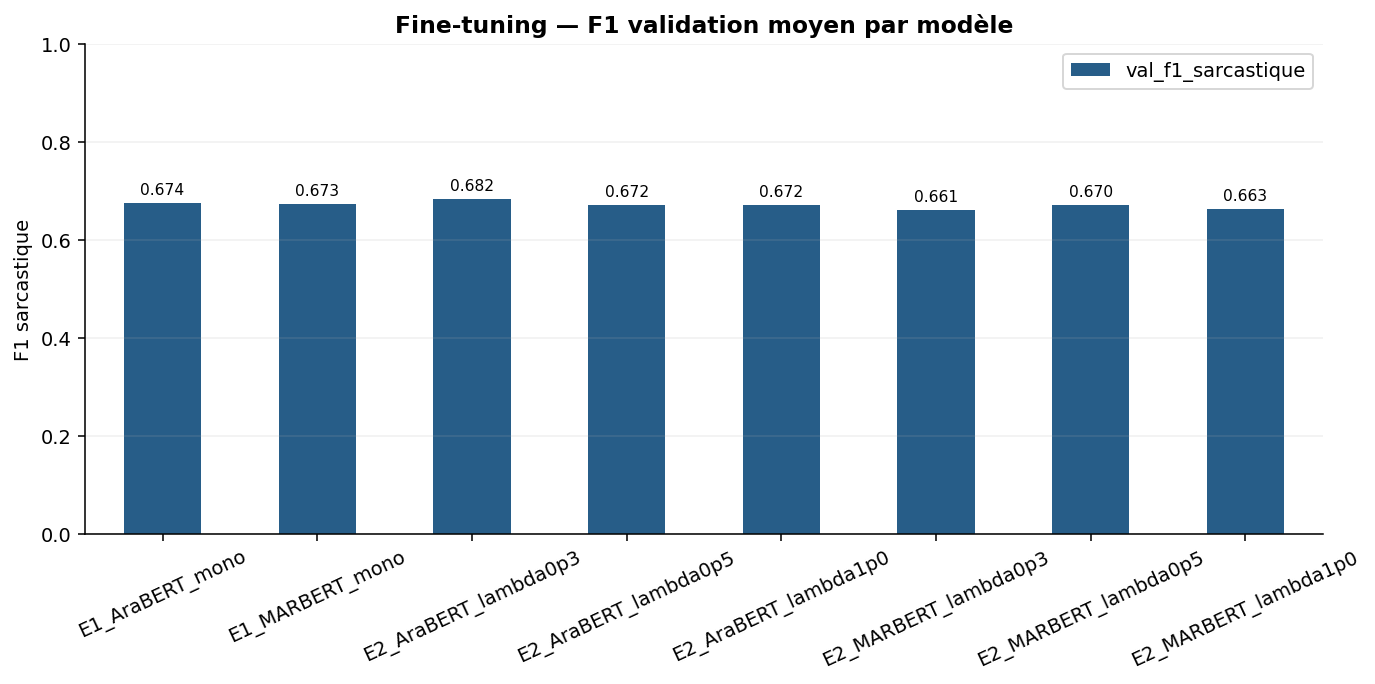

**À présenter :** Chaque barre résume les graines disponibles du modèle. Les lambda non retenus n’ont qu’une graine : cette comparaison ne donne pas la même précision pour chaque barre.

In [ ]:
_TP2_TABLE_TITLES = ['AraBERT, MARBERT, mono-tâche et multi-tâche']

run_plm_grid(MAR_NAME,"MARBERT")

repeat_plm_finals(MAR_NAME,"MARBERT")

display(pd.DataFrame(RESULTS).loc[lambda d:d.model.str.startswith('E')][['model','seed','val_f1_sarcastique','train_seconds','trainable_parameters','epochs_completed']])

# Graphique complémentaire : valeurs de la session courante.
_tp2_plot(pd.DataFrame(RESULTS).loc[lambda d:d.model.str.startswith('E')].groupby('model')[['val_f1_sarcastique']].mean(), 'Fine-tuning — F1 validation moyen par modèle', 'F1 sarcastique', 'presentation_07', unit_interval=True)

### Présenter les résultats — étape 27

**Support 1 — AraBERT, MARBERT, mono-tâche et multi-tâche**

> « Ce tableau rassemble les essais de fine-tuning. Pour la graine 42, AraBERT multi-tâche obtient son meilleur F1 validation avec lambda 0,3 : 0,6731. Pour MARBERT multi-tâche, lambda 0,5 atteint 0,6667. Les répétitions montrent une variabilité ; le choix final repose sur les moyennes de validation, jamais sur le test. »

**Pour lire les journaux :** la perte décrit l’apprentissage, mais le checkpoint est choisi avec le F1 validation. À l’oral, je présente le score retenu et la comparaison ; je ne lis pas chaque batch. Les avertissements techniques ne sont pas des métriques.

**3. Résultat — Visualisation**

Les sorties enregistrées ci-dessus proviennent de l’exécution originale : tableaux, métriques, graphiques ou journaux selon cette étape.

**4. Mon interprétation**

AraBERT et MARBERT doivent être départagés sur validation avec le même protocole, avant consultation du test.

### Sélection sur validation

**1. Explication**

**Objectif :** Sélectionner un représentant par famille sur validation.

**Pourquoi cette méthode ?** Cette sélection fixe les candidats sans utiliser les labels test.

**2. Code — Implémentation**

La cellule suivante réalise cette étape.

In [ ]:
_TP2_TABLE_TITLES = []

def row_for_key(key):
    rec=REGISTRY[key]; return next(r for r in RESULTS if r['model']==rec['name'] and r['seed']==rec['seed'])

best_a_key=max(baseline_keys,key=lambda k:row_for_key(k)['val_f1_sarcastique'])

best_c_key=max(static_keys,key=lambda k:row_for_key(k)['val_f1_sarcastique'])

best_d_key=max(d_keys,key=lambda k:row_for_key(k)['val_f1_sarcastique'])

edf=pd.DataFrame(RESULTS).loc[lambda d:d.model.str.startswith('E')]

best_e1_name=edf.loc[edf.model.str.startswith('E1')].groupby('model').val_f1_sarcastique.mean().idxmax()

e2_averages=edf.loc[edf.model.str.startswith('E2')].groupby('model').val_f1_sarcastique.agg(['mean','count'])

best_e2_name=e2_averages.loc[e2_averages['count'].eq(3),'mean'].idxmax()

FINAL_GROUPS={'A':[best_a_key],'C':[best_c_key],'D':[best_d_key],
    'E1':[f'{best_e1_name}_seed{s}' for s in SEEDS], 'E2':[f'{best_e2_name}_seed{s}' for s in SEEDS]}

### Présenter les résultats — étape 28

**Phrase de présentation**

> Je sélectionne les modèles à partir de leurs résultats de validation. Cette cellule prépare les candidats finaux ; elle n’utilise pas les performances test pour décider.

**3. Résultat — Visualisation**

Cette cellule définit des fonctions ou des paramètres. Elle ne produit pas de métrique ni de graphique ; leur utilisation est montrée dans les étapes suivantes.

**4. Mon interprétation**

Le modèle retenu à cette étape reflète un choix sur validation ; son rang sur test peut être différent.

### Trois graines et verrouillage avant test

**1. Explication**

**Objectif :** Répéter les modèles finaux et verrouiller la sélection.

**Pourquoi cette méthode ?** Trois graines et un manifeste rendent explicites les décisions prises avant test.

**2. Code — Implémentation**

La cellule suivante réalise cette étape.

In [ ]:
_TP2_TABLE_TITLES = ['Répétitions finales sur trois graines']

for family,key in [('A',best_a_key),('C',best_c_key),('D',best_d_key)]:
    rec=REGISTRY[key]; cfg=rec['config'].copy()
    for seed in [43,44]:
        seed_all(seed)
        if family=='A':
            repeated=run_tfidf(rec['name'],cfg['mode'],cfg['imbalance'],seed,cfg['drop_links'])
        elif family=='C':
            emb=ARAVEC if cfg['embedding']=='aravec' else None
            repeated,model=train_neural(StaticNet(cfg['arch'],emb,position=cfg.get('position',True),freeze=emb is not None),
                [XW_TRAIN],[XW_VAL],rec['name'],seed=seed,config=cfg,
                imbalance=cfg.get('imbalance','weighted'),freeze_epochs=cfg.get('freeze_epochs',0))
            del model; gc.collect()
        elif rec['kind']=='frozen_lr':
            pooling=cfg['pooling']; clf=LogisticRegression(C=1,class_weight='balanced',max_iter=1500,random_state=seed)
            start=time.perf_counter(); clf.fit(pooled_features(FT,MT,pooling),train.y); seconds=time.perf_counter()-start
            path=ROOT/f'models/{rec["name"]}_seed{seed}.joblib'; joblib.dump(clf,path)
            repeated=register(rec['name'],seed,clf.predict_proba(pooled_features(FV,MV,pooling))[:,1],seconds,clf.coef_.size+1,
                'arabert_official','frozen_lr',path,cfg)
        else:
            repeated,model=train_neural(FrozenHead(),[torch.from_numpy(np.array(FT)),torch.tensor(MT)],
                [torch.from_numpy(np.array(FV)),torch.tensor(MV)],rec['name'],seed=seed,config=cfg)
            del model; gc.collect()
        FINAL_GROUPS[family].append(repeated)

best_nli_key=max(nli_keys,key=lambda k:row_for_key(k)['val_f1_sarcastique'])

FINAL_KEYS=[k for keys in FINAL_GROUPS.values() for k in keys]+[best_nli_key,b2_key]

manifest={'locked_at_utc':datetime.now(timezone.utc).isoformat(),'groups':FINAL_GROUPS,
    'models':[REGISTRY[k] for k in FINAL_KEYS],'data_sha256':DATA_SIG,'seeds':SEEDS,
    'hyperparameters':{'max_len':MAX_LEN,'plm_epochs':PLM_EPOCHS,'static_epochs':STATIC_EPOCHS,'batch_plm':BATCH}}

(ROOT/'results/final_manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')

display(pd.DataFrame([row_for_key(k) for k in FINAL_KEYS])[['model','seed','val_f1_sarcastique','threshold','train_seconds']])

print('Manifestes et seuils verrouillés AVANT ouverture des labels test.')

A_tfidf_conservateur_seed43 F1 val = 0.5206 seuil = 0.5161 temps = 5.8 s
A_tfidf_conservateur_seed44 F1 val = 0.5206 seuil = 0.5161 temps = 5.8 s
C3_AraVec 43 époque 1 perte 0.5786 F1 val 0.5273
C3_AraVec 43 époque 2 perte 0.5253 F1 val 0.5059
C3_AraVec 43 époque 3 perte 0.5246 F1 val 0.5176
C3_AraVec_seed43 F1 val = 0.5273 seuil = 0.6816 temps = 6.9 s
C3_AraVec 44 époque 1 perte 0.5852 F1 val 0.5212
C3_AraVec 44 époque 2 perte 0.5275 F1 val 0.5304
C3_AraVec 44 époque 3 perte 0.5102 F1 val 0.5131
C3_AraVec 44 époque 4 perte 0.4936 F1 val 0.5147
C3_AraVec_seed44 F1 val = 0.5304 seuil = 0.6768 temps = 9.2 s
D2_BiLSTM_attention 43 époque 1 perte 0.4467 F1 val 0.6828
D2_BiLSTM_attention 43 époque 2 perte 0.339 F1 val 0.6795
D2_BiLSTM_attention 43 époque 3 perte 0.2583 F1 val 0.6547
D2_BiLSTM_attention_seed43 F1 val = 0.6828 seuil = 0.7339 temps = 12.3 s
D2_BiLSTM_attention 44 époque 1 perte 0.4478 F1 val 0.6682
D2_BiLSTM_attention 44 époque 2 perte 0.3434 F1 val 0.6826
D2_BiLSTM_attention 

#### Répétitions finales sur trois graines

,model,seed,val_f1_sarcastique,threshold,train_seconds
0,A_tfidf_conservateur,42,0.520607,0.516072,5.743542
1,A_tfidf_conservateur,43,0.520607,0.516072,5.799399
2,A_tfidf_conservateur,44,0.520607,0.516072,5.772753
3,C3_AraVec,42,0.542694,0.615209,6.953632
4,C3_AraVec,43,0.527344,0.681563,6.901972
5,C3_AraVec,44,0.530435,0.676775,9.156917
6,D2_BiLSTM_attention,42,0.662500,0.698322,12.684689
7,D2_BiLSTM_attention,43,0.682819,0.733876,12.286691
8,D2_BiLSTM_attention,44,0.682578,0.810747,16.544699
9,E1_AraBERT_mono,42,0.665331,0.520801,147.761798


Manifestes et seuils verrouillés AVANT ouverture des labels test.


### Présenter les résultats — étape 29

**Phrase de présentation**

> Avant de consulter les labels test, je verrouille les modèles et leurs seuils. Le manifeste documente cette séparation entre sélection et évaluation.

**Support 1 — Répétitions finales sur trois graines**

> « Chaque ligne correspond à une famille et une graine. Les seuils peuvent changer entre graines, car ils sont choisis sur validation. Ces répétitions permettent de présenter une moyenne et un écart-type, plutôt que de retenir seulement le run le plus favorable. »

**Pour lire les journaux :** la perte décrit l’apprentissage, mais le checkpoint est choisi avec le F1 validation. À l’oral, je présente le score retenu et la comparaison ; je ne lis pas chaque batch. Les avertissements techniques ne sont pas des métriques.

**3. Résultat — Visualisation**

Les sorties enregistrées ci-dessus proviennent de l’exécution originale : tableaux, métriques, graphiques ou journaux selon cette étape.

**4. Mon interprétation**

Le verrouillage protège le rôle du test comme évaluation finale indépendante.

## F. Robustesse

### Ouverture du test et prédiction

**1. Explication**

**Objectif :** Ouvrir le test officiel et préparer les prédictions.

**Pourquoi cette méthode ?** Les choix sont déjà fixés ; le test sert maintenant à mesurer la généralisation.

**2. Code — Implémentation**

La cellule suivante réalise cette étape.

#### Décalage du taux de sarcasme

,n,sarcastiques,taux
train,10842.0,1864.0,0.171924
val,1255.0,217.0,0.172908
test,3000.0,821.0,0.273667


#### Dialectes dans train, validation et test

size  sum      mean
      dialect                     
train egypt    2320  814  0.350862
      gulf      511  117  0.228963
      levant    549  119  0.216758
      magreb     35   13  0.371429
      msa      7427  801  0.107850
val   egypt     260   94  0.361538
      gulf       68   14  0.205882
      levant     55   16  0.290909
      magreb      5    0  0.000000
      msa       867   93  0.107266
test  egypt     306  155  0.506536
      gulf      322   57  0.177019
      levant     47   14  0.297872
      magreb      2    0  0.000000
      msa      2323  595  0.256134

#### Sentiment et sarcasme dans les trois partitions

...

#### OOV sur le test

,tokens,oov,truncated
train,197164.0,0.151899,0.000369
val,22892.0,0.211646,0.000000
test,59352.0,0.277109,0.002333


Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Extraction AraBERT test 1600 / 3000


#### Train, validation et test — décalage du taux de sarcasme

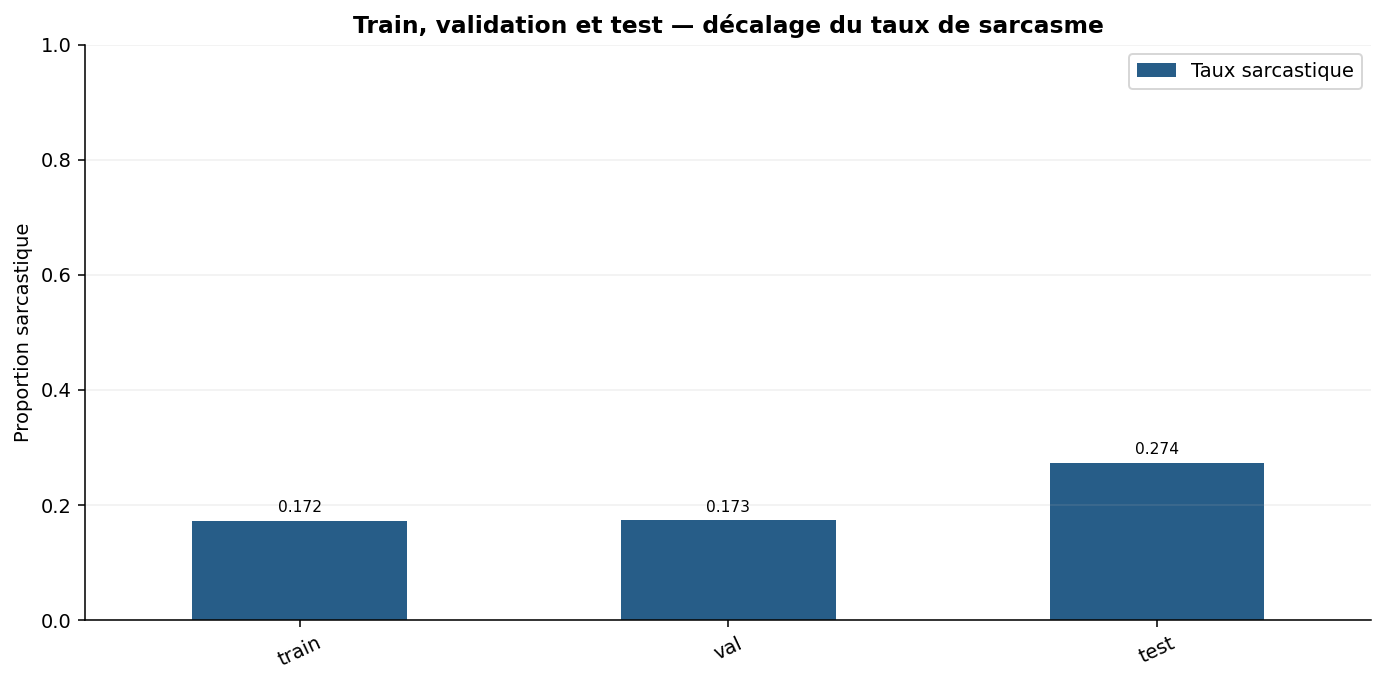

**À présenter :** Le taux passe de 17,29 % en validation à 27,37 % sur test. Ce changement aide à comprendre le décalage des seuils optimaux.

In [ ]:
_TP2_TABLE_TITLES = ['Décalage du taux de sarcasme', 'Dialectes dans train, validation et test', 'Sentiment et sarcasme dans les trois partitions', 'Raccourcis dans le train', 'Raccourcis dans le test', 'Effectifs maghrébins', 'OOV sur le test']

test=pd.read_csv(DATA_DIR/'testing_data.csv')

test['id']=np.arange(len(test))

test['y']=test.sarcasm.astype(int)

test['key']=test.tweet.map(duplicate_key)

assert len(test)==3000 and set(train.key).isdisjoint(test.key)

display(pd.DataFrame({n:{'n':len(f),'sarcastiques':int(f.y.sum()),'taux':f.y.mean()} for n,f in [('train',train),('val',val),('test',test)]}).T)

for column in ['dialect','sentiment']:
    display(pd.concat({n:f.groupby(column).y.agg(['size','sum','mean']) for n,f in [('train',train),('val',val),('test',test)]}))

for name,frame in [('train',train),('test',test)]:
    flags=text_features(frame.tweet)
    display(pd.DataFrame([{'split':name,'indice':c,'presence':present,'n':int(flags[c].eq(present).sum()),
        'taux_sarcasme':frame.y[flags[c].eq(present)].mean()} for c in ['url','mention','artefact_guillemets'] for present in [False,True]]))

combined=pd.concat([full.assign(split='train_officiel'),test.assign(split='test')],ignore_index=True)

combined['key']=combined.tweet.map(duplicate_key)

all_contradictions=set(combined.groupby('key').y.nunique().loc[lambda s:s>1].index)

combined.loc[combined.key.isin(all_contradictions)].to_csv(ROOT/'results/contradictions_all_post_test.csv',index=False,encoding='utf-8-sig')

display(pd.DataFrame({'split':['train','test'],'magreb':[int(train.dialect.eq('magreb').sum()),int(test.dialect.eq('magreb').sum())]}))

display(pd.DataFrame({n:token_stats(f.tweet) for n,f in [('train',train),('val',val),('test',test)]}).T)

FX,MX=frozen_features(test.tweet.tolist(),'test')

def load_registered(rec):
    cfg=rec['config']; kind=rec['kind']
    if kind in ['tfidf','frozen_lr']: return joblib.load(ROOT/rec['path'])
    if kind=='static': model=StaticNet(cfg['arch'],position=cfg.get('position',True))
    elif kind=='frozen_head': model=FrozenHead()
    elif kind=='plm': model=FineTuneNet(cfg['model_name'],cfg['multitask'])
    else: return None
    model.load_state_dict(torch.load(ROOT/rec['path'],map_location=DEVICE,weights_only=True)); return model.to(DEVICE).eval()

def predict_registered(rec,texts,split_tag=None,model=None):
    kind=rec['kind']; cfg=rec['config']; own=model is None
    if model is None: model=load_registered(rec)
    if cfg.get('drop_links') and kind in ['static','frozen_lr','frozen_head']:
        texts=[MENTION_RE.sub(' ',URL_RE.sub(' ',s)) for s in texts]
        split_tag=None
    if kind=='tfidf':
        p=model.predict_proba([prepare_text(s,cfg['mode'],cfg['drop_links']) for s in texts])[:,1]
    elif kind=='static': p=neural_predict(model,[word_encode(texts)])
    elif kind in ['frozen_lr','frozen_head']:
        if split_tag=='test': h,m=FX,MX
        else: h,m=frozen_features(texts,split_tag or hashlib.sha256('\n'.join(texts).encode()).hexdigest()[:12])
        if kind=='frozen_lr': p=model.predict_proba(pooled_features(h,m,cfg['pooling']))[:,1]
        else: p=neural_predict(model,[torch.tensor(np.asarray(h)),torch.tensor(m)])
    elif kind=='plm': p=neural_predict(model,plm_encode(texts,cfg['model_name'],cfg.get('drop_links',False)),batch=BATCH)
    elif kind=='nli': p=cached_nli(texts,cfg['language'],split_tag or 'custom')[0]
    elif kind=='sentiment': p=sentiment_predict(texts,split_tag or 'custom')[1].astype(float)
    else: raise ValueError(kind)
    if own: del model; gc.collect()
    return p

# Graphique complémentaire : valeurs de la session courante.
_tp2_plot(pd.DataFrame({'Taux sarcastique':[train.y.mean(),val.y.mean(),test.y.mean()]},index=['train','val','test']), 'Train, validation et test — décalage du taux de sarcasme', 'Proportion sarcastique', 'presentation_08', unit_interval=True)

### Présenter les résultats — étape 30

**Support 1 — Décalage du taux de sarcasme**

> « Le sarcasme représente 17,29 % de la validation contre 27,37 % du test, soit environ 10,08 points de plus. Le test est donc différent de la validation ; un seuil réglé sur validation peut y être moins adapté. »

**Support 2 — Dialectes dans train, validation et test**

> « Le test contient 306 tweets égyptiens, mais seulement deux tweets maghrébins. Les performances par dialecte doivent être lues avec leurs effectifs ; ce corpus ne permet pas de valider sérieusement un déploiement sur des tweets marocains. »

**Support 3 — Sentiment et sarcasme dans les trois partitions**

> « Le sarcasme reste fréquent parmi les tweets négatifs du test, environ 42,28 %. Cependant, le taux des tweets neutres augmente à 14,17 %. La relation sentiment–sarcasme n’est donc pas parfaitement stable entre partitions. »

**Support 4 — Raccourcis dans le train**

> « Je rappelle ici les corrélations observées pendant l’apprentissage. Par exemple, les tweets avec URL sont moins souvent sarcastiques. Ce tableau sert de référence pour comprendre les écarts avec le test. »

**Support 5 — Raccourcis dans le test**

> « Dans le test, 3,64 % des tweets avec URL sont sarcastiques contre 31,45 % sans URL. Les mentions et les guillemets concernent très peu de tweets ; leurs taux doivent être interprétés avec prudence. »

**Support 6 — Effectifs maghrébins**

> « Je dispose de 35 tweets maghrébins dans le train et de deux dans le test. Je ne peux pas transformer ces effectifs en preuve de qualité sur l’arabe marocain ; un jeu de test adapté est nécessaire. »

**Support 7 — OOV sur le test**

> « Le taux de tokens inconnus passe de 21,16 % en validation à 27,71 % sur test. Le modèle statique rencontre donc davantage de mots qu’il ne sait pas représenter précisément, ce qui constitue un défi de généralisation. »

**3. Résultat — Visualisation**

Les sorties enregistrées ci-dessus proviennent de l’exécution originale : tableaux, métriques, graphiques ou journaux selon cette étape.

**4. Mon interprétation**

Les contrôles de partitions doivent être satisfaits avant d’interpréter les scores test.

### Scores test et diagnostic des seuils

**1. Explication**

**Objectif :** Calculer les scores test avec les seuils choisis sur validation.

**Pourquoi cette méthode ?** Le diagnostic des seuils aide à comprendre les erreurs de calibration.

**2. Code — Implémentation**

La cellule suivante réalise cette étape.

A_tfidf_conservateur_seed42 F1 test 0.5369
A_tfidf_conservateur_seed43 F1 test 0.5369
A_tfidf_conservateur_seed44 F1 test 0.5369
C3_AraVec_seed42 F1 test 0.5448
C3_AraVec_seed43 F1 test 0.5446
C3_AraVec_seed44 F1 test 0.5312
D2_BiLSTM_attention_seed42 F1 test 0.5962
D2_BiLSTM_attention_seed43 F1 test 0.6037
D2_BiLSTM_attention_seed44 F1 test 0.5799


Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


E1_AraBERT_mono_seed42 F1 test 0.6248


Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


E1_AraBERT_mono_seed43 F1 test 0.5839


...

Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


E2_AraBERT_lambda0p3_seed44 F1 test 0.6065
NLI labels : {0: 'entailment', 1: 'neutral', 2: 'contradiction'}
B1 en test 640 / 3000
B1 en test 1280 / 3000
B1 en test 1920 / 3000
B1 en test 2560 / 3000
B1_NLI_en_seed42 F1 test 0.4625
CAMeLBERT labels : {0: 'positive', 1: 'negative', 2: 'neutral'}
B2_negatif_sarcastique_seed42 F1 test 0.532


#### Scores test par modèle et par graine

,model,seed,threshold,test_f1_sarcastique,test_macro_f1,test_pr_auc_ap
0,A_tfidf_conservateur,42,0.516072,0.536913,0.670166,0.534885
1,A_tfidf_conservateur,43,0.516072,0.536913,0.670166,0.534885
2,A_tfidf_conservateur,44,0.516072,0.536913,0.670166,0.534885
3,C3_AraVec,42,0.615209,0.544760,0.672332,0.542786
4,C3_AraVec,43,0.681563,0.544638,0.676206,0.541817
5,C3_AraVec,44,0.676775,0.531210,0.682535,0.554771
6,D2_BiLSTM_attention,42,0.698322,0.596187,0.716224,0.629332
7,D2_BiLSTM_attention,43,0.733876,0.603708,0.721835,0.625056
8,D2_BiLSTM_attention,44,0.810747,0.579949,0.715155,0.621716
9,E1_AraBERT_mono,42,0.520801,0.624795,0.730004,0.631473


#### Courbes du seuil et précision–rappel

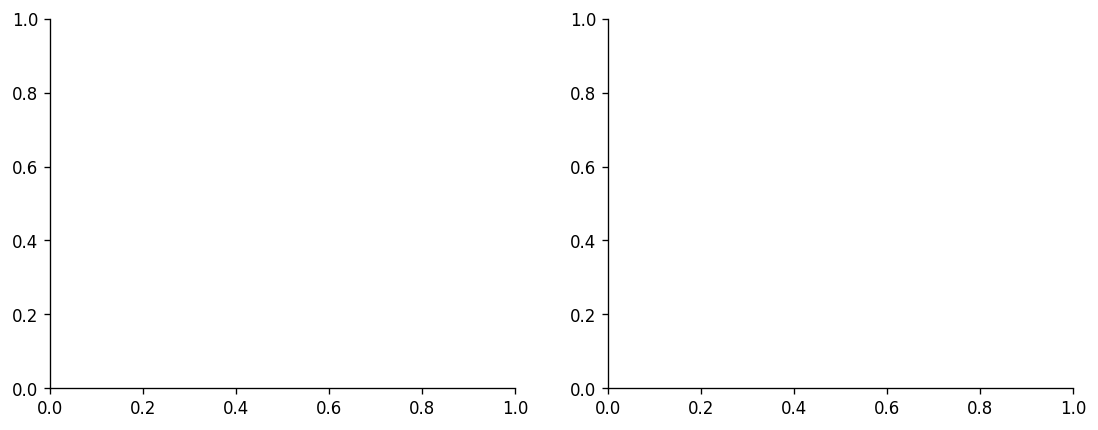

#### Seuil validation et optimum test a posteriori

,famille,seuil_val,seuil_test_posthoc,f1_test_seuil_val,f1_test_posthoc
0,A,0.516072,0.458968,0.536913,0.551142
1,C,0.615209,0.570243,0.544760,0.552323
2,D,0.698322,0.572322,0.596187,0.633741
3,E1,0.520801,0.224268,0.624795,0.638743
4,E2,0.490785,0.298287,0.623932,0.638007


In [ ]:
_TP2_TABLE_TITLES = ['Scores test par modèle et par graine', 'Seuil validation et optimum test a posteriori']

TEST_P={}

TEST_ROWS=[]

for key in FINAL_KEYS:
    rec=REGISTRY[key]; path=ROOT/f'predictions/{key}.csv'
    start=time.perf_counter(); p=predict_registered(rec,test.tweet.tolist(),'test'); elapsed=time.perf_counter()-start
    TEST_P[key]=p; pred=(p>=rec['threshold']).astype(int)
    export_p=sentiment_predict(test.tweet.tolist(),'test')[0] if rec['kind']=='sentiment' else p
    pd.DataFrame({'id':test.id,'y_true':test.y,'y_pred':pred,'probability':np.asarray(export_p,dtype=np.float64)}).to_csv(path,index=False)
    row=row_for_key(key); row.update({'test_'+k:v for k,v in scores(test.y,p,rec['threshold']).items()})
    # AP B2 doit utiliser la probabilité de sentiment, pas seulement la décision binaire.
    if rec['kind']=='sentiment': row['test_pr_auc_ap']=float(average_precision_score(test.y,sentiment_predict(test.tweet.tolist(),'test')[0]))
    row['test_inference_total_seconds']=elapsed; row['test_pipeline_ms_per_tweet']=1000*elapsed/len(test)
    row['artifact_size_mb']=(ROOT/rec['path']).stat().st_size/1e6 if (ROOT/rec['path']).is_file() else sum(f.stat().st_size for f in (ROOT/rec['path']).glob('*') if f.is_file())/1e6
    TEST_ROWS.append(row.copy()); pd.DataFrame(RESULTS).to_csv(ROOT/'results/results.csv',index=False)
    print(key,'F1 test',round(row['test_f1_sarcastique'],4),flush=True)

summary=pd.DataFrame(TEST_ROWS)

display(summary[['model','seed','threshold','test_f1_sarcastique','test_macro_f1','test_pr_auc_ap']])

fig,axes=plt.subplots(1,2,figsize=(11,4))

threshold_rows=[]

for family,keys in FINAL_GROUPS.items():
    key=keys[0]; p=TEST_P[key]; t=REGISTRY[key]['threshold']; grid=np.linspace(0,1,201)
    f=[f1_score(test.y,p>=g,zero_division=0) for g in grid]
    axes[0].plot(grid,f,label=family); axes[0].scatter([t],[f1_score(test.y,p>=t)],s=20)
    prec,rec,_=precision_recall_curve(test.y,p); axes[1].plot(rec,prec,label=family)
    post=best_threshold(test.y,p)
    threshold_rows.append({'famille':family,'seuil_val':t,'seuil_test_posthoc':post,
        'f1_test_seuil_val':scores(test.y,p,t)['f1_sarcastique'],'f1_test_posthoc':scores(test.y,p,post)['f1_sarcastique']})

axes[0].set(title='Test diagnostic a posteriori uniquement',xlabel='Seuil',ylabel='F1 sarcastique')

axes[0].legend()

axes[1].set(title='Courbes précision rappel test',xlabel='Rappel',ylabel='Précision')

axes[1].legend()

savefig(fig,'threshold_and_pr_test')

pd.DataFrame(threshold_rows).to_csv(ROOT/'results/threshold_shift.csv',index=False)

display(pd.DataFrame(threshold_rows))

### Présenter les résultats — étape 31

**Support 1 — Scores test par modèle et par graine**

> « Ce tableau donne les performances sur le test officiel aux seuils déjà fixés. Il distingue les runs individuels : par exemple E1 graine 42 atteint 0,6248 et E2 graine 42 atteint 0,6239. Le classement global doit ensuite être examiné sur les trois graines. »

**Support 2 — Courbes du seuil et précision–rappel**

> « À gauche, l’axe horizontal est le seuil et l’axe vertical le F1 test ; les points repèrent les seuils choisis sur validation. À droite, les courbes montrent le compromis entre précision et rappel. Les courbes test servent au diagnostic après évaluation, pas à sélectionner un nouveau modèle. »

**Support 3 — Seuil validation et optimum test a posteriori**

> « Pour E2, le seuil validation est 0,4908 et le seuil optimal a posteriori sur test 0,2983. Le F1 passerait de 0,6239 à 0,6380, mais ce dernier chiffre exploite les labels test. Je conserve donc 0,6239 comme résultat officiel de ce run. »

**3. Résultat — Visualisation**

Les sorties enregistrées ci-dessus proviennent de l’exécution originale : tableaux, métriques, graphiques ou journaux selon cette étape.

**4. Mon interprétation**

Les seuils optimisés a posteriori sur test sont uniquement diagnostiques : ils ne remplacent pas les scores officiels aux seuils validation.

### Dialectes et indices de surface

**1. Explication**

**Objectif :** Évaluer par dialecte et après retrait d’indices.

**Pourquoi cette méthode ?** Un score global peut masquer une faiblesse sur un sous-groupe.

**2. Code — Implémentation**

La cellule suivante réalise cette étape.

Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it

#### Scores par dialecte et présence d’URL

,famille,URL,n,positifs,f1_sarcastique,precision,recall,macro_f1,pr_auc_ap,dialecte
0,A,False,2560,805,0.543700,0.500522,0.595031,0.652136,0.542740,NaN
1,A,True,440,16,0.076923,0.100000,0.062500,0.524410,0.089224,NaN
2,A,NaN,306,155,0.683473,0.603960,0.787097,0.620168,0.727252,egypt
3,A,NaN,322,57,0.393939,0.346667,0.456140,0.618845,0.397931,gulf
4,A,NaN,47,14,0.588235,0.500000,0.714286,0.677451,0.465987,levant
5,A,NaN,2,0,0.000000,0.000000,0.000000,1.000000,NaN,magreb
6,A,NaN,2323,595,0.509091,0.480597,0.541176,0.662709,0.489608,msa
7,C,False,2560,805,0.559140,0.513514,0.613665,0.663405,0.560018,NaN
8,C,True,440,16,0.153846,0.102041,0.312500,0.543181,0.167797,NaN
9,C,NaN,306,155,0.698163,0.588496,0.858065,0.600164,0.708153,egypt


#### Retrait des indices du sarcasme

,famille,n_initialement_detectes,taux_detection_avant,taux_detection_apres,chute
0,A,480,1.0,0.906250,0.093750
1,C,499,1.0,0.947896,0.052104
2,D,516,1.0,0.934109,0.065891
3,E1,572,1.0,0.942308,0.057692
4,E2,584,1.0,0.953767,0.046233


#### Indices supprimés — baisse de détection sur les vrais positifs

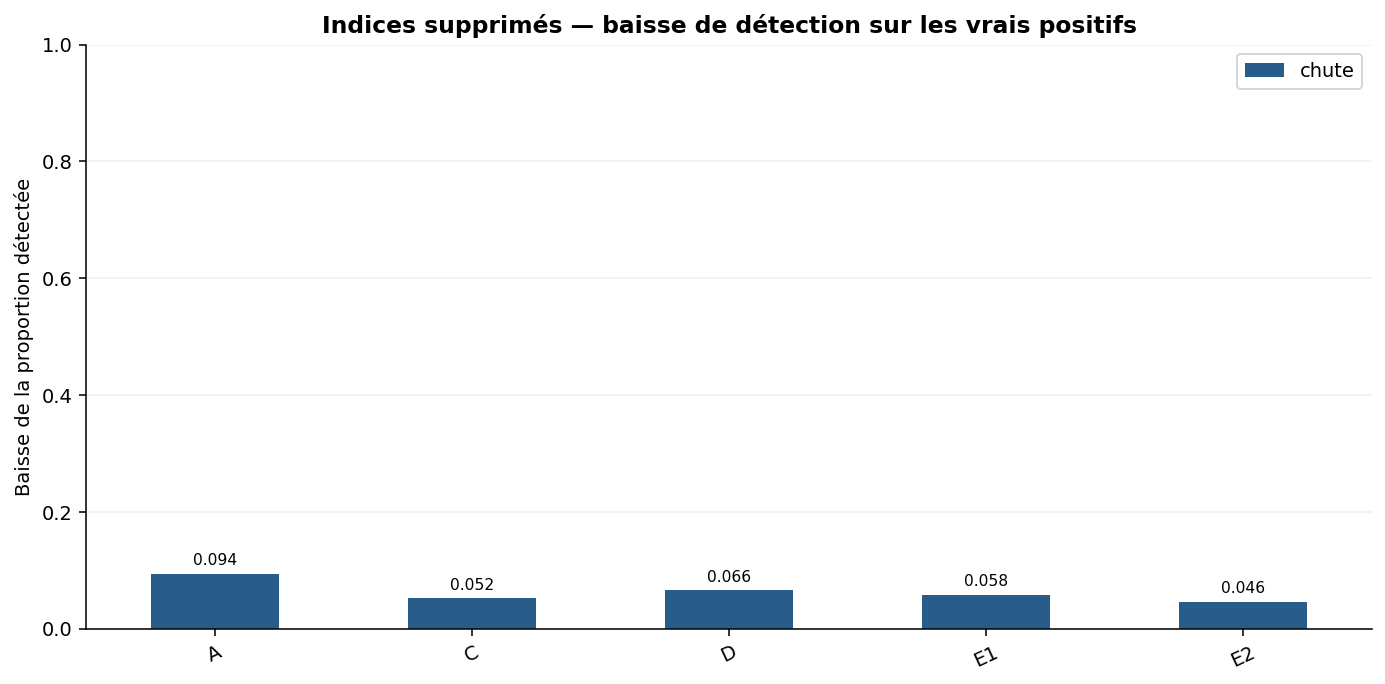

**À présenter :** Les barres mesurent une baisse de détection sur un ensemble fixé de sarcasmes bien détectés, pas une baisse de F1 global.

In [ ]:
_TP2_TABLE_TITLES = ['Scores par dialecte et présence d’URL', 'Retrait des indices du sarcasme']

subgroups=[]

cue_rows=[]

url_flags=text_features(test.tweet).url.to_numpy()

for family,keys in FINAL_GROUPS.items():
    key=keys[0]; rec=REGISTRY[key]; p=TEST_P[key]; t=rec['threshold']
    for group in [False,True]:
        mask=url_flags==group
        subgroups.append({'famille':family,'URL':group,'n':int(mask.sum()),'positifs':int(test.y[mask].sum()),**scores(test.y[mask],p[mask],t)})
    for dialect in sorted(test.dialect.unique()):
        mask=test.dialect.eq(dialect).to_numpy()
        subgroups.append({'famille':family,'dialecte':dialect,'n':int(mask.sum()),'positifs':int(test.y[mask].sum()),**scores(test.y[mask],p[mask],t)})
    mask=(test.y.to_numpy()==1)&(p>=t); texts=[erase_cues(s) for s in test.tweet[mask]]
    if texts:
        modified=predict_registered(rec,texts,f'cues_{family}')
        after=float(np.mean(modified>=t))
        cue_rows.append({'famille':family,'n_initialement_detectes':int(mask.sum()),'taux_detection_avant':1.,'taux_detection_apres':after,'chute':1-after})

pd.DataFrame(subgroups).to_csv(ROOT/'results/subgroups.csv',index=False)

pd.DataFrame(cue_rows).to_csv(ROOT/'results/cues_ablation.csv',index=False)

display(pd.DataFrame(subgroups))

display(pd.DataFrame(cue_rows))

# Graphique complémentaire : valeurs de la session courante.
_tp2_plot(pd.DataFrame(cue_rows).set_index('famille')[['chute']], 'Indices supprimés — baisse de détection sur les vrais positifs', 'Baisse de la proportion détectée', 'presentation_09', unit_interval=True)

### Présenter les résultats — étape 32

**Support 1 — Scores par dialecte et présence d’URL**

> « La baseline atteint un F1 de 0,5437 sans URL contre 0,0769 avec URL. Le second groupe ne contient que 16 tweets sarcastiques : il est difficile et son score est instable. Les lignes par dialecte et par URL sont des découpages différents ; elles ne doivent pas être additionnées. »

**Support 2 — Retrait des indices du sarcasme**

> « Je ne garde ici que les tweets sarcastiques initialement bien détectés. Après suppression des emojis, rires et ponctuations répétées, la détection baisse de 9,38 points pour A et de 4,62 points pour E2. Les modèles utilisent ces indices ; il ne s’agit pas d’une baisse du F1 global. »

**3. Résultat — Visualisation**

Les sorties enregistrées ci-dessus proviennent de l’exécution originale : tableaux, métriques, graphiques ou journaux selon cette étape.

**4. Mon interprétation**

Le retrait d’indices fait baisser la détection ; les modèles en dépendent partiellement. Les très petits sous-groupes ne permettent pas une conclusion solide.

### Ablations et réentraînements

**1. Explication**

**Objectif :** Réentraîner après retrait des liens ou du dialecte égyptien.

**Pourquoi cette méthode ?** Les ablations testent la dépendance à certaines informations du train.

**2. Code — Implémentation**

La cellule suivante réalise cette étape.

F_A_sans_url_mention_seed42 F1 val = 0.5045 seuil = 0.5117 temps = 5.4 s
F_C_sans_url_mention 42 époque 1 perte 0.5777 F1 val 0.5291
F_C_sans_url_mention 42 époque 2 perte 0.5258 F1 val 0.5125
F_C_sans_url_mention 42 époque 3 perte 0.5198 F1 val 0.5265
F_C_sans_url_mention_seed42 F1 val = 0.5291 seuil = 0.6468 temps = 6.9 s


Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Extraction AraBERT train_without_links 1600 / 10842
Extraction AraBERT train_without_links 3200 / 10842
Extraction AraBERT train_without_links 4800 / 10842
Extraction AraBERT train_without_links 6400 / 10842
Extraction AraBERT train_without_links 8000 / 10842
Extraction AraBERT train_without_links 9600 / 10842
Extraction AraBERT test_without_links 1600 / 3000
F_D_sans_url_mention 42 époque 1 perte 0.4475 F1 val 0.6544
F_D_sans_url_mention 42 époque 2 perte 0.3458 F1 val 0.6437
F_D_sans_url_mention 42 époque 3 perte 0.2693 F1 val 0.6421
F_D_sans_url_mention_seed42 F1 val = 0.6544 seuil = 0.665 temps = 12.2 s


Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


F_sans_egypt 42 époque 1 batch 50 / 267 perte 0.9706
F_sans_egypt 42 époque 1 batch 100 / 267 perte 0.9247
F_sans_egypt 42 époque 1 batch 150 / 267 perte 0.8311
F_sans_egypt 42 époque 1 batch 200 / 267 perte 0.7916
F_sans_egypt 42 époque 1 batch 250 / 267 perte 0.7493
F_sans_egypt 42 époque 1 perte 0.7419 F1 val 0.6357
F_sans_egypt 42 époque 2 batch 50 / 267 perte 0.5086
F_sans_egypt 42 époque 2 batch 100 / 267 perte 0.4892
F_sans_egypt 42 époque 2 batch 150 / 267 perte 0.4967
F_sans_egypt 42 époque 2 batch 200 / 267 perte 0.4958
F_sans_egypt 42 époque 2 batch 250 / 267 perte 0.4972
F_sans_egypt 42 époque 2 perte 0.4904 F1 val 0.6258
F_sans_egypt 42 époque 3 batch 50 / 267 perte 0.3802
F_sans_egypt 42 époque 3 batch 100 / 267 perte 0.3865
F_sans_egypt 42 époque 3 batch 150 / 267 perte 0.386
F_sans_egypt 42 époque 3 batch 200 / 267 perte 0.3791
F_sans_egypt 42 époque 3 batch 250 / 267 perte 0.375
F_sans_egypt 42 époque 3 perte 0.3721 F1 val 0.6361
F_sans_egypt_seed42 F1 val = 0.6761 seu

...

Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


F_E2_sans_url_mention 42 époque 1 batch 50 / 339 perte 0.9946
F_E2_sans_url_mention 42 époque 1 batch 100 / 339 perte 0.9286
F_E2_sans_url_mention 42 époque 1 batch 150 / 339 perte 0.8481
F_E2_sans_url_mention 42 époque 1 batch 200 / 339 perte 0.7941
F_E2_sans_url_mention 42 époque 1 batch 250 / 339 perte 0.7523
F_E2_sans_url_mention 42 époque 1 batch 300 / 339 perte 0.7317
F_E2_sans_url_mention 42 époque 1 perte 0.7155 F1 val 0.675
F_E2_sans_url_mention 42 époque 2 batch 50 / 339 perte 0.4649
F_E2_sans_url_mention 42 époque 2 batch 100 / 339 perte 0.4794
F_E2_sans_url_mention 42 époque 2 batch 150 / 339 perte 0.4872
F_E2_sans_url_mention 42 époque 2 batch 200 / 339 perte 0.4892
F_E2_sans_url_mention 42 époque 2 batch 250 / 339 perte 0.4827
F_E2_sans_url_mention 42 époque 2 batch 300 / 339 perte 0.4803
F_E2_sans_url_mention 42 époque 2 perte 0.4771 F1 val 0.6612
F_E2_sans_url_mention 42 époque 3 batch 50 / 339 perte 0.3538
F_E2_sans_url_mention 42 époque 3 batch 100 / 339 perte 0.364
F

#### Ablations par réentraînement

,diagnostic,n_train,n_test,threshold,f1_sarcastique,precision,recall,macro_f1,pr_auc_ap,f1_reference
0,A_sans_url_mention,10842,3000,0.511684,0.507514,0.482948,0.534714,0.653991,0.521348,0.536913
1,C_sans_url_mention,10842,3000,0.646785,0.543025,0.483810,0.618758,0.667977,0.538624,0.544760
2,D_sans_url_mention,10842,3000,0.665025,0.590565,0.565848,0.617540,0.713214,0.623948,0.596187
3,sans_egypt,8522,306,0.611266,0.767372,0.721591,0.819355,0.746675,0.810154,0.773639
4,E1_sans_url_mention,10842,3000,0.708490,0.602740,0.589744,0.616322,0.724189,0.641555,0.624795
5,E2_sans_url_mention,10842,3000,0.662346,0.619943,0.582441,0.662607,0.731408,0.643582,0.623932


#### Ablations — référence contre modèle réentraîné

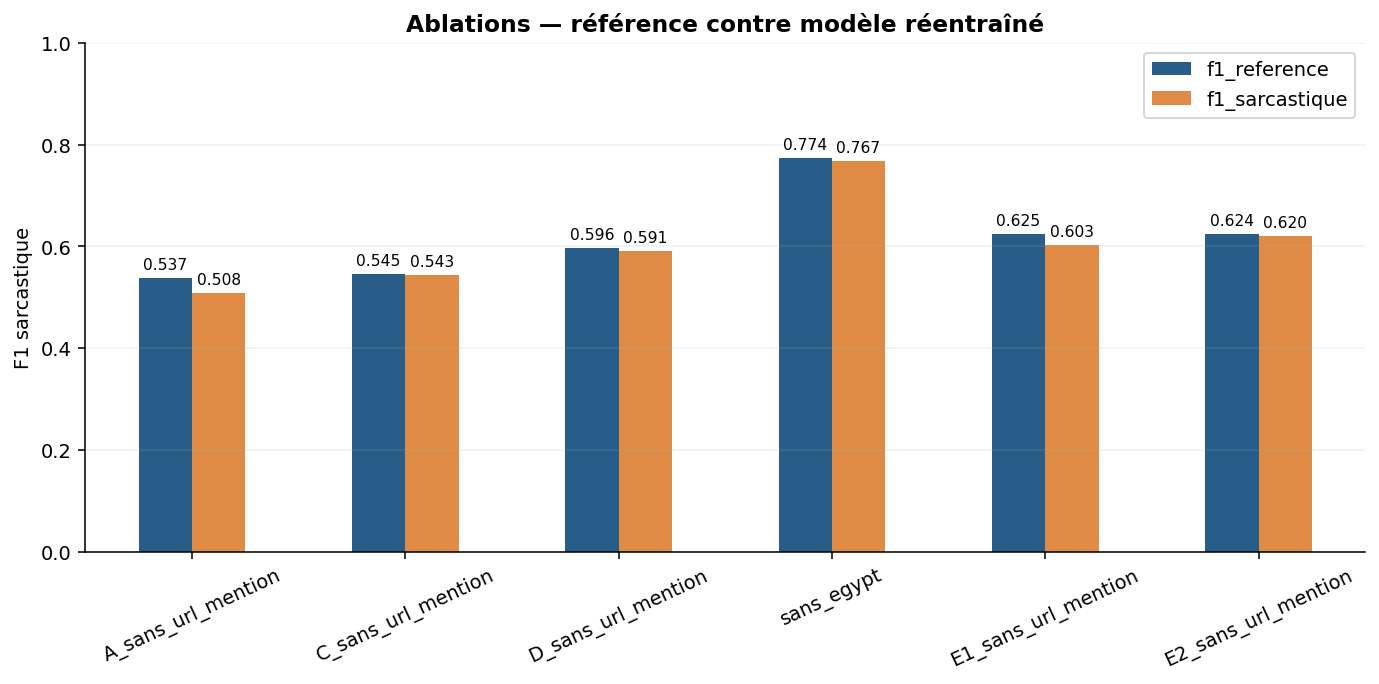

**À présenter :** Chaque paire compare le même sous-ensemble test. La ligne sans égyptien porte seulement sur 306 tweets égyptiens ; elle ne doit pas être comparée directement aux autres lignes calculées sur tout le test.

In [ ]:
_TP2_TABLE_TITLES = ['Ablations par réentraînement']

best_e_family=max(['E1','E2'],key=lambda f:np.mean([row_for_key(k)['val_f1_sarcastique'] for k in FINAL_GROUPS[f]]))

best_e_key=FINAL_GROUPS[best_e_family][0]

erec=REGISTRY[best_e_key]

ecfg=erec['config'].copy()

ename=ecfg['model_name']

robust_rows=[]

for family in ['A','C','D']:
    reference_key=FINAL_GROUPS[family][0]; reference=REGISTRY[reference_key]; cfg=reference['config'].copy()
    seed_all(42); name=f'F_{family}_sans_url_mention'
    if family=='A':
        key=run_tfidf(name,cfg['mode'],cfg['imbalance'],42,True)
        p=predict_registered(REGISTRY[key],test.tweet.tolist(),'test')
    elif family=='C':
        xt=[word_encode([prepare_text(s,drop_links=True) for s in train.tweet])]
        xv=[word_encode([prepare_text(s,drop_links=True) for s in val.tweet])]
        emb=ARAVEC if cfg['embedding']=='aravec' else None
        cfg['drop_links']=True
        key,model=train_neural(StaticNet(cfg['arch'],emb,position=cfg.get('position',True),freeze=emb is not None),xt,xv,name,
            config=cfg,imbalance=cfg.get('imbalance','weighted'),freeze_epochs=cfg.get('freeze_epochs',0))
        p=neural_predict(model,[word_encode([prepare_text(s,drop_links=True) for s in test.tweet])]); del model; gc.collect()
    else:
        # Extraction sans URL/mention ; mêmes poids gelés, nouvelle tête entraînée sur train seulement.
        ht,mt=frozen_features([MENTION_RE.sub(' ',URL_RE.sub(' ',s)) for s in train.tweet],'train_without_links')
        hv,mv=frozen_features([MENTION_RE.sub(' ',URL_RE.sub(' ',s)) for s in val.tweet],'val_without_links')
        hx,mx=frozen_features([MENTION_RE.sub(' ',URL_RE.sub(' ',s)) for s in test.tweet],'test_without_links')
        if reference['kind']=='frozen_lr':
            pooling=cfg['pooling']; model=LogisticRegression(C=1,class_weight='balanced',max_iter=1500,random_state=42)
            start=time.perf_counter(); model.fit(pooled_features(ht,mt,pooling),train.y); seconds=time.perf_counter()-start
            path=ROOT/f'models/{name}_seed42.joblib'; joblib.dump(model,path)
            key=register(name,42,model.predict_proba(pooled_features(hv,mv,pooling))[:,1],seconds,model.coef_.size+1,
                'arabert_official_without_links','frozen_lr',path,dict(cfg,drop_links=True))
            p=model.predict_proba(pooled_features(hx,mx,pooling))[:,1]
        else:
            key,model=train_neural(FrozenHead(),[torch.tensor(np.asarray(ht)),torch.tensor(mt)],
                [torch.tensor(np.asarray(hv)),torch.tensor(mv)],name,config=dict(cfg,drop_links=True))
            p=neural_predict(model,[torch.tensor(np.asarray(hx)),torch.tensor(mx)]); del model; gc.collect()
    threshold=REGISTRY[key]['threshold']; rr={'diagnostic':f'{family}_sans_url_mention','n_train':len(train),'n_test':len(test),
        'threshold':threshold,**scores(test.y,p,threshold),'f1_reference':scores(test.y,TEST_P[reference_key],reference['threshold'])['f1_sarcastique']}
    robust_rows.append(rr); row_for_key(key).update({'test_'+k:v for k,v in scores(test.y,p,threshold).items()})
    pd.DataFrame({'id':test.id,'y_true':test.y,'y_pred':(p>=threshold).astype(int),'probability':np.asarray(p,dtype=np.float64)}).to_csv(ROOT/f'predictions/{key}.csv',index=False)

for diagnostic in ['sans_egypt','E1_sans_url_mention','E2_sans_url_mention']:
    reference_e=erec if diagnostic=='sans_egypt' else REGISTRY[FINAL_GROUPS[diagnostic[:2]][0]]
    ecfg=reference_e['config'].copy(); ename=ecfg['model_name']
    subset=train.loc[~train.dialect.eq('egypt')] if diagnostic=='sans_egypt' else train
    drop=diagnostic!='sans_egypt'; cfg=dict(ecfg,train_ids=subset.id.tolist(),drop_links=drop)
    xt=plm_encode(subset.tweet.tolist(),ename,drop); xv=plm_encode(val.tweet.tolist(),ename,drop)
    seed_all(42)
    key,model=train_neural(FineTuneNet(ename,ecfg['multitask']),xt,xv,f'F_{diagnostic}',config=cfg,
        epochs=PLM_EPOCHS,lr=2e-5,lam=ecfg['lam'],plm=True,
        labels=torch.tensor(subset.y.to_numpy(),dtype=torch.long),sentiments=torch.tensor(subset.sentiment.map(SENT_MAP).to_numpy(),dtype=torch.long),
        val_mask=(~val.dialect.eq('egypt').to_numpy()) if diagnostic=='sans_egypt' else None)
    pv=neural_predict(model,xv,batch=BATCH)
    vm=~val.dialect.eq('egypt').to_numpy() if diagnostic=='sans_egypt' else np.ones(len(val),dtype=bool)
    threshold=best_threshold(val.y[vm],pv[vm])
    REGISTRY[key]['threshold']=threshold
    row_for_key(key).update({'val_'+k:v for k,v in scores(val.y,pv,threshold).items()})
    pp=neural_predict(model,plm_encode(test.tweet.tolist(),ename,drop),batch=BATCH)
    tm=test.dialect.eq('egypt').to_numpy() if diagnostic=='sans_egypt' else np.ones(len(test),dtype=bool)
    rr={'diagnostic':diagnostic,'n_train':len(subset),'n_test':int(tm.sum()),'threshold':threshold,
        **scores(test.y[tm],pp[tm],threshold),
        'f1_reference':scores(test.y[tm],TEST_P[reference_e['key']][tm],reference_e['threshold'])['f1_sarcastique']}
    robust_rows.append(rr)
    row_for_key(key).update({'test_'+k:v for k,v in scores(test.y[tm],pp[tm],threshold).items()})
    row_for_key(key).update({'threshold':threshold,'test_subset':'egypt' if diagnostic=='sans_egypt' else 'all','n_test_evaluated':int(tm.sum())})
    pd.DataFrame({'id':test.id,'y_true':test.y,'y_pred':(pp>=threshold).astype(int),'probability':np.asarray(pp,dtype=np.float64)}).to_csv(ROOT/f'predictions/{key}.csv',index=False)
    del model,xt,xv; gc.collect()

pd.DataFrame(robust_rows).to_csv(ROOT/'results/retraining_robustness.csv',index=False)

display(pd.DataFrame(robust_rows))

# Graphique complémentaire : valeurs de la session courante.
_tp2_plot(pd.DataFrame(robust_rows).set_index('diagnostic')[['f1_reference','f1_sarcastique']], 'Ablations — référence contre modèle réentraîné', 'F1 sarcastique', 'presentation_10', unit_interval=True)

### Présenter les résultats — étape 33

**Support 1 — Ablations par réentraînement**

> « Sans URL ni mentions, E1 passe de 0,6248 à 0,6027 sur test et E2 de 0,6239 à 0,6199 pour les runs comparés. Sans tweets égyptiens dans le train, le meilleur E atteint 0,7674 sur le test égyptien contre 0,7736 avec tout le train : la baisse est faible dans cet essai. Cela ne signifie pas que le dialecte était absent du préentraînement. »

**Pour lire les journaux :** la perte décrit l’apprentissage, mais le checkpoint est choisi avec le F1 validation. À l’oral, je présente le score retenu et la comparaison ; je ne lis pas chaque batch. Les avertissements techniques ne sont pas des métriques.

**3. Résultat — Visualisation**

Les sorties enregistrées ci-dessus proviennent de l’exécution originale : tableaux, métriques, graphiques ou journaux selon cette étape.

**4. Mon interprétation**

Sans URL/mentions, E1 passe de 0,6248 à 0,6027 sur test pour cette comparaison. Les conclusions restent propres au protocole et au sous-ensemble évalué.

### Intervalles bootstrap

**1. Explication**

**Objectif :** Estimer l’incertitude du F1 par bootstrap.

**Pourquoi cette méthode ?** Le rééchantillonnage montre la sensibilité du score à la composition du test.

**2. Code — Implémentation**

La cellule suivante réalise cette étape.

In [ ]:
_TP2_TABLE_TITLES = ['Intervalles bootstrap à 95 %']

from scipy.stats import binomtest

rng=np.random.default_rng(42)

ytest=test.y.to_numpy()

bootstrap_rows=[]

for family,keys in FINAL_GROUPS.items():
    for key in keys:
        pred=TEST_P[key]>=REGISTRY[key]['threshold']; vals=[]
        for b in range(1000):
            idx=rng.integers(0,len(test),len(test)); yy=ytest[idx]; pp=pred[idx]
            tp=np.sum((yy==1)&pp); fp=np.sum((yy==0)&pp); fn=np.sum((yy==1)&~pp)
            vals.append(2*tp/max(2*tp+fp+fn,1))
        lo,hi=np.percentile(vals,[2.5,97.5])
        bootstrap_rows.append({'family':family,'model':key,'f1':scores(ytest,TEST_P[key],REGISTRY[key]['threshold'])['f1_sarcastique'],'ci_low':lo,'ci_high':hi,'resamples':1000})

bootstrap=pd.DataFrame(bootstrap_rows)

bootstrap.to_csv(ROOT/'results/bootstrap.csv',index=False)

display(bootstrap)

#### Intervalles bootstrap à 95 %

,family,model,f1,ci_low,ci_high,resamples
0,A,A_tfidf_conservateur_seed42,0.536913,0.509285,0.566041,1000
1,A,A_tfidf_conservateur_seed43,0.536913,0.508319,0.564501,1000
2,A,A_tfidf_conservateur_seed44,0.536913,0.507218,0.566506,1000
3,C,C3_AraVec_seed42,0.544760,0.517157,0.572941,1000
4,C,C3_AraVec_seed43,0.544638,0.518268,0.573123,1000
5,C,C3_AraVec_seed44,0.531210,0.502259,0.559646,1000
6,D,D2_BiLSTM_attention_seed42,0.596187,0.568875,0.622812,1000
7,D,D2_BiLSTM_attention_seed43,0.603708,0.576400,0.630339,1000
8,D,D2_BiLSTM_attention_seed44,0.579949,0.553144,0.611754,1000
9,E1,E1_AraBERT_mono_seed42,0.624795,0.599662,0.648740,1000


### Présenter les résultats — étape 34

**Support 1 — Intervalles bootstrap à 95 %**

> « Chaque intervalle est obtenu avec 1 000 rééchantillonnages du test. Pour E2 graine 42, le F1 est 0,6239 et l’intervalle va environ de 0,5982 à 0,6496. Cet intervalle décrit la sensibilité à l’échantillon test ; l’écart-type entre graines mesure une autre source de variation. Le simple chevauchement des intervalles ne remplace pas un test de différence. »

**3. Résultat — Visualisation**

Les sorties enregistrées ci-dessus proviennent de l’exécution originale : tableaux, métriques, graphiques ou journaux selon cette étape.

**4. Mon interprétation**

Les intervalles évitent de surinterpréter de petits écarts ; ils complètent la variabilité entre graines.

### Comparaison statistique McNemar

**1. Explication**

**Objectif :** Comparer les erreurs de deux modèles avec McNemar.

**Pourquoi cette méthode ?** Ce test utilise leurs désaccords sur les mêmes exemples.

**2. Code — Implémentation**

La cellule suivante réalise cette étape.

In [ ]:
_TP2_TABLE_TITLES = ['Test de McNemar']

family_rank=sorted(FINAL_GROUPS,key=lambda f:np.mean([row_for_key(k)['val_f1_sarcastique'] for k in FINAL_GROUPS[f]]),reverse=True)

k1,k2=[FINAL_GROUPS[f][0] for f in family_rank[:2]]

c1=(TEST_P[k1]>=REGISTRY[k1]['threshold'])==ytest

c2=(TEST_P[k2]>=REGISTRY[k2]['threshold'])==ytest

b=int(np.sum(c1&~c2))

c=int(np.sum(~c1&c2))

pvalue=binomtest(b,b+c,.5).pvalue if b+c else 1.

mcnemar={'model_1':k1,'model_2':k2,'b_correct_1_only':b,'c_correct_2_only':c,'pvalue_exact':pvalue}

(ROOT/'results/mcnemar.json').write_text(json.dumps(mcnemar,indent=2))

display(pd.Series(mcnemar).to_frame('McNemar'))

#### Test de McNemar

,McNemar
model_1,E2_AraBERT_lambda0p3_seed42
model_2,D2_BiLSTM_attention_seed42
b_correct_1_only,151
c_correct_2_only,156
pvalue_exact,0.819465


### Présenter les résultats — étape 35

**Support 1 — Test de McNemar**

> « E2 et D2 ont respectivement 151 et 156 exemples qu’ils réussissent seuls. La p-valeur vaut 0,8195 : au seuil de 5 %, ce test ne met pas en évidence de différence de leurs erreurs. Cela ne prouve pas que les deux modèles sont équivalents et ce n’est pas un test direct du F1. »

**3. Résultat — Visualisation**

Les sorties enregistrées ci-dessus proviennent de l’exécution originale : tableaux, métriques, graphiques ou journaux selon cette étape.

**4. Mon interprétation**

La p-valeur enregistrée vaut environ 0,8195 pour E2 et D2 comparés ici. Ce test ne met pas en évidence de différence significative de leurs erreurs au seuil de 5 %.

### Analyse de 30 erreurs

**1. Explication**

**Objectif :** Examiner 15 faux négatifs et 15 faux positifs.

**Pourquoi cette méthode ?** Lire les tweets aide à comprendre les limites que les métriques agrégées masquent.

**2. Code — Implémentation**

La cellule suivante réalise cette étape.

In [ ]:
_TP2_TABLE_TITLES = ['Lecture de 30 erreurs', 'Catégories provisoires d’erreurs']

chosen_final_family=family_rank[0]

CHOSEN_KEY=FINAL_GROUPS[chosen_final_family][0]

chosen_rec=REGISTRY[CHOSEN_KEY]

chosen_p=TEST_P[CHOSEN_KEY]

chosen_pred=chosen_p>=chosen_rec['threshold']

errors=[]

for kind,mask in [('FN',(ytest==1)&~chosen_pred),('FP',(ytest==0)&chosen_pred)]:
    ids=np.flatnonzero(mask)[:15]
    for i in ids:
        r=test.iloc[i]; cues=bool(re.search(r'ه{2,}|[!?؟]{2,}',r.tweet) or emoji.get_emoji_regexp().search(r.tweet))
        contradictory=r.key in all_contradictions
        category='labels contradictoires observés' if contradictory else ('marqueur mal interprété possible' if cues else ('dialecte et contexte à examiner' if r.dialect!='msa' else 'ironie sans marqueur ou contexte requis'))
        errors.append({'id':int(r.id),'type':kind,'tweet':r.tweet,'y_true':int(r.y),'probability':float(chosen_p[i]),
            'dialect':r.dialect,'sentiment':r.sentiment,'category_provisional':category,'contradictory_key':contradictory,
            'human_review':'À vérifier sur le texte et son contexte'})

errors=pd.DataFrame(errors)

errors.to_csv(ROOT/'results/errors_30.csv',index=False,encoding='utf-8-sig')

display(errors)

display(errors.groupby(['type','category_provisional']).size().rename('n').to_frame())

print('Nombre réel d’erreurs affichées :',len(errors),'— contradiction certaine dans cette sélection :',int(errors.contradictory_key.sum()))

#### Lecture de 30 erreurs

,id,type,tweet,y_true,probability,dialect,sentiment,category_provisional,contradictory_key,human_review
0,1,FN,اف مو متعوده عليهم سته https://t.co/8igFPx1i26,1,0.101634,msa,NEG,ironie sans marqueur ou contexte requis,False,À vérifier sur le texte et son contexte
1,7,FN,سقف الطموحات المستقبليه بتبقى عاليه ف وقت دراستنا كل مابتقرب من الواقع كل ماتقل ف المسافه لحد ما السقف يقع ع دماغك,1,0.024493,msa,NEG,ironie sans marqueur ou contexte requis,False,À vérifier sur le texte et son contexte
2,12,FN,إدارة #الاتحاد تطلب من الداهية الروماني بيتوركا عرض خطته وتشكيلته قبل كل مباراة ب 48 ساعة على لجنة فنية تضم مروان بصاص وحسن خليفة,1,0.008528,gulf,NEG,dialecte et contexte à examiner,False,À vérifier sur le texte et son contexte
3,42,FN,يمكن يبغون تزيد خبرتهم في شراء التذاكر للمستقبل فبيتغير مستقبل التذاكر Ye never know ~,1,0.012124,gulf,NEU,dialecte et contexte à examiner,False,À vérifier sur le texte et son contexte
4,57,FN,مصحبش فارافير 💪 https://t.co/DQFB5QIi8q,1,0.010408,msa,NEG,marqueur mal interprété possible,False,À vérifier sur le texte et son contexte
5,73,FN,مدحت شلبي : وادي حسام غالي و عبدالله السعيد فـ المدرجات .. كويس ان حسني عبدربه معترضش عليهم #الدوري_يا_اهلي #احسمها_يا_اهلي,1,0.012858,egypt,NEG,dialecte et contexte à examiner,False,À vérifier sur le texte et son contexte
6,77,FN,مراسلي القنوات الرياضية مفترض أن يكون لديهم أكثر من لغة بالإضافة للعربية وليس يس ونو وهيلو وهواريو وولكم ;-),1,0.200382,msa,NEG,ironie sans marqueur ou contexte requis,False,À vérifier sur le texte et son contexte
7,97,FN,منا كتبت و الا انت مش شايف قاتك نيله يا متنيّل بس برضو دايماً انتا بتعمل اضافة كويسة بمداخلاتك يبو نورة,1,0.301516,egypt,NEU,dialecte et contexte à examiner,False,À vérifier sur le texte et son contexte
8,109,FN,في خطبة صلاة الجمعة المعممة على المساجد غدا، الأوقاف تدعو الناخبين إلى اختيار من يسهم في الأمر بالمعروف ووصف بالعلم والقوة والأمانة! !,1,0.035544,msa,NEG,ironie sans marqueur ou contexte requis,False,À vérifier sur le texte et son contexte
9,146,FN,#بشار الأسد: نحن آخر معاقل العلمانية في المنطقة وشعارنا:الدين لله والكيماوي للجميع #سوريا,1,0.017160,msa,NEG,ironie sans marqueur ou contexte requis,False,À vérifier sur le texte et son contexte


#### Catégories provisoires d’erreurs

n
type category_provisional                       
FN   dialecte et contexte à examiner           4
     ironie sans marqueur ou contexte requis   9
     marqueur mal interprété possible          2
FP   dialecte et contexte à examiner           2
     ironie sans marqueur ou contexte requis  10
     marqueur mal interprété possible          3

Nombre réel d’erreurs affichées : 30 — contradiction certaine dans cette sélection : 0


### Présenter les résultats — étape 36

**Support 1 — Lecture de 30 erreurs**

> « Je présente 15 faux négatifs, des sarcasmes manqués, et 15 faux positifs, des tweets non sarcastiques signalés à tort. Pour chaque ligne, je compare le texte, le label et la prédiction avant de proposer une explication. »

**Support 2 — Catégories provisoires d’erreurs**

> « Les catégories automatiques regroupent 19 erreurs sous « ironie sans marqueur ou contexte requis », six autour du dialecte/contexte et cinq autour de marqueurs possiblement mal interprétés. Ce sont des hypothèses à vérifier humainement, pas des causes démontrées. Aucune contradiction certaine n’est repérée dans cette sélection ; cela ne prouve pas l’absence générale de bruit d’annotation. »

**3. Résultat — Visualisation**

Les sorties enregistrées ci-dessus proviennent de l’exécution originale : tableaux, métriques, graphiques ou journaux selon cette étape.

**4. Mon interprétation**

Les 30 erreurs affichées suggèrent un rôle du contexte et du dialecte. Les catégories sont provisoires et demandent une relecture humaine.

## G. Comparaison finale

### F1, paramètres et coût CPU

**1. Explication**

**Objectif :** Mesurer le coût et agréger les résultats par famille.

**Pourquoi cette méthode ?** Un choix pratique doit prendre en compte qualité et latence.

**2. Code — Implémentation**

La cellule suivante réalise cette étape.

In [ ]:
_TP2_TABLE_TITLES = []

DEVICE=torch.device('cpu')  # G mesure toujours la latence CPU, même après entraînement CUDA.
comparison=[]

for family,keys in FINAL_GROUPS.items():
    rows=[row_for_key(k) for k in keys]
    f=[r['test_f1_sarcastique'] for r in rows]
    key=keys[0]; rec=REGISTRY[key]
    latency=float('nan')
    if rec['kind'] in ['tfidf','static','plm']:
        model=load_registered(rec); sample=test.tweet.head(20).tolist()
        predict_registered(rec,sample[:1],model=model)
        durations=[]
        for repeat in range(3):
            start=time.perf_counter()
            for text in sample: predict_registered(rec,[text],model=model)
            durations.append((time.perf_counter()-start)*1000/len(sample))
        latency=float(np.median(durations)); del model; gc.collect()
    elif rec['kind'] in ['frozen_lr','frozen_head']:
        encoder=load_hf(ARA_NAME).eval(); head=load_registered(rec); tokenizer=tokenizer_ara
        sample=test.tweet.head(20).tolist(); durations=[]
        with torch.inference_mode():
            for repeat in range(4):
                start=time.perf_counter()
                for text in sample:
                    inp=plm_encode([text],ARA_NAME); ids,mask=[x.to(DEVICE) for x in inp]
                    length=int(mask.sum()); ids=ids[:,:length]; mask=mask[:,:length]
                    h=encoder(input_ids=ids,attention_mask=mask).last_hidden_state
                    if rec['kind']=='frozen_lr': head.predict_proba(pooled_features(h.cpu().numpy(),mask.cpu().numpy(),rec['config']['pooling']))
                    else: head(h,mask)
                if repeat: durations.append((time.perf_counter()-start)*1000/len(sample))
        latency=float(np.median(durations)); del encoder,head; gc.collect()
    size=rows[0]['artifact_size_mb']
    if rec['kind'] in ['frozen_lr','frozen_head']:
        encoder_files=list(Path(REVISIONS[ARA_NAME]['path']).glob('*.safetensors')) or list(Path(REVISIONS[ARA_NAME]['path']).glob('pytorch_model.bin'))
        size+=sum(f.stat().st_size for f in encoder_files)/1e6
    comparison.append({'family':family,'model':rec['name'],'n_seeds':len(keys),
        'val_f1_mean':np.mean([r['val_f1_sarcastique'] for r in rows]),'test_f1_mean':np.mean(f),'test_f1_std':np.std(f,ddof=1),
        'test_ap_mean':np.mean([r['test_pr_auc_ap'] for r in rows]),'train_seconds_mean':np.mean([r['train_seconds'] for r in rows]),
        'cpu_batch1_latency_ms':latency,'complete_weights_mb':size,'threshold_seed42':rec['threshold'],
        'trainable_parameters':rows[0]['trainable_parameters']})

for family,key in [('B1',best_nli_key),('B2',b2_key)]:
    rec=REGISTRY[key]; row=row_for_key(key); name=NLI_NAME if family=='B1' else SA_NAME
    model=load_hf(name,True).eval(); tok=AutoTokenizer.from_pretrained(REVISIONS[name]['path'],local_files_only=True)
    sample=test.tweet.head(20).tolist(); durations=[]
    with torch.inference_mode():
        for repeat in range(4):
            start=time.perf_counter()
            for text in sample:
                if family=='B1':
                    ids=tok(export_clean(text),truncation=True,max_length=MAX_LEN,add_special_tokens=False)['input_ids']
                    premise=tok.decode(ids,skip_special_tokens=True)
                    enc=tok([premise,premise],list(PROMPTS[rec['config']['language']]),padding=True,truncation='only_first',max_length=MAX_LEN+24,return_tensors='pt').to(DEVICE)
                    logits=model(**enc).logits
                    entail=next(i for i,label in model.config.id2label.items() if 'entail' in label.lower())
                    logits[:,entail].softmax(0)
                else:
                    enc=tok(export_clean(text),padding=True,truncation=True,max_length=MAX_LEN,return_tensors='pt').to(DEVICE)
                    model(**enc).logits.argmax(-1)
            if repeat: durations.append((time.perf_counter()-start)*1000/len(sample))
    comparison.append({'family':family,'model':rec['name'],'n_seeds':1,'val_f1_mean':row['val_f1_sarcastique'],
        'test_f1_mean':row['test_f1_sarcastique'],'test_f1_std':float('nan'),'test_ap_mean':row['test_pr_auc_ap'],
        'train_seconds_mean':0.,'cpu_batch1_latency_ms':float(np.median(durations)),
        'complete_weights_mb':row['artifact_size_mb'],'threshold_seed42':rec['threshold'],'trainable_parameters':0})
    del model; gc.collect()

Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it

### Présenter les résultats — étape 37

**Phrase de présentation**

> Je mesure ensuite la latence sur CPU avec un protocole commun. Ces journaux ne donnent pas encore la synthèse ; les valeurs comparables apparaissent dans le tableau final.

**3. Résultat — Visualisation**

Les sorties enregistrées ci-dessus proviennent de l’exécution originale : tableaux, métriques, graphiques ou journaux selon cette étape.

**4. Mon interprétation**

Les latences concernent le CPU de la session historique ; elles ne prédisent pas directement les temps sur mon ordinateur.

### Tableau final et matrice de confusion

**1. Explication**

**Objectif :** Afficher le classement final et la matrice de confusion.

**Pourquoi cette méthode ?** La moyenne et l’écart-type sur trois graines rendent la comparaison plus lisible.

**2. Code — Implémentation**

La cellule suivante réalise cette étape.

#### Qualité, coût et taille des modèles

,family,model,n_seeds,val_f1_mean,test_f1_mean,test_f1_std,test_ap_mean,train_seconds_mean,cpu_batch1_latency_ms,complete_weights_mb,threshold_seed42,trainable_parameters
0,A,A_tfidf_conservateur,3,0.5206,0.5369,0.0000,0.5349,5.7719,2.1534,5.8409,0.5161,124439
1,C,C3_AraVec,3,0.5335,0.5402,0.0078,0.5465,7.6708,2.4929,7.1405,0.6152,1773946
2,D,D2_BiLSTM_attention,3,0.6760,0.5933,0.0121,0.6254,13.8387,128.2663,542.8100,0.6983,435586
3,E1,E1_AraBERT_mono,3,0.6743,0.6093,0.0221,0.6437,143.2107,117.8176,540.8659,0.5208,134604290
4,E2,E2_AraBERT_lambda0p3,3,0.6824,0.6096,0.0131,0.6452,142.8676,116.6297,540.8769,0.4908,134606597
5,B1,B1_NLI_en,1,0.4224,0.4625,NaN,0.4077,0.0000,407.5777,578.2752,0.8249,0
6,B2,B2_negatif_sarcastique,1,0.4695,0.5320,NaN,0.4928,0.0000,123.4833,436.6950,0.5000,0


#### Courbes d’apprentissage C, D, E1 et E2

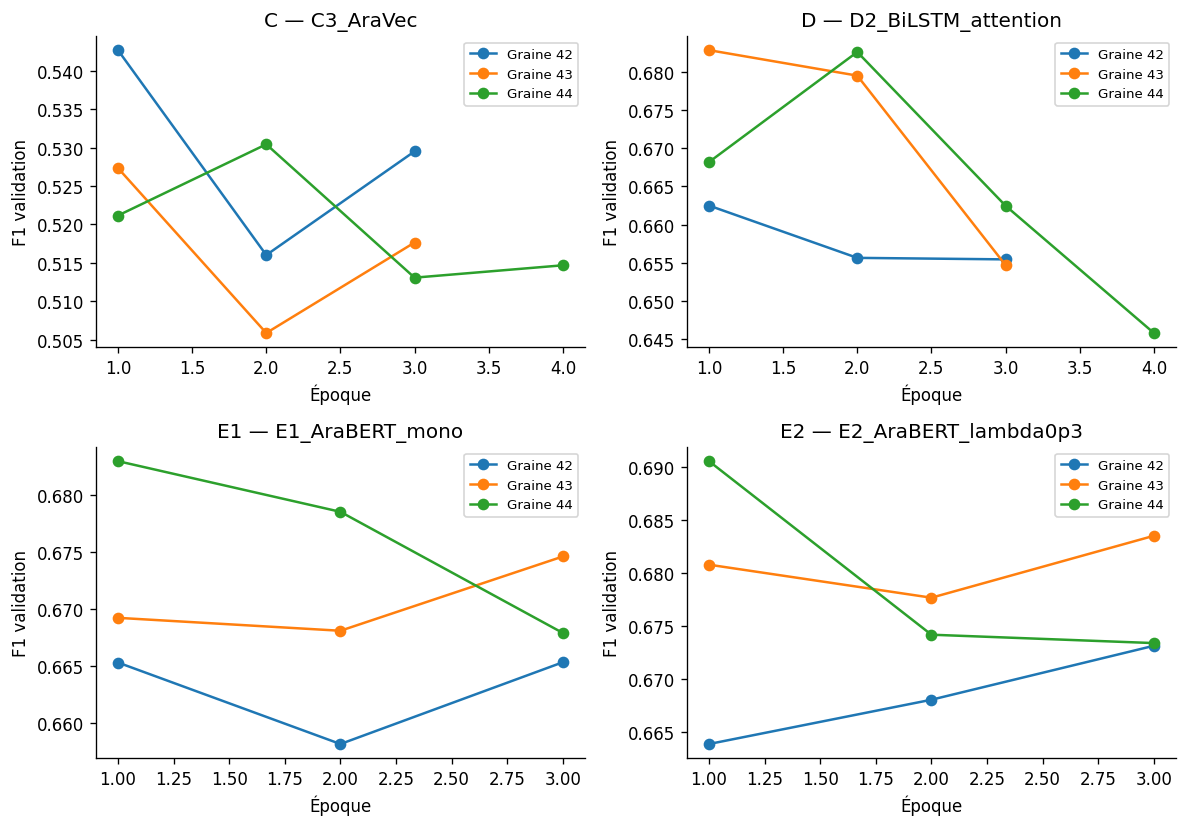

#### Matrice de confusion du modèle retenu

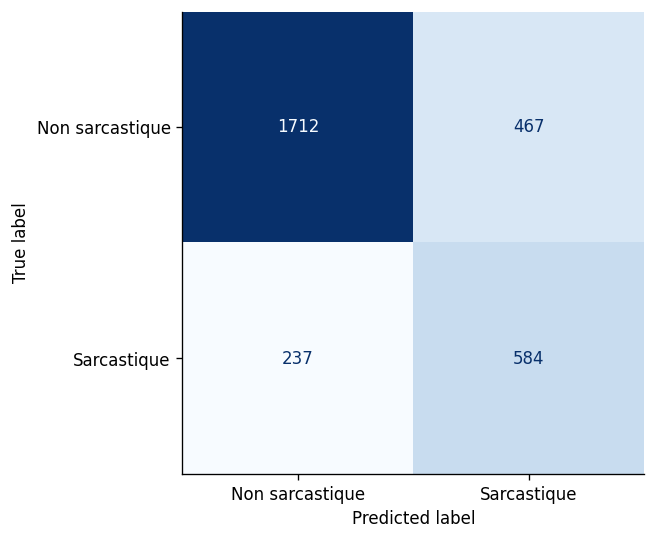

#### Comparaison graphique du F1 test

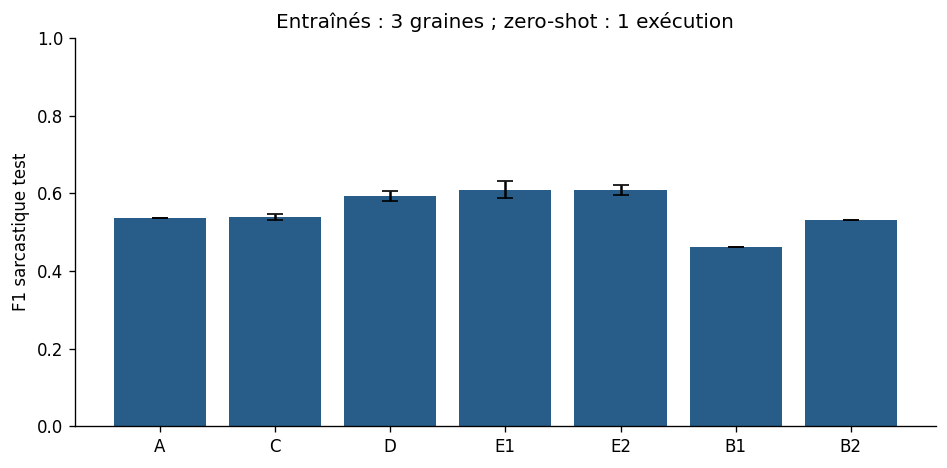

#### Comparaison finale — qualité et latence CPU

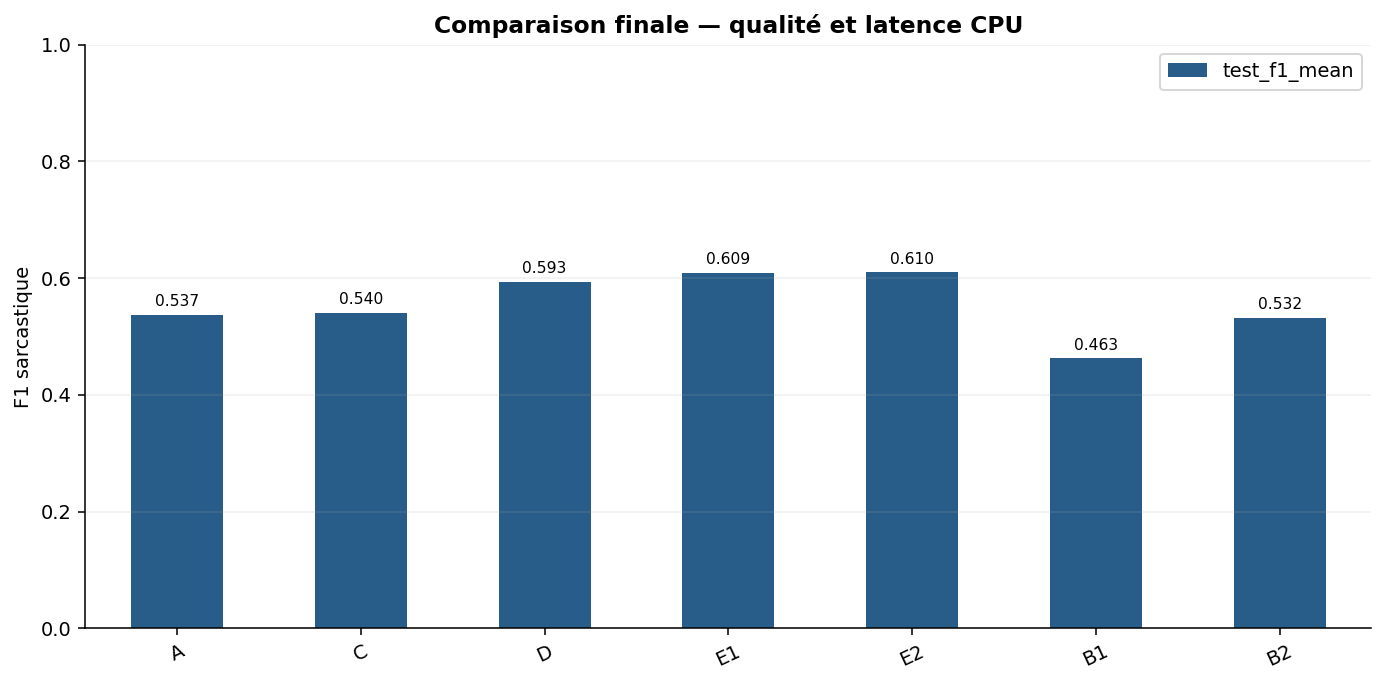

**À présenter :** Les modèles fine-tunés ont les meilleurs F1 moyens, mais E1 et E2 sont presque à égalité. La latence est analysée dans la visualisation suivante.

#### Qualité et coût — F1 contre latence CPU

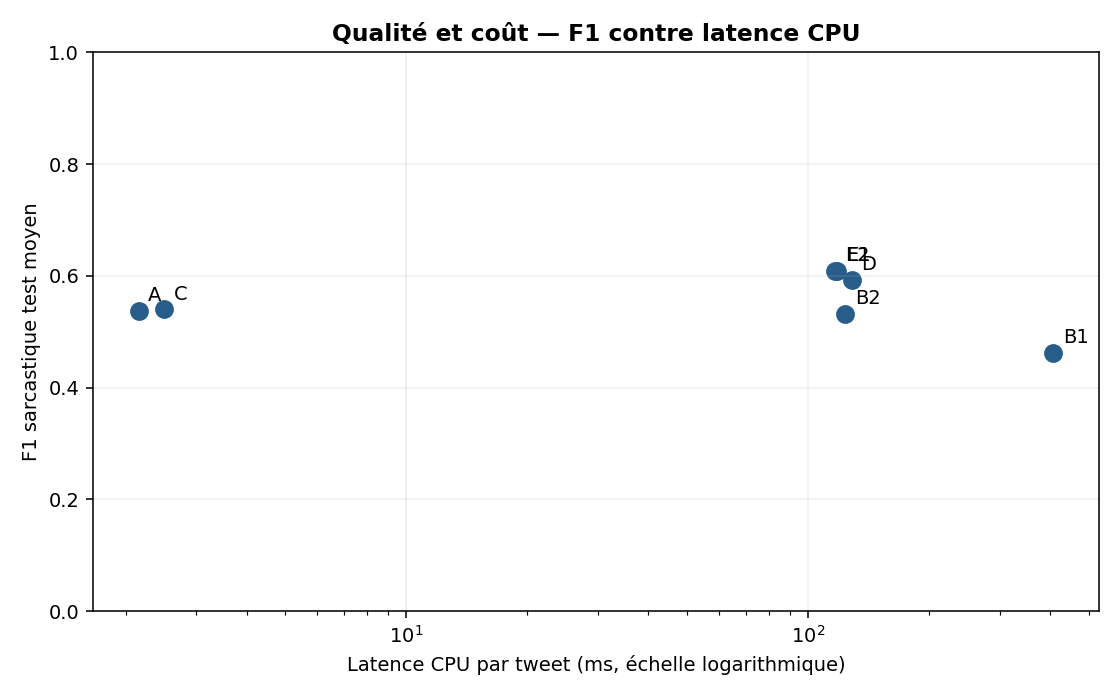

**À présenter :** Vers le haut, le F1 est meilleur ; vers la gauche, le modèle est plus rapide. TF-IDF est nettement plus rapide, tandis que E1/E2 gagnent en qualité. Les temps sont ceux du CPU de la session historique, pas ceux du GPU ni de mon ordinateur.

In [ ]:
_TP2_TABLE_TITLES = ['Qualité, coût et taille des modèles']

comparison=pd.DataFrame(comparison)

comparison.to_csv(ROOT/'results/final_comparison.csv',index=False)

display(comparison.round(4))

history_frame=pd.DataFrame(HISTORY)

fig,axes=plt.subplots(2,2,figsize=(10,7))

for ax,family in zip(axes.flat,['C','D','E1','E2']):
    model_name=REGISTRY[FINAL_GROUPS[family][0]]['name']
    curves=history_frame.loc[history_frame.model.eq(model_name)]
    for seed,curve in curves.groupby('seed'):
        ax.plot(curve.epoch,curve.val_f1,marker='o',label=f'Graine {seed}')
    if len(curves): ax.legend(fontsize=8)
    else: ax.text(.5,.5,'Classifieur linéaire sans époques',ha='center',transform=ax.transAxes)
    ax.set(title=f'{family} — {model_name}',xlabel='Époque',ylabel='F1 validation')

savefig(fig,'learning_curves_final')

fig,ax=plt.subplots(figsize=(6,5))

ConfusionMatrixDisplay.from_predictions(ytest,chosen_pred,display_labels=['Non sarcastique','Sarcastique'],cmap='Blues',ax=ax,colorbar=False)

ax.set_title(f'Modèle retenu sur val : {chosen_final_family} — seuil {chosen_rec["threshold"]:.3f}')

savefig(fig,'chosen_confusion')

fig,ax=plt.subplots(figsize=(8,4))

ax.bar(comparison.family,comparison.test_f1_mean,yerr=comparison.test_f1_std.fillna(0),capsize=5,color='#275D88')

ax.set(ylabel='F1 sarcastique test',title='Entraînés : 3 graines ; zero-shot : 1 exécution',ylim=(0,1))

savefig(fig,'final_comparison')

decision={'chosen_key':CHOSEN_KEY,'family':chosen_final_family,'criterion':'moyenne F1 validation sur trois graines',
          'threshold':chosen_rec['threshold'],'test_metrics':scores(ytest,chosen_p,chosen_rec['threshold']),
          'completed_at_utc':datetime.now(timezone.utc).isoformat()}

# Graphique complémentaire : valeurs de la session courante.
_tp2_plot(comparison.set_index('family')[['test_f1_mean']], 'Comparaison finale — qualité et latence CPU', 'F1 sarcastique', 'presentation_11', unit_interval=True)

fig, ax = plt.subplots(figsize=(8,5))
ax.scatter(comparison.cpu_batch1_latency_ms, comparison.test_f1_mean, s=75, color='#275D88')
for _, row in comparison.iterrows():
    ax.annotate(row['family'], (row.cpu_batch1_latency_ms, row.test_f1_mean), xytext=(5,5), textcoords='offset points')
ax.set(xscale='log', xlabel='Latence CPU par tweet (ms, échelle logarithmique)', ylabel='F1 sarcastique test moyen', title='Qualité et coût — F1 contre latence CPU', ylim=(0,1))
ax.grid(alpha=.2)
savefig(fig, 'presentation_qualite_latence')


### Présenter les résultats — étape 38

**Support 1 — Qualité, coût et taille des modèles**

> « E2 a le meilleur F1 test moyen affiché, 0,6096 ± 0,0131, contre 0,6093 ± 0,0221 pour E1. Cet écart de 0,0003 est trop faible pour affirmer un avantage général du multi-tâche. TF-IDF atteint 0,5369 avec environ 2,15 ms par tweet sur le CPU mesuré, contre 116,63 ms et environ 541 Mo pour E2. Le temps d’ajustement du tableau ne représente pas tout le temps du projet : téléchargement et extraction gelée doivent être considérés séparément. »

**Support 2 — Courbes d’apprentissage C, D, E1 et E2**

> « Chaque panneau montre le F1 validation en fonction de l’époque et chaque courbe correspond à une graine. Je retiens le meilleur checkpoint de validation, pas automatiquement la dernière époque. Les variations entre courbes montrent pourquoi il faut répéter les expériences. »

**Support 3 — Matrice de confusion du modèle retenu**

> « Les lignes représentent les classes réelles et les colonnes les classes prédites. La diagonale contient les bonnes décisions, les deux autres cases les fausses alertes et les sarcasmes manqués. Le run retenu a une précision de 55,57 % et un rappel de 71,13 % pour le sarcasme : il détecte une majorité des sarcasmes, avec un nombre important de fausses alertes. »

**Support 4 — Comparaison graphique du F1 test**

> « La hauteur des barres indique le F1 test moyen. Les barres d’erreur des familles entraînées montrent l’écart-type entre trois graines, pas un intervalle bootstrap. B1 et B2 n’ont qu’une exécution : l’absence de barre d’erreur ne signifie pas absence d’incertitude. E1 et E2 sont très proches, devant D, C et A dans ce tableau. »

**3. Résultat — Visualisation**

Les sorties enregistrées ci-dessus proviennent de l’exécution originale : tableaux, métriques, graphiques ou journaux selon cette étape.

**4. Mon interprétation**

E2 AraBERT atteint un F1 test moyen de 0,6096 ± 0,0131 ; E1 atteint 0,6093. Cet écart très faible ne démontre pas un avantage général du multi-tâche.

### Choix final et exports de prédictions

**1. Explication**

**Objectif :** Enregistrer le modèle choisi, son seuil et les exports.

**Pourquoi cette méthode ?** Conserver la décision permet de réutiliser exactement le même modèle.

**2. Code — Implémentation**

La cellule suivante réalise cette étape.

In [ ]:
_TP2_TABLE_TITLES = []

(ROOT/'results/decision.json').write_text(json.dumps(decision,indent=2),encoding='utf-8')

pd.DataFrame(RESULTS).to_csv(ROOT/'results/results.csv',index=False)

print('Modèle retenu :',CHOSEN_KEY,'seuil',chosen_rec['threshold'])

print('Scores test :',decision['test_metrics'])

print('Toutes les prédictions finales exportées dans predictions/.')

Modèle retenu : E2_AraBERT_lambda0p3_seed42 seuil 0.49078473448753357
Scores test : {'f1_sarcastique': 0.6239316239316239, 'precision': 0.5556612749762131, 'recall': 0.7113276492082826, 'macro_f1': 0.7266944941363547, 'pr_auc_ap': 0.6355033706345491}
Toutes les prédictions finales exportées dans predictions/.


### Présenter les résultats — étape 39

**Phrase de présentation**

> Le modèle retenu sur validation est E2 AraBERT, lambda 0,3, graine 42, au seuil 0,4908. Son F1 test individuel est 0,6239, sa précision 0,5557 et son rappel 0,7113. Je distingue ce run de la moyenne sur trois graines, 0,6096. L’export annoncé concerne la session historique.

**3. Résultat — Visualisation**

Les sorties enregistrées ci-dessus proviennent de l’exécution originale : tableaux, métriques, graphiques ou journaux selon cette étape.

**4. Mon interprétation**

Le run retenu est E2 AraBERT lambda 0,3, graine 42, avec un F1 test de 0,6239. Le message d’export décrit la session historique ; il ne garantit pas la présence locale des fichiers.

### Versions et reproductibilité

**1. Explication**

**Objectif :** Conserver les versions et contrôler la reproductibilité.

**Pourquoi cette méthode ?** Les versions et vérifications documentent les conditions de l’expérience.

**2. Code — Implémentation**

La cellule suivante réalise cette étape.

In [ ]:
_TP2_TABLE_TITLES = ['Contrôles de reproductibilité']

import importlib.metadata as metadata

packages=['torch','transformers','huggingface-hub','safetensors','tokenizers','scikit-learn','numpy','pandas','scipy','gensim','arabert','pyarabic','emoji','sentencepiece','nbformat','ipykernel','matplotlib','joblib','reportlab','pymupdf']

versions={p:metadata.version(p) for p in packages}

(ROOT/'results/runtime_versions.json').write_text(json.dumps(versions,indent=2))

checks={'train_val_disjoint':set(train.key).isdisjoint(val.key),'train_test_disjoint':set(train.key).isdisjoint(test.key),
    'val_test_disjoint':set(val.key).isdisjoint(test.key),
    'test_official_count':len(test)==3000,'three_seeds_per_final_family':all(len(keys)==3 for keys in FINAL_GROUPS.values()),
    'final_prediction_files':all((ROOT/f'predictions/{key}.csv').exists() for key in FINAL_KEYS)}

assert all(checks.values()),checks

(ROOT/'results/validation_checks.json').write_text(json.dumps({'checks':checks,'versions':versions,'python':sys.executable},indent=2))

display(pd.Series(checks).to_frame('Vérifié'))

print('Calcul scientifique terminé. Régénérer le PDF : python -m src.report ; puis python -m tests.verify_final')

#### Contrôles de reproductibilité

,Vérifié
train_val_disjoint,True
train_test_disjoint,True
val_test_disjoint,True
test_official_count,True
three_seeds_per_final_family,True
final_prediction_files,True


Calcul scientifique terminé. Régénérer le PDF : python -m src.report ; puis python -m tests.verify_final


### Présenter les résultats — étape 40

**Support 1 — Contrôles de reproductibilité**

> « Les contrôles enregistrés indiquent des partitions disjointes, le bon effectif test et trois graines par famille finale. Ils décrivent la session T4 d’origine. Pour remettre le projet, je dois aussi récupérer les CSV de prédictions : un message enregistré ne certifie pas leur présence dans le dossier local. »

**3. Résultat — Visualisation**

Les sorties enregistrées ci-dessus proviennent de l’exécution originale : tableaux, métriques, graphiques ou journaux selon cette étape.

**4. Mon interprétation**

Les contrôles enregistrés sont positifs dans la session source. Les checkpoints et CSV exclus de Git restent nécessaires pour reproduire tous les résultats localement.

## Conclusion à présenter

« Les modèles préentraînés améliorent la détection du sarcasme dans cette expérience. AraVec aide les réseaux statiques et le fine-tuning d’AraBERT donne les meilleurs scores test moyens du tableau. Cependant, E1 et E2 restent presque à égalité : je ne peux pas affirmer un gain général du multi-tâche. La baseline TF-IDF garde un intérêt pour sa faible latence. Enfin, les différences entre dialectes, les indices superficiels et le manque de tweets maghrébins limitent la généralisation. Avant un usage sur des tweets marocains, je prévoirais une évaluation dédiée et une analyse humaine des erreurs. »
